# 小さな分子で学ぶ位相推定：H₂/Jordan–Wigner版

**削減なし・系4量子ビット、厳密状態準備、著者実装による時間発展のMPO化と回路最適化。**

既存のH₂/Parity・系1量子ビット教材と節0〜10、記号、**予想 → 実行 → 照合 → 演習＋解答**を揃えた姉妹編です。
同じH₂/STO-3G、核間距離0.735 Å、全2電子・全2空間軌道を使い、今回はS₀,S₁,S₂と最低三重項Tを残します。

学習目標は、①電子配置と厳密固有状態、②QPE/IQPE/BPE/BPDE、③長時間と位相の周期、
④厳密演算子 → 参照MPO → ユニタリ回路という二段階の誤差と推定への影響、を結ぶことです。

- 状態準備は既知の厳密解から作るRy/CNOT回路に固定します。MPS/DMRG・状態準備最適化は行いません。
- 時間発展の二段階はKannoらの**未変更のJuliaコアを実行した結果**です。内部はブラックボックスとし、入出力と検証指標を示します。
- BPE/BPDEの推定更新は既存教材と同じ教育用グリッド法です。著者のGaussian更新を再現するNotebookではありません。
- すべて理想計算・模擬測定です。量子優位性、実機動作、MPO回路の優位性をあらかじめ仮定しません。

初期化セルには埋込みデータと補助関数が含まれるため、ソースを折り畳む設定にしています。
Notebookには分子行列・著者MPOの各コア・最適化後の全ゲート・履歴・出所を内蔵しています。
Juliaやリポジトリの他のファイルなしで全セルを実行できます。付録の分子再生成にPySCFを使います。
必要パッケージはNumPy/SciPy/Matplotlib/Qiskit/pylatexenc/PySCFです。重い著者最適化の再実行手順は付属READMEにあります。

In [1]:
# 必要ならコメントを外し、インストール後にカーネルを再起動してください。
# %pip install "numpy>=1.26,<3" "scipy>=1.12,<2" "matplotlib>=3.8,<4" "qiskit==2.4.1" "pylatexenc>=2.10,<3" "pyscf>=2.7,<3"

In [2]:
import base64, hashlib, io, json, sys
import numpy as np
import matplotlib.pyplot as plt
import qiskit
from IPython.display import display
np.set_printoptions(precision=8,suppress=True)
plt.rcParams.update({'figure.dpi':110,'font.size':10})

def draw(qc,fold=110):
    fig=qc.draw(output='mpl',fold=fold);display(fig);plt.close(fig)

def show():
    plt.tight_layout();plt.show()
"""Small dense verification helpers; optimization itself is the upstream Julia code.
Qiskit little endian, system q0..q3; BPDE ancilla q4.
"""
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm
from qiskit import QuantumCircuit, transpile
from qiskit.circuit.library import UnitaryGate
from qiskit.quantum_info import Operator, Statevector, SparsePauliOp

TAU = 2*np.pi

def state_prep(name, theta):
    qc = QuantumCircuit(4, name=f'prep_{name}')
    if name in ('T+', 'T-'):
        for q in ([0,1] if name == 'T+' else [2,3]):
            qc.ry(np.pi, q)
        return qc
    base, pivot, angle = {
        'S0': (5,1,theta), 'S2': (5,1,theta+np.pi),
        'S1': (6,0,np.pi/2), 'T': (6,0,-np.pi/2),
        'HF': (5,1,0.),
    }[name]
    for q in range(4):
        if base >> q & 1:
            qc.ry(np.pi, q)
    qc.ry(angle, pivot)
    for q in range(4):
        if q != pivot:
            qc.cx(pivot, q)
    return qc

def joint_prep(target, theta):
    """Exactly (|0> S0 + |1> target)/sqrt(2), including relative phase."""
    c = int(target in ('S1','T'))
    angle = {'S2':theta+np.pi, 'S1':np.pi/2, 'T':-np.pi/2}[target]
    qc = QuantumCircuit(5, name=f'joint_S0_{target}')
    # The minus compensates the open-shell encoder's branch phase.
    qc.ry(-np.pi/2 if c else np.pi/2, 4)
    if c:
        qc.cx(4,1)
    # Exact controlled angle selection with two Ry and two CX.
    qc.ry((theta+angle)/2,0); qc.cx(4,0)
    qc.ry((theta-angle)/2,0); qc.cx(4,0)
    # Common reversible encoder: b=q0, c=q1 -> configurations 5/10 or 6/9.
    qc.cx(0,1); qc.cx(0,2); qc.cx(0,3); qc.cx(1,0); qc.cx(2,0)
    qc.ry(np.pi,0); qc.ry(np.pi,2)
    return qc

def spin_operators():
    a=[]
    for q in range(4):
        op=np.zeros((16,16))
        for n in range(16):
            if n>>q&1:
                op[n^(1<<q),n]=(-1)**((n&((1<<q)-1)).bit_count())
        a.append(op)
    number=sum(x.T@x for x in a)
    sz=(a[0].T@a[0]+a[1].T@a[1]-a[2].T@a[2]-a[3].T@a[3])/2
    plus=a[0].T@a[2]+a[1].T@a[3]
    s2=sz@sz+(plus@plus.T+plus.T@plus)/2
    return number, sz, s2

def brickwall(arrays, depth):
    qc=QuantumCircuit(4, name=f'author_d{depth}')
    for layer in range(1,depth+1):
        starts=range(0,3,2) if layer%2 else range(1,3,2)
        for unit,start in enumerate(starts,1):
            gate=arrays[f'h2_d{depth}_MPO_depth{layer}_{unit}']
            np.testing.assert_allclose(gate.conj().T@gate,np.eye(4),atol=1e-10)
            qc.unitary(gate,[start,start+1],label=f'G{layer}.{unit}')
    return qc

def contract_author_mpo(arrays):
    """Actual exported cores; physical axes right,left; site 1 is q0."""
    cores=[arrays[f'reference_core_{j}'] for j in range(1,5)]
    tensor=cores[0]
    for core in cores[1:]:
        tensor=np.tensordot(tensor,core,axes=(-1,0))
    # Julia reshape is column-major: q0 is fastest within each physical group.
    return tensor.transpose(0,2,4,6,1,3,5,7).reshape(16,16,order='F')

def dense_trotter(h,dt,slices=100,order=2):
    p=SparsePauliOp.from_operator(Operator(h),atol=1e-12)
    terms=[(float(c.real), SparsePauliOp(label).to_matrix()) for label,c in zip(p.paulis.to_labels(),p.coeffs)]
    step=np.eye(16,dtype=complex)
    sequence=terms+terms[::-1] if order==2 else terms
    factor=2 if order==2 else 1
    for c,pauli in sequence:
        angle=c*dt/slices/factor
        step=(np.cos(angle)*np.eye(16)-1j*np.sin(angle)*pauli)@step
    return np.linalg.matrix_power(step,slices)

def rel_error(a,b):
    return float(np.linalg.norm(a-b)/np.linalg.norm(b))

def unitary_defect(u):
    return float(np.linalg.norm(u.conj().T@u-np.eye(len(u)))/np.sqrt(len(u)))

def controlled_matrix(u):
    # The first qarg is the low bit: control=0 -> I, control=1 -> U.
    cu=np.eye(2*len(u),dtype=complex)
    cu[1::2,1::2]=u
    return cu

def inverse_qft(m):
    qc=QuantumCircuit(m,name='QFT_dg')
    for j in range(m//2): qc.swap(j,m-1-j)
    for j in range(m):
        for k in range(j): qc.cp(-np.pi/2**(j-k),j,k)
        qc.h(j)
    return qc

def qpe_circuit(prep,u,m=3):
    qc=QuantumCircuit(m+4)
    qc.compose(prep,range(m,m+4),inplace=True)
    for r in range(m):
        qc.h(r)
        qc.append(UnitaryGate(controlled_matrix(np.linalg.matrix_power(u,2**r)),label=f'c-U^{2**r}'),[r]+list(range(m,m+4)))
    qc.compose(inverse_qft(m),range(m),inplace=True)
    return qc

def qpe_distribution(prep,u,m=3):
    return Statevector.from_instruction(qpe_circuit(prep,u,m)).probabilities(range(m))

def qpe_formula(phi,m):
    M=2**m
    return abs(np.mean(np.exp(1j*TAU*np.outer(np.arange(M),phi-np.arange(M)/M)),axis=0))**2

def iqpe_tree(psi,u,m=3,reprepare=False):
    branches=[(0,1.,np.asarray(psi,complex))]
    for ell,r in enumerate(reversed(range(m))):
        up=np.linalg.matrix_power(u,2**r);new=[]
        for y,weight,state in branches:
            incoming=psi if reprepare else state
            beta=-TAU*2**r*y/2**m
            for bit in (0,1):
                out=(incoming+(-1)**bit*np.exp(1j*beta)*up@incoming)/2
                prob=float(np.vdot(out,out).real)
                if prob>1e-14: new.append((y+bit*2**ell,weight*prob,out/np.sqrt(prob)))
        branches=new
    p=np.zeros(2**m)
    for y,w,_ in branches: p[y]+=w
    return p

def iqpe_dynamic(prep,u,m=3):
    from qiskit import QuantumRegister,ClassicalRegister
    a=QuantumRegister(1,'a');s=QuantumRegister(4,'s');c=ClassicalRegister(m,'bits')
    qc=QuantumCircuit(a,s,c);qc.compose(prep,s,inplace=True)
    for ell,r in enumerate(reversed(range(m))):
        if ell: qc.reset(a[0])
        qc.h(a[0]);qc.append(UnitaryGate(controlled_matrix(np.linalg.matrix_power(u,2**r)),label=f'c-U^{2**r}'),[a[0]]+list(s))
        for old in range(ell):
            with qc.if_test((c[old],1)): qc.p(-TAU*2**r*2**old/2**m,a[0])
        qc.h(a[0]);qc.measure(a[0],c[ell])
    return qc

def bpe_circuit(prep,u,L=1,beta=0):
    qc=QuantumCircuit(5);qc.compose(prep,range(4),inplace=True);qc.h(4)
    qc.append(UnitaryGate(controlled_matrix(np.linalg.matrix_power(u,L)),label=f'c-U^{L}'),[4,0,1,2,3])
    qc.p(beta,4);qc.h(4)
    return qc

def bpe_probability(psi,u,L,beta):
    amp=np.vdot(psi,np.linalg.matrix_power(u,L)@psi)
    return float((1+np.real(np.exp(1j*beta)*amp))/2)

def bpde_circuit(target,theta,u,L=1,beta=0):
    prep=joint_prep(target,theta)
    qc=prep.copy()
    qc.unitary(np.linalg.matrix_power(u,L),range(4),label=f'U^{L}')
    qc.p(beta,4);qc.compose(prep.inverse(),inplace=True)
    return qc

def bpde_probability(target,theta,u,L,beta,all_zero=True):
    vector=Statevector.from_instruction(bpde_circuit(target,theta,u,L,beta)).data
    return float(abs(vector[0])**2 if all_zero else sum(abs(vector[:16])**2))

def single_phase(phi,L,beta):
    return .5*(1+np.cos(TAU*L*np.asarray(phi)+beta))

def bayes(grid,settings,probability,shots=256,seed=20261108,expected=False):
    rng=np.random.default_rng(seed);logp=np.zeros_like(grid);history=[];records=[]
    for L,beta in settings:
        truth=float(np.clip(probability(L,beta),0,1))
        n0=shots*truth if expected else int(rng.binomial(shots,truth))
        p=np.clip(single_phase(grid,L,beta),1e-12,1-1e-12)
        logp+=n0*np.log(p)+(shots-n0)*np.log1p(-p);logp-=max(logp)
        post=np.exp(logp);post/=post.sum();history.append(post)
        records.append((L,beta,n0,shots,truth))
    return np.asarray(history),records

def summary(grid,p):
    lo,hi=np.interp([.025,.975],np.cumsum(p),grid)
    return float(grid[np.argmax(p)]),float(lo),float(hi)

def time_comparison(probability,target,label,seed=42):
    grid=(np.arange(32768)+.5)/32768
    plans={'L=1':[1]*6,'Staged':[1,2,4,8,16,32],'L=32':[32]*6}
    fig,axes=plt.subplots(2,3,figsize=(12,6))
    results={}
    for k,(name,lengths) in enumerate(plans.items()):
        settings=[(L,b) for L in lengths for b in [np.pi/5,np.pi/5-np.pi/2]]
        hist,records=bayes(grid,settings,probability,seed=seed+k)
        est,lo,hi=summary(grid,hist[-1]);widths=[summary(grid,p)[2]-summary(grid,p)[1] for p in hist[1::2]]
        for row in (0,1):
            axes[row,k].plot(grid,hist[-1]*len(grid));axes[row,k].axvline(target,c='C3',ls='--')
            axes[row,k].set(xlabel='Phase',ylabel='Posterior density',title=name)
        axes[1,k].set_xlim(target-.025,target+.025)
        print(name,'shots=',256*len(settings),'sum(R L)=',256*sum(lengths)*2,'MAP=',est,'95% width=',hi-lo)
        results[name]=(settings,hist,widths)
    fig.suptitle(label);plt.tight_layout();plt.show()
    fig,ax=plt.subplots(figsize=(7,3))
    for name,(_,_,widths) in results.items(): ax.semilogy(np.arange(1,7)*512,widths,'o-',label=name)
    ax.set(xlabel='Cumulative shots',ylabel='Global 95% interval width',title=label);ax.legend();plt.show()
    # L=32 aliases are exactly unresolved for the uniform prior.
    np.testing.assert_allclose(results['L=32'][1][-1].reshape(32,-1).sum(axis=1),1/32,atol=1e-9)
    for k,name in enumerate(['L=1','Staged']):
        settings=results[name][0];rng=np.random.default_rng(seed+100+k)
        probs=[probability(L,b) for L,b in settings]
        counts=rng.binomial(256,np.clip(probs,0,1),size=(64,len(settings)))
        model=np.array([np.clip(single_phase(grid,L,b),1e-12,1-1e-12) for L,b in settings])
        logp=counts@np.log(model)+(256-counts)@np.log1p(-model);logp-=logp.max(axis=1,keepdims=True)
        post=np.exp(logp);post/=post.sum(axis=1,keepdims=True)
        estimates=grid[np.argmax(post,axis=1)]
        err=(estimates-target+.5)%1-.5
        print(name,'64-trial circular RMSE=',np.sqrt(np.mean(err**2)))
    return results

def exact_two_qubit_synthesis(matrix):
    """Avoid default KAK specialization tolerances; preserve the input global phase.
    Try 0/1/2/3 CX decompositions of the unspecialized Weyl target, accept only
    a matrix-verified representation. This changes compilation, not optimization.
    """
    from qiskit.circuit.library import CXGate
    from qiskit.synthesis import TwoQubitBasisDecomposer, TwoQubitWeylDecomposition, OneQubitEulerDecomposer
    target=TwoQubitWeylDecomposition(matrix,fidelity=None)
    decomposer=TwoQubitBasisDecomposer(CXGate(),basis_fidelity=1.,euler_basis='ZSX',pulse_optimize=False)
    euler=OneQubitEulerDecomposer('ZSX')
    methods=[decomposer.decomp0,decomposer.decomp1,decomposer.decomp2_supercontrolled,decomposer.decomp3_supercontrolled]
    for count,method in enumerate(methods):
        locals_=method(target._inner_decomposition)
        circuit=QuantumCircuit(2)
        for pair in range(count+1):
            circuit.compose(euler(locals_[2*pair],simplify=False),[0],inplace=True)
            circuit.compose(euler(locals_[2*pair+1],simplify=False),[1],inplace=True)
            if pair<count:circuit.cx(0,1)
        actual=Operator(circuit).data
        # Correct the circuit's phase itself; the error metric never discards phase.
        circuit.global_phase+=float(np.angle(np.trace(actual.conj().T@matrix)))
        if np.max(abs(Operator(circuit).data-matrix))<2e-11:
            return circuit
    raise AssertionError('Exact two-qubit synthesis did not preserve its matrix')

def compile_exact(qc):
    expanded=QuantumCircuit(qc.num_qubits)
    expanded.global_phase=qc.global_phase
    for instruction in qc.data:
        qargs=[qc.find_bit(q).index for q in instruction.qubits]
        if instruction.operation.name=='unitary' and len(qargs)==2:
            expanded.compose(exact_two_qubit_synthesis(instruction.operation.to_matrix()),qargs,inplace=True)
        else:
            expanded.append(instruction.operation,qargs)
    compiled=transpile(expanded,basis_gates=['rz','sx','x','cx'],optimization_level=1,seed_transpiler=7)
    np.testing.assert_allclose(Operator(compiled).data,Operator(qc).data,atol=1e-10)
    return compiled
"""Controlled, fixed-budget precision comparisons. No circuit re-optimization."""
import numpy as np
from scipy.optimize import minimize_scalar
from scipy.linalg import schur
from qiskit import transpile
from qiskit.quantum_info import Operator
from qiskit.transpiler import CouplingMap

PRECISION_PLANS = {
    'Lmax256': [1,2,4,8,16,32,64,128,256],
    'Lmax4096': [1,4,8,16,64,256,512,1024,4096],
    'Lmax16384': [1,4,16,32,128,512,1024,4096,16384],
}
PRECISION_BETAS = [np.pi/5,np.pi/5-np.pi/2]
PRECISION_PAIRS = [('S0','T'),('S0','S1'),('S0','S2'),('T','S1'),('T','S2'),('S1','S2')]

def line_resource(qc, exact_compiler):
    """Bidirectional q0-q1-q2-q3, fixed input mapping and restored output mapping."""
    compiled=exact_compiler(qc)
    line=transpile(compiled,basis_gates=['rz','sx','x','cx'],
        coupling_map=CouplingMap.from_line(4,bidirectional=True),initial_layout=[0,1,2,3],
        layout_method='trivial',routing_method='sabre',optimization_level=1,seed_transpiler=7)
    raw_count=int(line.count_ops().get('cx',0))
    permutation=line.layout.final_index_layout()
    at=list(np.argsort(permutation));restore_swaps=0
    for target in range(4):
        pos=at.index(target)
        while pos>target:
            line.cx(pos-1,pos);line.cx(pos,pos-1);line.cx(pos-1,pos)
            at[pos-1],at[pos]=at[pos],at[pos-1];pos-=1;restore_swaps+=1
    np.testing.assert_allclose(Operator(line).data,Operator(qc).data,atol=1e-10)
    assert all(abs(line.find_bit(i.qubits[0]).index-line.find_bit(i.qubits[1]).index)==1
               for i in line.data if i.operation.name=='cx')
    return {'cx_all_to_all':int(compiled.count_ops().get('cx',0)),
        'cx_layers_all_to_all':int(compiled.depth(lambda i:i.operation.name=='cx')),
        'cx_line_before_restoration':raw_count,'output_permutation_before_restoration':permutation,
        'restoration_swaps':restore_swaps,'cx_line_fixed_mapping':int(line.count_ops().get('cx',0)),
        'cx_layers_line_fixed_mapping':int(line.depth(lambda i:i.operation.name=='cx')),
        'matrix_compilation_error':float(np.linalg.norm(Operator(line).data-Operator(qc).data)/4)}

def pair_preparation(left,right,theta):
    """Generalize the verified exact Ry/CX encoder to any pair of the four states."""
    from qiskit import QuantumCircuit
    angles={'S0':theta,'S2':theta+np.pi,'S1':np.pi/2,'T':-np.pi/2}
    c0=int(left in ('S1','T'));c1=int(right in ('S1','T'))
    a0,a1=angles[left],angles[right]
    qc=QuantumCircuit(5,name=f'joint_{left}_{right}')
    qc.ry(np.pi/2 if c0==c1 else -np.pi/2,4)
    if c0:qc.ry(np.pi,1)
    if c0!=c1:qc.cx(4,1)
    qc.ry((a0+a1)/2,0);qc.cx(4,0);qc.ry((a0-a1)/2,0);qc.cx(4,0)
    qc.cx(0,1);qc.cx(0,2);qc.cx(0,3);qc.cx(1,0);qc.cx(2,0)
    qc.ry(np.pi,0);qc.ry(np.pi,2)
    qc.global_phase=np.pi*c0
    return qc

def _refine_mle(grid,loglike,counts,shots,times,betas):
    index=int(np.argmax(loglike));step=float(grid[1]-grid[0]);center=grid[index]
    def objective(value):
        p=np.clip(.5*(1+np.cos(betas-value*times)),1e-12,1-1e-12)
        return -float(np.sum(counts*np.log(p)+(shots-counts)*np.log1p(-p)))
    result=minimize_scalar(lambda delta:objective(center+delta),bounds=(max(grid[0]-center,-2*step),min(grid[-1]-center,2*step)),
                           method='bounded',options={'xatol':1e-13,'maxiter':100})
    assert result.success
    return float(center+result.x)

def inference_case(probabilities,lengths,true_value,kind,dt,shots=512,trials=256,seed=9001):
    """Same prior, likelihood, shots and time plan for all dynamical implementations.
    Coarse full-prior search + continuous local MLE removes the old 1.92 mHa grid floor.
    The MC interval is the central range of estimates, not a Bayesian credible interval.
    """
    settings=[(L,b) for L in lengths for b in PRECISION_BETAS]
    times=np.array([L*dt for L,b in settings]);betas=np.array([b for L,b in settings])
    bounds=(-2.,0.) if kind=='energy' else (0.,2.)
    size=max(8193,4*max(lengths)+1)
    grid=np.linspace(*bounds,size)
    model=np.clip(.5*(1+np.cos(betas[:,None]-times[:,None]*grid[None,:])),1e-12,1-1e-12)
    logp=np.log(model);logq=np.log1p(-model)
    p=np.clip(np.asarray(probabilities),0,1)
    expected_counts=shots*p
    expected_ll=expected_counts@logp+(shots-expected_counts)@logq
    expected_mle=_refine_mle(grid,expected_ll,expected_counts,shots,times,betas)
    rng=np.random.default_rng(seed)
    counts=rng.binomial(shots,p,size=(trials,len(settings)))
    likelihoods=counts@logp+(shots-counts)@logq
    estimates=np.array([_refine_mle(grid,ll,row,shots,times,betas) for ll,row in zip(likelihoods,counts)])
    # Independent full-grid search at twice the density, for the expected-count maximum.
    dense_grid=np.linspace(*bounds,2*size-1)
    pp=np.clip(.5*(1+np.cos(betas[:,None]-times[:,None]*dense_grid[None,:])),1e-12,1-1e-12)
    dense_ll=expected_counts@np.log(pp)+(shots-expected_counts)@np.log1p(-pp)
    dense_mle=_refine_mle(dense_grid,dense_ll,expected_counts,shots,times,betas)
    assert abs(expected_mle-dense_mle)<2e-8,(expected_mle,dense_mle)
    error=estimates-true_value
    info=float(np.sum(shots*times**2))
    result={'expected_mle':expected_mle,'systematic_bias':expected_mle-true_value,
        'mc_mean':float(np.mean(estimates)),'mc_bias':float(np.mean(error)),
        'mc_std':float(np.std(estimates,ddof=1)),'mc_rmse':float(np.sqrt(np.mean(error**2))),
        'mc_estimate_95_range':np.quantile(estimates,[.025,.975]).tolist(),
        'single_realization':float(estimates[0]),'local_ideal_fisher_sigma':float(1/np.sqrt(info)),
        'coarse_grid_points':size,'refinement_double_grid_difference':abs(expected_mle-dense_mle)}
    return result,estimates

def run_precision(h,enuc,dt,states,operators,trials=256,progress=None):
    energies={name:float(np.vdot(state,h@state).real) for name,state in states.items()}
    rows=[];samples={};long_rows=[];spectral=[]
    all_lengths=sorted(set(L for plan in PRECISION_PLANS.values() for L in plan))
    for method,u in operators.items():
        powers={L:np.linalg.matrix_power(u,L) for L in all_lengths}
        amplitudes={s:{L:np.vdot(v,powers[L]@v) for L in all_lengths} for s,v in states.items()}
        tmat,basis=schur(u,output='complex')
        np.testing.assert_allclose(tmat,np.diag(np.diag(tmat)),atol=1e-10)
        for s,v in states.items():
            weights=abs(basis.conj().T@v)**2;index=int(np.argmax(weights));phase=np.angle(tmat[index,index])
            same_phase=abs(np.angle(np.diag(tmat)*np.exp(-1j*phase)))<1e-8
            spectral.append({'method':method,'state':s,'dominant_energy_shift':-phase/dt-energies[s],
                             'dominant_phase_weight':float(sum(weights[same_phase]))})
        for L in [1,32,256,1024,4096,16384]:
            a=np.linalg.matrix_power(u,L)
            # Use the known H only to score, never to choose a grid location or starting estimate.
            from scipy.linalg import expm
            exact=expm(-1j*h*dt*L)
            for s,v in states.items():
                amp=np.vdot(v,a@v)
                phase=np.angle(amp*np.exp(1j*energies[s]*L*dt))
                long_rows.append({'method':method,'L':L,'t':L*dt,'state':s,
                    'operator_relative_error':float(np.linalg.norm(a-exact)/4),
                    'phase_error_rad':float(phase),'phase_energy_shift':float(-phase/(L*dt)),
                    'survival_loss':float(1-abs(amp)**2),
                    'state_error_norm':float(np.linalg.norm(a@v-np.exp(-1j*energies[s]*L*dt)*v))})
        for plan_name,lengths in PRECISION_PLANS.items():
            settings=[(L,b) for L in lengths for b in PRECISION_BETAS]
            targets=[('energy',s,None) for s in ['S0','S1','S2','T']]+[('gap',lo,hi) for lo,hi in PRECISION_PAIRS]
            for target_index,(kind,lo,hi) in enumerate(targets):
                target=lo if kind=='energy' else f'{hi}-{lo}'
                true=energies[lo] if kind=='energy' else energies[hi]-energies[lo]
                if kind=='energy':
                    probs=[.5*(1+np.real(np.exp(1j*b)*amplitudes[lo][L])) for L,b in settings]
                else:
                    probs=[abs(amplitudes[lo][L]+np.exp(1j*b)*amplitudes[hi][L])**2/4 for L,b in settings]
                result,est=inference_case(probs,lengths,true,kind,dt,trials=trials,seed=9001+target_index)
                offset=enuc if kind=='energy' else 0.
                for field in ['expected_mle','mc_mean','single_realization']:result[field]+=offset
                result['mc_estimate_95_range']=[x+offset for x in result['mc_estimate_95_range']]
                rows.append({'method':method,'plan':plan_name,'kind':kind,'target':target,'true_value':true+offset,**result})
                samples[f'{method}_{plan_name}_{target}']=est+offset
            if progress:progress(f'{method} {plan_name}: 4 energies + 6 direct gaps passed')
    return {'settings':{'dt':dt,'shots_per_setting':512,'settings_per_plan':18,'shots_per_target':9216,
        'mc_trials':trials,'energy_prior_electronic':[-2,0],'gap_prior':[0,2],
        'plans':PRECISION_PLANS,'betas':PRECISION_BETAS,'MC_seed_base':9001,
        'estimator':'global coarse-prior likelihood search + bounded continuous local MLE',
        'readout':'BPE ancilla0 for energies; Fig1C all-zero direct BPDE for all six gaps',
        'exact_preparation':'fixed analytic Ry/CX; T means Ms=0',
        'plan_resources':{name:{'Lmax':max(plan),'tmax':dt*max(plan),'sum_shots_L':512*2*sum(plan),
            'sum_shots_time':512*2*sum(plan)*dt} for name,plan in PRECISION_PLANS.items()}},
        'inference':rows,'long_time':long_rows,'spectral':spectral},samples

PAYLOAD = '...'
assert hashlib.sha256(base64.b64decode(PAYLOAD)).hexdigest() == '1fc75ba65ba8059aa9d2adb392ce28112cc49165396e2fb2743a7b1c8db246fe'
with np.load(io.BytesIO(base64.b64decode(PAYLOAD)),allow_pickle=False) as loaded:
    DATA={key:loaded[key].copy() for key in loaded.files}
PROVENANCE=json.loads('{"upstream_url": "https://github.com/sk888ks/TQPDE_open", "upstream_commit": "9cd88464c5c50dda783150661813609092d7f2b6", "license": "LGPL-3.0", "upstream_core_sha256": "4b643396638cd85cbddef616d8fdfc6b663ed2bbea39e3eee4e2ffa4381423a8", "upstream_core_byte_identical": true, "julia": "julia version 1.11.1", "ITensors": "0.6.16", "PyCall": "1.96.4", "Infiltrator": "1.7.0", "python": "3.12.7", "numpy": "2.4.6", "scipy": "1.18.0", "qiskit": "2.4.1", "reference_orientation": "raw author reference is U_adjoint; use conjugate transpose for physical evolution", "settings": {"dt": 0.1, "trotter_slices": 100, "svd_cutoff": 1e-12, "depths": [2, 4, 8], "baseline_sweeps": 1000, "random_initialization": true, "baseline_seed": 1, "convergence": {"criterion": {"check_interval": 1000, "absolute_error_improvement": 1e-08, "relative_error_improvement": 0.001, "consecutive_windows": 3, "history_error_definition": "sqrt((16+norm(Mref)^2-2 ReTr(Mref_dagger U))/16)"}, "seeds": [1, 2, 3, 4, 5], "selected": {"2": {"depth": 2, "seed": 2, "sweeps": 4000, "converged": true, "stable_windows": 3, "vs_mpo": 0.03078984365889147, "vs_exact": 0.03078967983824234, "unitarity_defect": 4.927020017971436e-16, "two_qubit_blocks": 3, "cx_all_to_all": 6, "depth_all_to_all": 29, "last_window_improvement": 0.0, "last_window_relative_improvement": 0.0, "median_vs_exact": 0.03078967983824235, "range_vs_exact": [0.03078967983824234, 0.03078967983824235]}, "4": {"depth": 4, "seed": 5, "sweeps": 12000, "converged": true, "stable_windows": 3, "vs_mpo": 0.024030353204007676, "vs_exact": 0.024030320939226555, "unitarity_defect": 2.310921333829117e-15, "two_qubit_blocks": 6, "cx_all_to_all": 18, "depth_all_to_all": 77, "last_window_improvement": 2.998925465597102e-09, "last_window_relative_improvement": 1.247973943537397e-07, "median_vs_exact": 0.024030450045867895, "range_vs_exact": [0.024030320939226555, 0.024030500634670198]}, "8": {"depth": 8, "seed": 5, "sweeps": 80000, "converged": true, "stable_windows": 3, "vs_mpo": 1.9410948714532575e-05, "vs_exact": 1.2516264859010253e-05, "unitarity_defect": 4.197115695939029e-15, "two_qubit_blocks": 12, "cx_all_to_all": 36, "depth_all_to_all": 149, "last_window_improvement": 1.8130142976784157e-09, "last_window_relative_improvement": 9.340137019849855e-05, "median_vs_exact": 0.00019864069604325906, "range_vs_exact": [1.2516264859010253e-05, 0.00027011875486450816]}}, "all_converged": false, "selected_converged": true, "screening_budget_sweeps": 150000}}, "differences": "External convergence/checkpoint driver around unchanged upstream initializers/environments/SVD sweeps; H2 and blocked spin order; exact Ry/CX preparation; educational grid inference, not author Gaussian updates; no QPU/Fire Opal.", "sha256": {"data/h2.npz": "dee8fa4d7b11673bec70cbf8e9dc2fc010ce922ae7b5f4d0a5b58a9a3a4b07ae", "runtime/Gate_generation_from_MPS_MPO.jl": "4b643396638cd85cbddef616d8fdfc6b663ed2bbea39e3eee4e2ffa4381423a8", "runtime/input.jl": "173d23648c201fd7945bef789a80fa6dc951fa041ca7f3d86d20cd329bb57bc8", "tools/run_author.jl": "98a2126ef0cbd18e3a4f25bf0de26fd70435c45010f9009e393c5f9ec8902c2e", "results/convergence/d2_seed1_MPO_depth1_1.npy": "99fed94c23dc18db0c340620549af5a5a1a93aff65feb7625ac2da31626acb79", "results/convergence/d2_seed1_MPO_depth1_2.npy": "a5c4ef3cfd39e612bc2388d2498fc1f9ae94d307a6d044fa444a536f66d80d76", "results/convergence/d2_seed1_MPO_depth2_1.npy": "240b5d71c852df69ceb41da768b548d7ed8905d67798a792ad67735b3e64c286", "results/convergence/d2_seed1_cost.npy": "0c83c78dab69fc168671c207f0664aaeb18abaa5ac36d64270095353864e3bd7", "results/convergence/d2_seed1_error_history.npy": "5bf85e035a0e3aa01737b64cca22cfbc0310c2ef64a7e09c3dc3b0030adb4f91", "results/convergence/d2_seed1_status.npy": "008226b2074519301dae74fc62e5e4a23682e8c232a96a91eacc9066f4cff953", "results/convergence/d2_seed2_MPO_depth1_1.npy": "1624830a150a6ece19d4fe26f552a5bfe1d2d9e8df7f00a663925fac9d618460", "results/convergence/d2_seed2_MPO_depth1_2.npy": "826fff277f6a2d0d9375d4a9e71f34ffbca1747ee1aa64a5948e44cbe749fe5e", "results/convergence/d2_seed2_MPO_depth2_1.npy": "30f2cc99251a644b4951ebd0f45dc61a3bb0d2462d0fad921a051a1353c13ce8", "results/convergence/d2_seed2_cost.npy": "d3a15780383211b23933a2c0a18340a29c5d38da1ea567b5551d4c0ebe2eaa91", "results/convergence/d2_seed2_error_history.npy": "146d62576b560cee97ba1b510a1e16f0725be495ebc618e756601064b21f1799", "results/convergence/d2_seed2_status.npy": "008226b2074519301dae74fc62e5e4a23682e8c232a96a91eacc9066f4cff953", "results/convergence/d2_seed3_MPO_depth1_1.npy": "5943f6e1ba629832c470f17475bac177c268f40dd6f75f83f73c707d00623964", "results/convergence/d2_seed3_MPO_depth1_2.npy": "a937951a6492c2378e0e43f460a9c7e5ca535b9167ac09a22b17c43a43092c1f", "results/convergence/d2_seed3_MPO_depth2_1.npy": "313c9f07fe0a3ea64b8ac432e55182bfdb1b99d1ed81f5c8cba6ddb03149eccb", "results/convergence/d2_seed3_cost.npy": "87b41b6eeb8e258346e403144785cf8b9eb906b8383fca348a003ebcb194f02a", "results/convergence/d2_seed3_error_history.npy": "db502773ba06de7d373799e9d4f4d4e2117d7d355c5249c6983cf80ba3ce4a9b", "results/convergence/d2_seed3_status.npy": "008226b2074519301dae74fc62e5e4a23682e8c232a96a91eacc9066f4cff953", "results/convergence/d2_seed4_MPO_depth1_1.npy": "6ccf376c0284855f1d0d02352b3293f017c4732c63e45fd4cfaa70bff0fa9631", "results/convergence/d2_seed4_MPO_depth1_2.npy": "5a0fcfa45c8dff9f5b450ce350d9e0bb9429c0c8189b045e43edf742a69e56a7", "results/convergence/d2_seed4_MPO_depth2_1.npy": "29819436c8a98e94c4d04488667f895bf609437ec865bbac66f190655f92e163", "results/convergence/d2_seed4_cost.npy": "69776fe6af583e614e6adf7ba1ceb8fb2f0ec6387a87fca1f237de571f2e7b8c", "results/convergence/d2_seed4_error_history.npy": "4c1d5b08a78c966a682efc0998660ef82b1e06b585ab0d52c944da857cb16fcb", "results/convergence/d2_seed4_status.npy": "008226b2074519301dae74fc62e5e4a23682e8c232a96a91eacc9066f4cff953", "results/convergence/d2_seed5_MPO_depth1_1.npy": "9a0c40cc7ec4e57353873c9fa41e30764e35c844973f89a6558ddfb8d49d8a87", "results/convergence/d2_seed5_MPO_depth1_2.npy": "b666a5931212d5d3c0580d51b22c874721ae33927607812f781177d5e081b783", "results/convergence/d2_seed5_MPO_depth2_1.npy": "da86f13da8e152225e8b5d49f67e8cfc487766380d84ad8018acbac0f0eb9cff", "results/convergence/d2_seed5_cost.npy": "dcf2d720f598ad0767bdc1fd6a89fba8d3b194d74c6251e4b826424d42afcb5e", "results/convergence/d2_seed5_error_history.npy": "98456cbe852507dc25f5459923476113c3b00772bf760a755a5351ba6263ba54", "results/convergence/d2_seed5_status.npy": "008226b2074519301dae74fc62e5e4a23682e8c232a96a91eacc9066f4cff953", "results/convergence/d4_seed1_MPO_depth1_1.npy": "e2c909ddcc5c25dd5bbf0df44a03b8db7df31ac5b5a380ac12c5be6496fccf65", "results/convergence/d4_seed1_MPO_depth1_2.npy": "9ec325ea033a4e121f5ee9477ac3269e6e5695aa5d7c1b53c248d10f2e677838", "results/convergence/d4_seed1_MPO_depth2_1.npy": "7518d9882fa2cb4c6a91b6a078d74574f319678889bbd60d148c31560d752845", "results/convergence/d4_seed1_MPO_depth3_1.npy": "4895ff81bb7b92dfe6ff49acc4e8cabf63834effebb11e6557c79960259b1871", "results/convergence/d4_seed1_MPO_depth3_2.npy": "008c4fe80fba9b8892c0aea4bd60f0ce2cf7bf6b17545bf3aa697d852260fcfa", "results/convergence/d4_seed1_MPO_depth4_1.npy": "0ec2e5c24dca1f693e3bd8b0fb74654dd7af971facad6a14cd76623ae990886d", "results/convergence/d4_seed1_cost.npy": "96fe4789c5c8b44bb5e38865f5c13c08609ee22afaee638e6fbe9fe317a54e21", "results/convergence/d4_seed1_error_history.npy": "fc1f34bd9b19a68840fd881129a4a25a06777261579b9563af9f69d4dbaf4d96", "results/convergence/d4_seed1_status.npy": "2400c8272fca13a37fb3f08ad78a66da1a8703668bd478c518d7301c84740072", "results/convergence/d4_seed2_MPO_depth1_1.npy": "1d122e4481b9571f6f3ff803f92aaf11f8776d9909f2f5494e39e8a2bc639a1d", "results/convergence/d4_seed2_MPO_depth1_2.npy": "a6347b032db7495542873915bdb0283fb38a485acb0824d7655832178001dc16", "results/convergence/d4_seed2_MPO_depth2_1.npy": "ef830d9789e8de1f7ff1693d5afbe3f4816b63ad941b93475217f169952d081c", "results/convergence/d4_seed2_MPO_depth3_1.npy": "3b9feea10e6a3fa68656d1ac893960813191ddee4a3a8ecad397178375cee72f", "results/convergence/d4_seed2_MPO_depth3_2.npy": "4a32b1e0ec2cf6bbfdc2537728468ea48bf1f9b9d048a70c952f28230d92edb5", "results/convergence/d4_seed2_MPO_depth4_1.npy": "b4243b33efb4d77f9a95e72f71380d1085f69219e95b76f4baf26cabbed4227d", "results/convergence/d4_seed2_cost.npy": "fd45a8b35b9975abd403f7dc0c691123be17d42d2fe2ee726c8a71d2c67b1d1e", "results/convergence/d4_seed2_error_history.npy": "be463b27f95ba06632830dd7160db81a7ab7f416ee7b23dde955190bab474463", "results/convergence/d4_seed2_status.npy": "620445ffcb685e3fff7810c5941aaba3012b12fe168fd25160d707de5e7aefb1", "results/convergence/d4_seed3_MPO_depth1_1.npy": "1ca1022996fb9f2bb2d5886396d408a1c912fe185b632a3b7467e537da9cc115", "results/convergence/d4_seed3_MPO_depth1_2.npy": "1b3a9d40c1d1427bafef31e4e99c6341ed92f5e82a5613771e4b774b84c14b81", "results/convergence/d4_seed3_MPO_depth2_1.npy": "16d826cd1928f23ef8e2b6af980630584f93ef892497d3ba8a14919425323244", "results/convergence/d4_seed3_MPO_depth3_1.npy": "34c798a8508ff0e5c0a4d2d2406dc063e62f6a47b01ae31c146db56a4fec8acc", "results/convergence/d4_seed3_MPO_depth3_2.npy": "6d8657628fc4f863e9eeb13ab98d5ef60ea0c7aa45865e6a811b2feabd4a7a3d", "results/convergence/d4_seed3_MPO_depth4_1.npy": "0faede1c31526818d3ad7227fb2185628dee47f55bc71244ae2a65b14ee0182f", "results/convergence/d4_seed3_cost.npy": "d75397840ee66ca70e11ffc5abb7d0f4a0c6f5a256251bd1990e37229c981449", "results/convergence/d4_seed3_error_history.npy": "b184d309f3d1e186285147fd6c84bbf25b22aab09df7b2e4acf7e9941f297554", "results/convergence/d4_seed3_status.npy": "ce2cc5c76b869803ff9da53284776ead01b22762bfe5075483416ca39442edc3", "results/convergence/d4_seed4_MPO_depth1_1.npy": "c1a89094dc439ff7a7e7cb9b2e25cb4d5f050f12e21952b6ef1c1038915f4b85", "results/convergence/d4_seed4_MPO_depth1_2.npy": "95785a933b9319687292ba73c1be55f32583fc79ef518151e8e3b03d48b98994", "results/convergence/d4_seed4_MPO_depth2_1.npy": "3be4ce0f0301d76ca7a82f72fb96aa7c7b3a2073f7b33fb2627e3a0f0af64f5e", "results/convergence/d4_seed4_MPO_depth3_1.npy": "1d4067f681780f8ea22f6188c35294cd381aad0d69fecda87cbc7f4c22d809cd", "results/convergence/d4_seed4_MPO_depth3_2.npy": "9f62c75721a7ad79e3f1eb9914cfe8dfe86e47ea7c2ba68ebcb13e11c5893bee", "results/convergence/d4_seed4_MPO_depth4_1.npy": "39a00c6d9dba29586a2168773db59d2efa5331e72c9df2cad9113dd0a48cac1f", "results/convergence/d4_seed4_cost.npy": "903cde4f0792967e9cb4569a8f93176b9e6d8cd55ed3b190a0d29dfd3bc62923", "results/convergence/d4_seed4_error_history.npy": "4bad01087e7fbf1cde6e81ffdd182cd0a30ef0366006cfed3ed1288147d57d46", "results/convergence/d4_seed4_status.npy": "edfc16102028fbf0ba69fa326840b33245fa6d919fd4350a09d19c71a603eb10", "results/convergence/d4_seed5_MPO_depth1_1.npy": "b3d8a8bd19d65aab0aa2ce4ebe025ec111de061dd6fed9839da6cb2eb884e9ac", "results/convergence/d4_seed5_MPO_depth1_2.npy": "a208a9e9894c31efc02aa9c0084524d6bda77e92d02fe1ff9dbfe158dea9b737", "results/convergence/d4_seed5_MPO_depth2_1.npy": "41f1e9b70d07c1b9a8e8fbc688237da7785921b0dcf999bcbb116f9d7e52d283", "results/convergence/d4_seed5_MPO_depth3_1.npy": "488f1a55117078fb0a6464a7fffcc8f5ed47d89272df9a91d87783546c3c7a5c", "results/convergence/d4_seed5_MPO_depth3_2.npy": "3c5af8d5ebf635ea4164df497aa549821855b8aed975f58a8c3b5896fddfb6df", "results/convergence/d4_seed5_MPO_depth4_1.npy": "407a13dff813b9a40d8d4d5e9315f43913337032835965a46036b69b45328c3c", "results/convergence/d4_seed5_cost.npy": "06cf863bb037c23b6f0711af52079afd79779bc97769dd6fdea5cfe14ad145b3", "results/convergence/d4_seed5_error_history.npy": "887d9681a44f25b54c68c2494e80ec6aed00429e3643d6a514ae0497d028a382", "results/convergence/d4_seed5_status.npy": "dcf9b4f17492e9f9a2a9838aad6296b7774065057f7c9914d20b2f7ada79aefa", "results/convergence/d8_seed1_MPO_depth1_1.npy": "a47b3f76208939855ddd0c17ef46969dd170f59b25f9261926804521be83bc40", "results/convergence/d8_seed1_MPO_depth1_2.npy": "03a0d7ac828416bd5ab7d036ad6feb13ae933826eab349f70be4735a71c3c441", "results/convergence/d8_seed1_MPO_depth2_1.npy": "3861ca10393070a89577e610b54507021a2a941f90ae6fdee8a2e171eea970e5", "results/convergence/d8_seed1_MPO_depth3_1.npy": "79dffa26cea7ff7db35545359e078f2488b1258a5c2d4a11a5121a634bd12795", "results/convergence/d8_seed1_MPO_depth3_2.npy": "781d69740840da6d08b32df892d53bd8241f01271c245336097901b92442175b", "results/convergence/d8_seed1_MPO_depth4_1.npy": "51f5825e9b0cd7c63f8840e5acc978a2c2826925e30fa7db170a5db11ddaa61e", "results/convergence/d8_seed1_MPO_depth5_1.npy": "d7a7706f27de9b6042a002cd6ff6b39b4744ff5e2cbf49eaa11bf9aba1d2ce5a", "results/convergence/d8_seed1_MPO_depth5_2.npy": "7a1858064cbcdc51d5a4b4263690f4722941d12ffbd44d2fe7d4fc669cd9a567", "results/convergence/d8_seed1_MPO_depth6_1.npy": "89b1f8d284bd8323f3c122bfba0de247fdfccd02a070ecbe9d9c1c112a41f579", "results/convergence/d8_seed1_MPO_depth7_1.npy": "b3fa083f87cf8ac3f353f305959057c3c10cd7520e7beae4ab3caf49f15e8aab", "results/convergence/d8_seed1_MPO_depth7_2.npy": "3a651aadee2c6abca3cf857c1d46d3db9e90c6d80c61dae32a83ce6de3fce5aa", "results/convergence/d8_seed1_MPO_depth8_1.npy": "fc5ee537ce39bce7d6190268eb95714a54ba5c648f87526d2d6a2275953c23e9", "results/convergence/d8_seed1_cost.npy": "51b112cf305accb75a70e92af69e893a5b077c6ab78af8cf7d7fdb8bc0813d63", "results/convergence/d8_seed1_error_history.npy": "ffad25529a51ba0dd3604da942d4567700a31fbd877265dafec6c0a28d684a31", "results/convergence/d8_seed1_status.npy": "c2e66cb8c82459447daa9946385d437303a0259bc087ebbd3495b07b7f6e537d", "results/convergence/d8_seed2_MPO_depth1_1.npy": "ec6b6d60ad31b51936c3ae613080b73c8a3322f4d5c4a02873f8e2173ffa8fc3", "results/convergence/d8_seed2_MPO_depth1_2.npy": "8e840b8f943499680e3a7b7708a2b74af0ce9c8b2afd4dafd33546037fa1f64b", "results/convergence/d8_seed2_MPO_depth2_1.npy": "9ff1c560829c72c712f072a0b2f25ad1ee3c590e37146c2561e339ce187f11c2", "results/convergence/d8_seed2_MPO_depth3_1.npy": "a0d34fe28932d7a9bd801f3588ad4ab316625b076b1fbca9034a9452e5be48d1", "results/convergence/d8_seed2_MPO_depth3_2.npy": "eaf34f9ea7a797e876700ef7034235f6f70d12e3a2df587fa0d3652bdc26edae", "results/convergence/d8_seed2_MPO_depth4_1.npy": "85b64000c78205e3c9bec3175c07c142b36dbdcf1259df54c5c3afc1c03fc991", "results/convergence/d8_seed2_MPO_depth5_1.npy": "aa633a531342954e4c8a7a2cf7c976bd2385d15473dc05adc1178f0c43121b5e", "results/convergence/d8_seed2_MPO_depth5_2.npy": "6f7850c5edc1fdc0645be2735693984dec8cfceb9121bd4de254e56c743ccd9d", "results/convergence/d8_seed2_MPO_depth6_1.npy": "aa8bb3c839936085fb1d9afe175710572161ff2b04e2d6cec797b8c5027c3264", "results/convergence/d8_seed2_MPO_depth7_1.npy": "a728832a4d22e72d279846a44a8b7ca6f2857dc4aea327cd2b1979ae9378147a", "results/convergence/d8_seed2_MPO_depth7_2.npy": "3664c45c710c07ed8c4613accc562c7a5d5df8c58520748e1d7db91d715a4847", "results/convergence/d8_seed2_MPO_depth8_1.npy": "1903a3780c03fcda12ddea39e1f2d63c6645f1c3c5efd842162b613e0caaefe6", "results/convergence/d8_seed2_cost.npy": "c6a6b238cebff364d9592047735f88557fbf031975cd7a4b8b88ea08ab576ae3", "results/convergence/d8_seed2_error_history.npy": "2c8c7c19959ea7815fd1346bf46a38e03db8f2b432ee9f5ee5810d87e2ff5bd5", "results/convergence/d8_seed2_status.npy": "95defa15f0483288029fd7e7f0ec59a111d81c2e735c2553098777953b7e85b1", "results/convergence/d8_seed3_MPO_depth1_1.npy": "e7897c675e0a1314186f84b716bd251870cfc8bd1f171f5be6dffc7611576bc1", "results/convergence/d8_seed3_MPO_depth1_2.npy": "00998f241820df1a777692dc7867284679179c439326b9b74ab2b7d1150a5546", "results/convergence/d8_seed3_MPO_depth2_1.npy": "1b824abb74ab485b0a597d5e200dc48c8710f00ab46f1e92265b29006e6f84d5", "results/convergence/d8_seed3_MPO_depth3_1.npy": "a0de68644b4b10d8398a292da7acb277fea0c9a60f3ce2d6cf3502ddfab97669", "results/convergence/d8_seed3_MPO_depth3_2.npy": "b36ab61057c4358c03120521f6272cd02f40d42ee40a2c39bdfa11ce574ac48b", "results/convergence/d8_seed3_MPO_depth4_1.npy": "8a51754489ca680b3bf9df3dd6f4609244fd37e07114666143a3edbe2dd4e7db", "results/convergence/d8_seed3_MPO_depth5_1.npy": "bc50407db117518369a87a2809a9d0006af6b089b967a05bc0d12b5ae8ddbee8", "results/convergence/d8_seed3_MPO_depth5_2.npy": "5fbfaabe0379c1f886508754671299c458f5e1f001a33a44b24e58d2758ba6dc", "results/convergence/d8_seed3_MPO_depth6_1.npy": "38b3c014c3f5ff8e7e87674ed72a4a4b638bdc9b167dc03bc2c83ffeec943c26", "results/convergence/d8_seed3_MPO_depth7_1.npy": "5c4cacdd6d2ba0f0432c4efb1668c6c605a7a23819c175e2b7ac149b403622cd", "results/convergence/d8_seed3_MPO_depth7_2.npy": "e4bd8b822b017d91a9c881c03d35b4ce3f73267b21392269c5d8fe89dc26d65c", "results/convergence/d8_seed3_MPO_depth8_1.npy": "f2feaffe1fd8ba360c2b3940af5e2d948a951e2d5082fb3524e2e66c42b1859f", "results/convergence/d8_seed3_cost.npy": "9dba612262377d1a6f1efae4abe23f74c86da4f94b8b071315d4aeccfcdcf2e5", "results/convergence/d8_seed3_error_history.npy": "87369a17fdb1b657ad06aff4f77e53ba6427fb4c331675b8a8bc84fa405d2ed9", "results/convergence/d8_seed3_status.npy": "495a535c2aeee6ed0ed169cf3f7207f79678316b67c8312650dde809eb79406a", "results/convergence/d8_seed4_MPO_depth1_1.npy": "78231cfdda24cabc66ce0e16277cf6e67f6f259a2a0e58c139f30d854d9ba524", "results/convergence/d8_seed4_MPO_depth1_2.npy": "88d256a349b7f777644654669596e11cb8e1cafeeabf39d7c175b8871271093d", "results/convergence/d8_seed4_MPO_depth2_1.npy": "561ba65311745e8cc97d44eb2acfaa7464528c4d004b8cf23b18b773bdb59a6c", "results/convergence/d8_seed4_MPO_depth3_1.npy": "946ad1070d3d55be50ae41e8e932803e4f3ca4e802b4e414a80d81bf5e8586c5", "results/convergence/d8_seed4_MPO_depth3_2.npy": "f9cbc50ca8903effeeec5f9be52a99fcb32f8eb8e77304770a4a3a35c30b9eea", "results/convergence/d8_seed4_MPO_depth4_1.npy": "50280e097d697b0892778d820270f3bc9762fcc9fd3429813f68641753b61b82", "results/convergence/d8_seed4_MPO_depth5_1.npy": "417db9c8380e785dff5767ea3dc8766abb0a6dc5aff139184e99e917e12d5eda", "results/convergence/d8_seed4_MPO_depth5_2.npy": "d266d9a7b79fbc6343a70df1af7262abd8806c02b9f9966fc812fb7f945501b2", "results/convergence/d8_seed4_MPO_depth6_1.npy": "76b20df87de98617f4d89396ace80776ff30eeebfc215e435a0e8056c48c103f", "results/convergence/d8_seed4_MPO_depth7_1.npy": "02f1f7537c80026905003bf51e33a825e3a0946628d5c82cea483a6c9d67ac6e", "results/convergence/d8_seed4_MPO_depth7_2.npy": "d0c1781d7feb42f466e5ee10e7929eaf3aef3becf57937dcb97207165c9abce0", "results/convergence/d8_seed4_MPO_depth8_1.npy": "ea4a7959fa472c0d86cdb8f57c0138056fda1d494780e7ec16bc8538570c1628", "results/convergence/d8_seed4_cost.npy": "899d90f4e6518b6a32e59eb0da0fb03abf382e966395b25b031411fa549031b6", "results/convergence/d8_seed4_error_history.npy": "15d9629ae44b62bfec3f1b4948968574887f29e5134dac2a7f9fcf9cda628bce", "results/convergence/d8_seed4_status.npy": "95defa15f0483288029fd7e7f0ec59a111d81c2e735c2553098777953b7e85b1", "results/convergence/d8_seed5_MPO_depth1_1.npy": "445cc12fa621dc3e59897dc1a13fe85b692c38b44d2cfd4729141b515b90f8e7", "results/convergence/d8_seed5_MPO_depth1_2.npy": "e13178db39eb973c65420ec37546a02572273cfd4dd805072d7bda52b95e5e51", "results/convergence/d8_seed5_MPO_depth2_1.npy": "5a570283c836d6b31acef7cb3039e427ab77e4c156d6312d9495b72d2755503b", "results/convergence/d8_seed5_MPO_depth3_1.npy": "c0d4b9a96112893a9dd91afdc68321e1e21540a3ddc6daa4576bc276b9c7877d", "results/convergence/d8_seed5_MPO_depth3_2.npy": "0a697a5132714f13f6b3e694a26c2c9a8a270145b58456955a3e2a14057ed8e6", "results/convergence/d8_seed5_MPO_depth4_1.npy": "8071010ae38d5b345b8a1e1b7fdec86c985102d1f49c7166f487bed79530d016", "results/convergence/d8_seed5_MPO_depth5_1.npy": "69a53eb1e854535a6c820d2515e9f77ed056114d700cfb58634419e3a1759ff4", "results/convergence/d8_seed5_MPO_depth5_2.npy": "064506d0328a532e1c5e07e42600055ca54e30cac0f971f8ff68031b7287f4f5", "results/convergence/d8_seed5_MPO_depth6_1.npy": "932324662b3d714ed6aa46e7845c0de47a54f284a9f265af67f91d1515b721a1", "results/convergence/d8_seed5_MPO_depth7_1.npy": "51ed8e8a704f575cb3511ebb9c407b1261fa797c8cb2bfd984b2fa19f41b2545", "results/convergence/d8_seed5_MPO_depth7_2.npy": "1376e953e61d2bf5df62f0a4c3aefb67c2e91834018cd9549cd152be96549747", "results/convergence/d8_seed5_MPO_depth8_1.npy": "8797d3593e78dbefe3731521bf3ce4cad8bf440837f722645094eeb3d77e336d", "results/convergence/d8_seed5_cost.npy": "9368ebfecc3c066871c944b83ecc2c1b62b76b2244b1fe40830c79dbcd492aa1", "results/convergence/d8_seed5_error_history.npy": "722ee5a5b11108380fc5e84216da02fd98bffce4418141ed688f033e38fb63c0", "results/convergence/d8_seed5_status.npy": "2879b5848869bca4a84a7dc510ab0a39a03a5fa0b9344d57f6e483d12960f0e3", "results/h2_d2_MPO_depth1_1.npy": "7a7d6ae71139025b6b1be42571a16ed51b6a05124ca09a19c1ffc085374dcdf5", "results/h2_d2_MPO_depth1_2.npy": "192eab6d8b7068ece876f3321bcd114538fee9f58380bb66c1413241609ae5f6", "results/h2_d2_MPO_depth2_1.npy": "4e048914e0cad694b0d66d510b56dfc19e92926cf31bbae952f1453359c05e5b", "results/h2_d2_history.npy": "42fcfc999cbb83367a02260541066cb1937aae87590c4d84da13b9ddb5fd4a8f", "results/h2_d4_MPO_depth1_1.npy": "59ba73af66ba2e958e437839a20cd26ff5ecc6eff83aeca99c49b8d96088ed32", "results/h2_d4_MPO_depth1_2.npy": "71ea14b0b97199c0f03025926f1c2d4d6687047aa0bcf9cc0a2fd0a3acd93cec", "results/h2_d4_MPO_depth2_1.npy": "bd45db3857b5ad4897c5e69811c16b6d813230df59cc69786915431f37acb5e4", "results/h2_d4_MPO_depth3_1.npy": "0bad618ab64aecde64f48468e6f754ad20c5e988e2c0bdfd9afdb2db71b570d3", "results/h2_d4_MPO_depth3_2.npy": "b31403275f7aaf90e0150474e81ac498c5343ceef6654e63ca445f4e0dd3afa2", "results/h2_d4_MPO_depth4_1.npy": "193082fd93d189831123d51cbb8fd2c54551bb3d0d748f4fc5887650bc69f0e3", "results/h2_d4_history.npy": "55fd6181b5c5f63d28be626e3bba71ecbdd86a2d806e4e1af296417a610f72f7", "results/h2_d8_MPO_depth1_1.npy": "71b9daf7801a9a5c61bdd72044f058bd8b30c55c46beb6dc6022b51f6d3a3ea7", "results/h2_d8_MPO_depth1_2.npy": "b6022f102cb8ebbd3694a94ef942a585b1002d1fa4b609e1a186624050162534", "results/h2_d8_MPO_depth2_1.npy": "c2ef75c60382590da66d787272b0b1ef3a7b5ece5788becfed117b5f2437a795", "results/h2_d8_MPO_depth3_1.npy": "2b758aba889e0b9178fbad69dd03682a1b2c98508aed55e7e95e947830e88ccb", "results/h2_d8_MPO_depth3_2.npy": "88957c27526d78d0115304d9553cbb43836688eecb046948d0e6c92844ac41b8", "results/h2_d8_MPO_depth4_1.npy": "af4171dd0f1a18c9cb34ee82b60863da6448f7cb1a97aa7f839e81c188a989ee", "results/h2_d8_MPO_depth5_1.npy": "27126e4994be5d7fde5c16eec035ad10d24256eb15975c3b614490427706b420", "results/h2_d8_MPO_depth5_2.npy": "e1b5b513dee296ab2035bae2d61cec319d1b16e5a4ca77c6f01ea125f06b6c78", "results/h2_d8_MPO_depth6_1.npy": "c179b56c148179d6006591605947c6e6279715abf9aa92646bfdfc2bb788ab6b", "results/h2_d8_MPO_depth7_1.npy": "24639e50bbf2e64e42caa295f4134bafc7ad2cda01ef5dbbd99f633ae8797850", "results/h2_d8_MPO_depth7_2.npy": "4b18b955f773fecb64116bc294aec3900bf979507275fd8cecf6cd0eb555febe", "results/h2_d8_MPO_depth8_1.npy": "a0658f822230dba99263161f4ab186d9e912a800c22f085fdf86e88863cd9f7b", "results/h2_d8_history.npy": "fbb012ae5bf4a7a72ad32388d61e2c5c08220969d718414651f82e1a268e05a3", "results/reference_adjoint.npy": "83535eb32b240ebc1c00860a918aa87340e45ecfa49678abbb476f436fe727a6", "results/reference_bonds.npy": "11a829d2e089e4dcbb89035c1e12a7bca41ba9a41f750c897d76aa014739a50b", "results/reference_core_1.npy": "41e2bc54749a4a26777a77f6ad41580122f4125d1ec7dff1e96aa22010183146", "results/reference_core_2.npy": "0284a1a120b08e4cb9ca96b851b137d1eb62b3450417176664404af80d88ea48", "results/reference_core_3.npy": "a06e7321bb42e5926eea2e8db545ca044f251ca5f2705b92cc2c23ded055e5a5", "results/reference_core_4.npy": "5bc3dc7f59211cfb1e8997e74769ff600acbb4e42a61512879fcb4ac2d90c9a6", "tools/converge_author.jl": "7c33436b2d5f43957bea4549eb0e99b19e23bd9b7eb34161ad88137e4be1531e", "tools/summarize_convergence.py": "3c4cf5abc816cef84b347f07323597d3df7b0d616ce71ce1311258b95edbeb95", "results/convergence.json": "b493a175e3bd44157d554b1cb6c6b1c4b4566b08e6b4f7873ef1ce8b0a4fee04", "tools/precision_helpers.py": "2926b535b753c823ba302ced8a88c5fcf10b892b99b231ee9cc3789ee2af3012", "tools/analyze_precision.py": "34bfbd5a5aa5524d333f92b3dbee12f84f988b90b20f472d791f56f3b0479ffd", "results/precision.json": "77bdaa7ed2a26dc605bb66a9dd5fe0ab724227552f156a18171d14ea722958bb", "results/precision_inference.csv": "4e5ab27d650d5821afeda1118ffb68ab9d60b54ef9413b256f937ddcac389105", "results/precision_long_time.csv": "1d1f08dd30f6c616304c7a7dc17589bb2cd85e3970bb69db57d9647b22051152", "results/precision_mc_samples.npz": "b6ca16682041c759ad0631dc7a6b2802e03fa2e2efc60c4ff6f6909741fa7895", "results/precision_spectral.csv": "a5c6bad1d40dd8b86f6a1c5f8d2eb108fb62b95a16edd7254cbf8d2467d047a8"}}')
SAVED_METRICS=json.loads('{"dt": 0.1, "trotter_slices": 100, "seed": 1, "sweeps": 1000, "reference_bonds": [4, 5, 4], "dense_trotter_vs_exact": 5.801479269173861e-10, "mpo_vs_dense_trotter": 1.630178097786736e-05, "mpo_vs_exact": 1.6301920479219256e-05, "mpo_unitarity_defect": 3.117337899882707e-05, "state_checks": {"S0": {"eigen_residual": 4.482300580811879e-16, "S_squared": 5.624099184981967e-33, "gates": {"ry": 3, "cx": 3}}, "S1": {"eigen_residual": 6.753220945244598e-16, "S_squared": 1.232595164407831e-32, "gates": {"ry": 3, "cx": 3}}, "S2": {"eigen_residual": 9.100199421317356e-16, "S_squared": 5.6240991849819653e-33, "gates": {"ry": 3, "cx": 3}}, "T": {"eigen_residual": 1.651478599172926e-16, "S_squared": 1.9999999999999998, "gates": {"ry": 3, "cx": 3}}, "T+": {"eigen_residual": 4.466030835557264e-16, "S_squared": 2.0, "gates": {"ry": 2}}, "T-": {"eigen_residual": 4.466030835557264e-16, "S_squared": 2.0, "gates": {"ry": 2}}}, "circuits": {"2": {"two_qubit_blocks": 3, "cx_all_to_all": 6, "compilation_optimization_level": 1, "compilation_seed": 7, "depth_all_to_all": 29, "vs_mpo": 0.030789843658891466, "vs_exact": 0.030789679838242337, "unitarity_defect": 1.482375114088404e-15, "author_delta": 0.015396288555223153}, "4": {"two_qubit_blocks": 6, "cx_all_to_all": 18, "compilation_optimization_level": 1, "compilation_seed": 7, "depth_all_to_all": 77, "vs_mpo": 0.03077474616650357, "vs_exact": 0.030774585767610677, "unitarity_defect": 2.2709300632502083e-15, "author_delta": 0.015388737795610376}, "8": {"two_qubit_blocks": 12, "cx_all_to_all": 36, "compilation_optimization_level": 1, "compilation_seed": 7, "depth_all_to_all": 149, "vs_mpo": 0.01778755958212821, "vs_exact": 0.01778749183067903, "unitarity_defect": 4.527234469135121e-15, "author_delta": 0.0088940404407816}}, "convergence": {"criterion": {"check_interval": 1000, "absolute_error_improvement": 1e-08, "relative_error_improvement": 0.001, "consecutive_windows": 3, "history_error_definition": "sqrt((16+norm(Mref)^2-2 ReTr(Mref_dagger U))/16)"}, "seeds": [1, 2, 3, 4, 5], "depths": [2, 4, 8], "selected": {"2": {"depth": 2, "seed": 2, "sweeps": 4000, "converged": true, "stable_windows": 3, "vs_mpo": 0.03078984365889147, "vs_exact": 0.03078967983824234, "unitarity_defect": 4.927020017971436e-16, "two_qubit_blocks": 3, "cx_all_to_all": 6, "depth_all_to_all": 29, "last_window_improvement": 0.0, "last_window_relative_improvement": 0.0, "median_vs_exact": 0.03078967983824235, "range_vs_exact": [0.03078967983824234, 0.03078967983824235]}, "4": {"depth": 4, "seed": 5, "sweeps": 12000, "converged": true, "stable_windows": 3, "vs_mpo": 0.024030353204007676, "vs_exact": 0.024030320939226555, "unitarity_defect": 2.310921333829117e-15, "two_qubit_blocks": 6, "cx_all_to_all": 18, "depth_all_to_all": 77, "last_window_improvement": 2.998925465597102e-09, "last_window_relative_improvement": 1.247973943537397e-07, "median_vs_exact": 0.024030450045867895, "range_vs_exact": [0.024030320939226555, 0.024030500634670198]}, "8": {"depth": 8, "seed": 5, "sweeps": 80000, "converged": true, "stable_windows": 3, "vs_mpo": 1.9410948714532575e-05, "vs_exact": 1.2516264859010253e-05, "unitarity_defect": 4.197115695939029e-15, "two_qubit_blocks": 12, "cx_all_to_all": 36, "depth_all_to_all": 149, "last_window_improvement": 1.8130142976784157e-09, "last_window_relative_improvement": 9.340137019849855e-05, "median_vs_exact": 0.00019864069604325906, "range_vs_exact": [1.2516264859010253e-05, 0.00027011875486450816]}}, "all_converged": false, "selected_converged": true, "screening_budget_sweeps": 150000, "polar_reference_lower_bound": 1.5586637259387654e-05}}')
PRECISION_SAVED=json.loads('{"settings": {"dt": 0.1, "shots_per_setting": 512, "settings_per_plan": 18, "shots_per_target": 9216, "mc_trials": 256, "energy_prior_electronic": [-2, 0], "gap_prior": [0, 2], "plans": {"Lmax256": [1, 2, 4, 8, 16, 32, 64, 128, 256], "Lmax4096": [1, 4, 8, 16, 64, 256, 512, 1024, 4096], "Lmax16384": [1, 4, 16, 32, 128, 512, 1024, 4096, 16384]}, "betas": [0.6283185307179586, -0.9424777960769379], "MC_seed_base": 9001, "estimator": "global coarse-prior likelihood search + bounded continuous local MLE", "readout": "BPE ancilla0 for energies; Fig1C all-zero direct BPDE for all six gaps", "exact_preparation": "fixed analytic Ry/CX; T means Ms=0", "plan_resources": {"Lmax256": {"Lmax": 256, "tmax": 25.6, "sum_shots_L": 523264, "sum_shots_time": 52326.4}, "Lmax4096": {"Lmax": 4096, "tmax": 409.6, "sum_shots_L": 6124544, "sum_shots_time": 612454.4}, "Lmax16384": {"Lmax": 16384, "tmax": 1638.4, "sum_shots_L": 22729728, "sum_shots_time": 2272972.8000000003}}}, "inference": [{"method": "Exact", "plan": "Lmax256", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1373060357509885, "systematic_bias": 2.41184849869569e-12, "mc_mean": -1.1373802225062413, "mc_bias": -7.41867528409124e-05, "mc_std": 0.0011107133496489005, "mc_rmse": 0.0011110214852529218, "mc_estimate_95_range": [-1.1396534098491857, -1.1351945706379816], "single_realization": -1.136995156805043, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 9.219602858934195e-10}, {"method": "Exact", "plan": "Lmax256", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.16275315585606487, "systematic_bias": -6.018041620592385e-11, "mc_mean": -0.1627975877336073, "mc_bias": -4.443193772291467e-05, "mc_std": 0.0010459032827834756, "mc_rmse": 0.0010448037010494019, "mc_estimate_95_range": [-0.16463684787763755, -0.16060824727882128], "single_realization": -0.16332092785829577, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 7.638667476328465e-11}, {"method": "Exact", "plan": "Lmax256", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.4950577416224403, "systematic_bias": 4.33247882014598e-12, "mc_mean": 0.4951868831509041, "mc_bias": 0.00012914153279624586, "mc_std": 0.0011509094956770084, "mc_rmse": 0.001155896194572015, "mc_estimate_95_range": [0.4928877874201049, 0.4974525400144923], "single_realization": 0.49651844520509303, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 5.079131559782013e-12}, {"method": "Exact", "plan": "Lmax256", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5246155553688984, "systematic_bias": -4.551248267148367e-12, "mc_mean": -0.5246463047220905, "mc_bias": -3.074935774342088e-05, "mc_std": 0.0010980487952679224, "mc_rmse": 0.0010963333756594117, "mc_estimate_95_range": [-0.526986372574311, -0.5222957614556462], "single_realization": -0.524016762508971, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.0439871189760197e-10}, {"method": "Exact", "plan": "Lmax256", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.612690480392574, "systematic_bias": 3.520850277993759e-12, "mc_mean": 0.6127134842522391, "mc_bias": 2.300386318597296e-05, "mc_std": 0.0011170247980258512, "mc_rmse": 0.0011150782822591417, "mc_estimate_95_range": [0.6104550287174751, 0.6147391964523108], "single_realization": 0.6124789829268056, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 7.405076551947332e-12}, {"method": "Exact", "plan": "Lmax256", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.9745528798962211, "systematic_bias": -6.129474705574012e-11, "mc_mean": 0.9746245139231943, "mc_bias": 7.163396567842718e-05, "mc_std": 0.0011055637585070785, "mc_rmse": 0.001105725170281422, "mc_estimate_95_range": [0.9725105896660609, 0.976849496711109], "single_realization": 0.9756127710131421, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 2.1649526615874493e-10}, {"method": "Exact", "plan": "Lmax256", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.632363777348326, "systematic_bias": -2.3182122887988044e-11, "mc_mean": 1.6325246438040875, "mc_bias": 0.00016086643257923802, "mc_std": 0.0009836652696258695, "mc_rmse": 0.0009948345061370674, "mc_estimate_95_range": [1.630711391892456, 1.6345630126583586], "single_realization": 1.632133915162806, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 2.930411469037608e-11}, {"method": "Exact", "plan": "Lmax256", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.3618623995775122, "systematic_bias": 9.049538896022113e-12, "mc_mean": 0.3618381574295907, "mc_bias": -2.424213887191446e-05, "mc_std": 0.0010076737623236124, "mc_rmse": 0.0010059958554976577, "mc_estimate_95_range": [0.3597121210569517, 0.36391896453290595], "single_realization": 0.36185569144576724, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 2.363910733826913e-10}, {"method": "Exact", "plan": "Lmax256", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0196732969148883, "systematic_bias": -6.756661896645255e-11, "mc_mean": 1.0196617758683093, "mc_bias": -1.1521114145607476e-05, "mc_std": 0.001057557011587033, "mc_rmse": 0.0010555523265156472, "mc_estimate_95_range": [1.0174059049818462, 1.0216660028113624], "single_realization": 1.0190957172558344, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 4.5133230486271714e-11}, {"method": "Exact", "plan": "Lmax256", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6578108973613067, "systematic_bias": -5.2685633633586804e-11, "mc_mean": 0.6577488746447753, "mc_bias": -6.20227692171107e-05, "mc_std": 0.0011122180202850626, "mc_rmse": 0.0011117749791712715, "mc_estimate_95_range": [0.6556152907728434, 0.6600386343453888], "single_realization": 0.6562408565420106, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.8036261373310936e-10}, {"method": "Exact", "plan": "Lmax4096", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1373060357551825, "systematic_bias": -1.7821299991283013e-12, "mc_mean": -1.1373058584575553, "mc_bias": 1.7729584494887568e-07, "mc_std": 7.565530019486045e-05, "mc_rmse": 7.550759950341256e-05, "mc_estimate_95_range": [-1.137455741279941, -1.1371642445550925], "single_realization": -1.1372120507666201, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.6055157203709314e-11}, {"method": "Exact", "plan": "Lmax4096", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.16275315580520322, "systematic_bias": -9.318767979493714e-12, "mc_mean": -0.16274737529889405, "mc_bias": 5.780496990329467e-06, "mc_std": 7.549172297532564e-05, "mc_rmse": 7.556555209590992e-05, "mc_estimate_95_range": [-0.16288841996854675, -0.16261409055519416], "single_realization": -0.16289892536018158, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.2346790256856366e-12}, {"method": "Exact", "plan": "Lmax4096", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.4950577415436586, "systematic_bias": -7.44492523185869e-11, "mc_mean": 0.49507403295518937, "mc_bias": 1.629133708147849e-05, "mc_std": 9.373669670476106e-05, "mc_rmse": 9.496132602573122e-05, "mc_estimate_95_range": [0.49491980264263535, 0.4952732042312409], "single_realization": 0.49517267976617596, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 5.854716711439778e-11}, {"method": "Exact", "plan": "Lmax4096", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5246155553987554, "systematic_bias": -3.4408254023787777e-11, "mc_mean": -0.5246266016007303, "mc_bias": -1.1046236383232232e-05, "mc_std": 8.046108938532147e-05, "mc_rmse": 8.105996072019154e-05, "mc_estimate_95_range": [-0.5247869015396968, -0.5244896053956675], "single_realization": -0.5245493872392674, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.1900702645561978e-11}, {"method": "Exact", "plan": "Lmax4096", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6126904803891102, "systematic_bias": 5.706546346573305e-14, "mc_mean": 0.6126825219202368, "mc_bias": -7.958468816355712e-06, "mc_std": 7.529015614609377e-05, "mc_rmse": 7.556323074033922e-05, "mc_estimate_95_range": [0.6125420707284522, 0.6128285533534964], "single_realization": 0.612738489833258, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.2907674928896995e-11}, {"method": "Exact", "plan": "Lmax4096", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.974552879995045, "systematic_bias": 3.7529201968311554e-11, "mc_mean": 0.974558815060119, "mc_bias": 5.935102603077825e-06, "mc_std": 7.372115262643811e-05, "mc_rmse": 7.381601497902514e-05, "mc_estimate_95_range": [0.974403088228105, 0.9746797166829335], "single_realization": 0.9745150836092931, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 3.84952070220379e-11}, {"method": "Exact", "plan": "Lmax4096", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.6323637773678858, "systematic_bias": -3.6222136401420357e-12, "mc_mean": 1.6323533451506407, "mc_bias": -1.0432220867374192e-05, "mc_std": 7.258749633814493e-05, "mc_rmse": 7.319285512893919e-05, "mc_estimate_95_range": [1.6322169614584703, 1.6324923821095347], "single_realization": 1.632370306236769, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 4.838796030526282e-12}, {"method": "Exact", "plan": "Lmax4096", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.3618623995513196, "systematic_bias": -1.7143064745539505e-11, "mc_mean": 0.36187509352513847, "mc_bias": 1.269395667583299e-05, "mc_std": 8.500560692948477e-05, "mc_rmse": 8.57838176220526e-05, "mc_estimate_95_range": [0.3617283611135657, 0.3620551194616948], "single_realization": 0.3617804450526196, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 3.924671698740667e-11}, {"method": "Exact", "plan": "Lmax4096", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0196732969718132, "systematic_bias": -1.064170973563705e-11, "mc_mean": 1.0196743325874877, "mc_bias": 1.0356050329082475e-06, "mc_std": 7.882532963928014e-05, "mc_rmse": 7.867803918159098e-05, "mc_estimate_95_range": [1.0195444395729902, 1.0198351783811137], "single_realization": 1.0196903057805569, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 6.197486968062549e-11}, {"method": "Exact", "plan": "Lmax4096", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6578108973947084, "systematic_bias": -1.9283907803924194e-11, "mc_mean": 0.657812324931683, "mc_bias": 1.4275176906642338e-06, "mc_std": 7.56275396947299e-05, "mc_rmse": 7.549318296005455e-05, "mc_estimate_95_range": [0.6576767975624694, 0.6579531530691528], "single_realization": 0.6578219789687086, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 2.160949197360651e-11}, {"method": "Exact", "plan": "Lmax16384", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1373060357541833, "systematic_bias": -7.829292769656604e-13, "mc_mean": -1.1373036651407067, "mc_bias": 2.370612693628274e-06, "mc_std": 1.879315717329929e-05, "mc_rmse": 1.8905632518929014e-05, "mc_estimate_95_range": [-1.1373393944933547, -1.1372685552189377], "single_realization": -1.137305801361403, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 9.692247004977617e-13}, {"method": "Exact", "plan": "Lmax16384", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.16275315579604965, "systematic_bias": -1.652011860642233e-13, "mc_mean": -0.16275367184644107, "mc_bias": -5.160505566867597e-07, "mc_std": 1.9735921899738088e-05, "mc_rmse": 1.9704096305125963e-05, "mc_estimate_95_range": [-0.1627927254082122, -0.16271133743255284], "single_realization": -0.16274813318797432, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 4.53859172466764e-13}, {"method": "Exact", "plan": "Lmax16384", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.49505774161952293, "systematic_bias": 1.4150625116116089e-12, "mc_mean": 0.4950569570210943, "mc_bias": -7.845970135620522e-07, "mc_std": 1.7757861355467024e-05, "mc_rmse": 1.7740502504516103e-05, "mc_estimate_95_range": [0.49502232500429566, 0.4950910848365836], "single_realization": 0.4950582907697051, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.0271505868075792e-12}, {"method": "Exact", "plan": "Lmax16384", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5246155553650526, "systematic_bias": -7.054357098468245e-13, "mc_mean": -0.5246147328599712, "mc_bias": 8.225043760731743e-07, "mc_std": 1.8331288341707903e-05, "mc_rmse": 1.831392924999516e-05, "mc_estimate_95_range": [-0.524651058474117, -0.5245800881071304], "single_realization": -0.5246178920917467, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 7.267519919196275e-13}, {"method": "Exact", "plan": "Lmax16384", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6126904804073111, "systematic_bias": 1.8257950706868087e-11, "mc_mean": 0.6126895154542267, "mc_bias": -9.649348264983287e-07, "mc_std": 1.7654292538568874e-05, "mc_rmse": 1.7646179969566525e-05, "mc_estimate_95_range": [0.6126556609781871, 0.6127212458126816], "single_realization": 0.6126896849805031, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.8140378088560283e-11}, {"method": "Exact", "plan": "Lmax16384", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.9745528799519969, "systematic_bias": -5.518918655411653e-12, "mc_mean": 0.9745507313400112, "mc_bias": -2.1486175045631016e-06, "mc_std": 1.9087460668508475e-05, "mc_rmse": 1.917092964306753e-05, "mc_estimate_95_range": [0.9745133677212158, 0.9745869162105736], "single_realization": 0.9745322927965638, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 7.379541422380953e-12}, {"method": "Exact", "plan": "Lmax16384", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.6323637773727808, "systematic_bias": 1.2727596754302795e-12, "mc_mean": 1.6323636368518142, "mc_bias": -1.4051969387477575e-07, "mc_std": 1.7537158893856607e-05, "mc_rmse": 1.7503437178995328e-05, "mc_estimate_95_range": [1.6323304255337499, 1.6323972527126058], "single_realization": 1.6323785329740628, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 4.1595615840606115e-12}, {"method": "Exact", "plan": "Lmax16384", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.361862399572838, "systematic_bias": 4.375333428896511e-12, "mc_mean": 0.3618572944549073, "mc_bias": -5.105113555401667e-06, "mc_std": 2.150298634098973e-05, "mc_rmse": 2.2059792389889726e-05, "mc_estimate_95_range": [0.3618017324581953, 0.3618914863764104], "single_realization": 0.36184410741559003, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 3.3973934776554415e-12}, {"method": "Exact", "plan": "Lmax16384", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0196732969817093, "systematic_bias": -7.456257833382551e-13, "mc_mean": 1.019672820485818, "mc_bias": -4.7649663678130116e-07, "mc_std": 1.8150475167579973e-05, "mc_rmse": 1.8121256132923463e-05, "mc_estimate_95_range": [1.0196343837969533, 1.0197064517577614], "single_realization": 1.0196884431263311, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.7623680292899735e-12}, {"method": "Exact", "plan": "Lmax16384", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6578108974140102, "systematic_bias": 1.787459069646502e-14, "mc_mean": 0.6578112617747669, "mc_bias": 3.6436077462250957e-07, "mc_std": 1.8379771895816943e-05, "mc_rmse": 1.8347457041998427e-05, "mc_estimate_95_range": [0.6577762231582053, 0.6578469408430397], "single_realization": 0.6578305514205095, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.63202784619898e-13}, {"method": "Trotter1", "plan": "Lmax256", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1372620226845918, "systematic_bias": 4.401306880863487e-05, "mc_mean": -1.1373080197281693, "mc_bias": -1.9839747690975768e-06, "mc_std": 0.0011356308298347325, "mc_rmse": 0.0011334123670049903, "mc_estimate_95_range": [-1.1395592721346266, -1.1349853344155338], "single_realization": -1.1368237386030104, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 8.922351746321056e-11}, {"method": "Trotter1", "plan": "Lmax256", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.1623286086414819, "systematic_bias": 0.00042454715440254365, "mc_mean": -0.16249032593249368, "mc_bias": 0.00026282986339072785, "mc_std": 0.0011595942018633124, "mc_rmse": 0.0011867963923889236, "mc_estimate_95_range": [-0.16514920703429847, -0.1603929757265654], "single_realization": -0.16320192106124298, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 7.303500026978327e-10}, {"method": "Trotter1", "plan": "Lmax256", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.49501205599768106, "systematic_bias": -4.568562042681079e-05, "mc_mean": 0.49515434179527706, "mc_bias": 9.660017716919421e-05, "mc_std": 0.001086484037166165, "mc_rmse": 0.0010886542306687526, "mc_estimate_95_range": [0.49315000387325547, 0.497114292326135], "single_realization": 0.4964687542678281, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 7.268458057652083e-11}, {"method": "Trotter1", "plan": "Lmax256", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5245903719159407, "systematic_bias": 2.5183448406407294e-05, "mc_mean": -0.5245916248738266, "mc_bias": 2.393049052050282e-05, "mc_std": 0.0010272952737287995, "mc_rmse": 0.0010255661086419295, "mc_estimate_95_range": [-0.5264789067690668, -0.5225875657839835], "single_realization": -0.5244814635847296, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.8823453906691157e-10}, {"method": "Trotter1", "plan": "Lmax256", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6126530933386108, "systematic_bias": -3.738705044231683e-05, "mc_mean": 0.6127161876597014, "mc_bias": 2.5707270648221096e-05, "mc_std": 0.001121569601805193, "mc_rmse": 0.0011196720465467612, "mc_estimate_95_range": [0.6104103302640672, 0.6147727377667975], "single_realization": 0.614019351063691, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 2.2851243119959008e-10}, {"method": "Trotter1", "plan": "Lmax256", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.974509614520548, "systematic_bias": -4.3265436967865334e-05, "mc_mean": 0.974495668567462, "mc_bias": -5.721139005384745e-05, "mc_std": 0.0010710063882960804, "mc_rmse": 0.0010704424994199488, "mc_estimate_95_range": [0.9724830229843258, 0.9765797078890903], "single_realization": 0.9756127710131421, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 6.678877451093967e-10}, {"method": "Trotter1", "plan": "Lmax256", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.632278322538048, "systematic_bias": -8.545483346011906e-05, "mc_mean": 1.6324089546182587, "mc_bias": 4.517724675077127e-05, "mc_std": 0.001017871155294326, "mc_rmse": 0.001016885222840999, "mc_estimate_95_range": [1.6304534725725373, 1.6344179340758211], "single_realization": 1.6320406767141935, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.0860934374079534e-10}, {"method": "Trotter1", "plan": "Lmax256", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.3618407306798616, "systematic_bias": -2.1668888601056313e-05, "mc_mean": 0.3617360241547092, "mc_bias": -0.00012637541375351753, "mc_std": 0.0010658759853294179, "mc_rmse": 0.0010712723759287047, "mc_estimate_95_range": [0.3598255575330892, 0.36386048281498706], "single_realization": 0.36180454828513003, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 3.1675356781946107e-10}, {"method": "Trotter1", "plan": "Lmax256", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0196644450844339, "systematic_bias": -8.85189802102282e-06, "mc_mean": 1.0196474959567436, "mc_bias": -2.580102571106066e-05, "mc_std": 0.0009963413485636185, "mc_rmse": 0.000994728132060037, "mc_estimate_95_range": [1.0175974482578778, 1.0215174138118392], "single_realization": 1.0191260664610593, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 2.1057866561591254e-10}, {"method": "Trotter1", "plan": "Lmax256", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6577390851490806, "systematic_bias": -7.181226491170811e-05, "mc_mean": 0.6577172235678352, "mc_bias": -9.367384615700629e-05, "mc_std": 0.0010619503415348886, "mc_rmse": 0.001064005680772127, "mc_estimate_95_range": [0.6557887606773058, 0.6599665921166344], "single_realization": 0.6561793496289214, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.7372991933939375e-11}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1372635820889827, "systematic_bias": 4.2453664417463344e-05, "mc_mean": -1.1372682027829981, "mc_bias": 3.7832970402235794e-05, "mc_std": 7.354883444387494e-05, "mc_rmse": 8.258107596463926e-05, "mc_estimate_95_range": [-1.1374094665809, -1.1371302686200337], "single_realization": -1.1371701784077337, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 4.0612624374603e-11}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.16274857861402992, "systematic_bias": 4.577181854537038e-06, "mc_mean": -0.16273775201355478, "mc_bias": 1.540378232973332e-05, "mc_std": 7.218225763624278e-05, "mc_rmse": 7.366954715382153e-05, "mc_estimate_95_range": [-0.16287290557818668, -0.16260803978853], "single_realization": -0.16280768170954685, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 3.912981050291364e-12}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.4950149575130877, "systematic_bias": -4.27841050201494e-05, "mc_mean": 0.4950213313402762, "mc_bias": -3.641027783165933e-05, "mc_std": 9.35349403454122e-05, "mc_rmse": 0.00010020138948905173, "mc_estimate_95_range": [0.4948682921057095, 0.49520919409029374], "single_realization": 0.4951416328566405, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.488256740067584e-11}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5246058990288439, "systematic_bias": 9.656335503205327e-06, "mc_mean": -0.5246128453170363, "mc_bias": 2.7100473108995077e-06, "mc_std": 8.428096429128177e-05, "mc_rmse": 8.415983666284323e-05, "mc_estimate_95_range": [-0.5247653998943959, -0.5244676323098006], "single_realization": -0.5245493872392674, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 2.853650649115025e-11}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6126491092114196, "systematic_bias": -4.1371177633586775e-05, "mc_mean": 0.6126473419693622, "mc_bias": -4.313841969094071e-05, "mc_std": 7.712700889459258e-05, "mc_rmse": 8.823979902179866e-05, "mc_estimate_95_range": [0.6125004739876831, 0.6128039308318716], "single_realization": 0.61258491976088, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 2.2438051416884264e-11}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.9745112015254046, "systematic_bias": -4.167843211122513e-05, "mc_mean": 0.9745153617972134, "mc_bias": -3.751816030239663e-05, "mc_std": 7.395295803213682e-05, "mc_rmse": 8.279667213525353e-05, "mc_estimate_95_range": [0.9743719665625429, 0.9746592791167964], "single_realization": 0.9744697034009634, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 3.7558844923069046e-12}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.6322790402773981, "systematic_bias": -8.473709410994346e-05, "mc_mean": 1.632263464194146, "mc_bias": -0.0001003131773620507, "mc_std": 7.454899782589966e-05, "mc_rmse": 0.00012489426503090446, "mc_estimate_95_range": [1.63213004661322, 1.6324201974629113], "single_realization": 1.63228057120202, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 5.4358739731696915e-12}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.3618623964953294, "systematic_bias": -3.07313324787728e-09, "mc_mean": 0.3618803091735874, "mc_bias": 1.7909605124746082e-05, "mc_std": 8.755578959787824e-05, "mc_rmse": 8.920103627027663e-05, "mc_estimate_95_range": [0.3617384003505931, 0.36208914031571915], "single_realization": 0.36177467228394267, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 2.3690549522115134e-11}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.019632154988954, "systematic_bias": -4.1141993500914964e-05, "mc_mean": 1.0196243235454516, "mc_bias": -4.897343700310114e-05, "mc_std": 7.734568394017198e-05, "mc_rmse": 9.141872774512763e-05, "mc_estimate_95_range": [1.0194799012679199, 1.0197718082200833], "single_realization": 1.019655593363628, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.5770940109405274e-11}, {"method": "Trotter1", "plan": "Lmax4096", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6577775570005554, "systematic_bias": -3.334041343694416e-05, "mc_mean": 0.6577802317268528, "mc_bias": -3.066568713955536e-05, "mc_std": 7.493417142273641e-05, "mc_rmse": 8.083056546138828e-05, "mc_estimate_95_range": [0.6576369643071128, 0.6579254557513861], "single_realization": 0.6577762316063258, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.399091953402376e-11}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.137263671150544, "systematic_bias": 4.2364602856448386e-05, "mc_mean": -1.1372637438836648, "mc_bias": 4.229186973541115e-05, "mc_std": 1.834404177046495e-05, "mc_rmse": 4.6084613982947845e-05, "mc_estimate_95_range": [-1.1372971048694311, -1.1372297687981936], "single_realization": -1.1372656098252238, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.9396040329411335e-11}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.1627545471125863, "systematic_bias": -1.391316701848666e-06, "mc_mean": -0.1627539286717341, "mc_bias": -7.728758496562682e-07, "mc_std": 1.787768440114114e-05, "mc_rmse": 1.7859463984539327e-05, "mc_estimate_95_range": [-0.16278767829391405, -0.16271879689160063], "single_realization": -0.16274814014176875, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.1440737246459776e-11}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.49501523347001736, "systematic_bias": -4.2508148090508735e-05, "mc_mean": 0.49501920016025813, "mc_bias": -3.854145784973535e-05, "mc_std": 2.1423961979098804e-05, "mc_rmse": 4.4075358256383354e-05, "mc_estimate_95_range": [0.49498381647066947, 0.495060280908356], "single_realization": 0.4950374381593412, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 9.768436060042518e-12}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5246146345690926, "systematic_bias": 9.207952544887377e-07, "mc_mean": -0.5246153883299663, "mc_bias": 1.6703438093616796e-07, "mc_std": 1.6606357429192472e-05, "mc_rmse": 1.657473307970701e-05, "mc_estimate_95_range": [-0.5246506891129151, -0.5245828195371537], "single_realization": -0.5246161350220725, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.589173237448449e-12}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6126475018267191, "systematic_bias": -4.2978562334039516e-05, "mc_mean": 0.6126484385473561, "mc_bias": -4.204184169710615e-05, "mc_std": 1.8658338792770117e-05, "mc_rmse": 4.598141105805595e-05, "mc_estimate_95_range": [0.612615111368364, 0.6126861238446341], "single_realization": 0.6126492550580538, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.2508771796149176e-11}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.974516159951059, "systematic_bias": -3.672000645682516e-05, "mc_mean": 0.9745130438615854, "mc_bias": -3.9836095930390926e-05, "mc_std": 2.3718953522501973e-05, "mc_rmse": 4.633902980047166e-05, "mc_estimate_95_range": [0.9744591288989941, 0.9745487667464869], "single_realization": 0.9744913554052899, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 4.652500606994181e-12}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.6322790452293532, "systematic_bias": -8.473214215487523e-05, "mc_mean": 1.632279868877213, "mc_bias": -8.390849429504906e-05, "mc_std": 1.9663473300465038e-05, "mc_rmse": 8.617294956663324e-05, "mc_estimate_95_range": [1.6322348024982083, 1.6323158150695996], "single_realization": 1.632294050549063, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.184385922670117e-12}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.3618623844535459, "systematic_bias": -1.5114916762648534e-08, "mc_mean": 0.36185748138890284, "mc_bias": -4.918179559875889e-06, "mc_std": 2.0426805493679214e-05, "mc_rmse": 2.0971718406641213e-05, "mc_estimate_95_range": [0.3618178985895174, 0.3618964764122152], "single_realization": 0.3618437167101771, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 3.8015146586189985e-12}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0196331528034788, "systematic_bias": -4.014417897613143e-05, "mc_mean": 1.019630639043727, "mc_bias": -4.2657938727781036e-05, "mc_std": 1.9183226513149857e-05, "mc_rmse": 4.67574425186188e-05, "mc_estimate_95_range": [1.0195965744800917, 1.0196667580502992], "single_realization": 1.0196491653006607, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 2.5357493882438575e-13}, {"method": "Trotter1", "plan": "Lmax16384", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6577692766509394, "systematic_bias": -4.162076305291862e-05, "mc_mean": 0.6577691622264006, "mc_bias": -4.1735187591845045e-05, "mc_std": 1.8703095764461475e-05, "mc_rmse": 4.5719418693038275e-05, "mc_estimate_95_range": [0.6577334172934395, 0.6578055315463458], "single_realization": 0.65777329606036, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 6.257216966787382e-12}, {"method": "Trotter2", "plan": "Lmax256", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1372894962959101, "systematic_bias": 1.6539457490027942e-05, "mc_mean": -1.1373534532132559, "mc_bias": -4.741745985577684e-05, "mc_std": 0.0010917755013547185, "mc_rmse": 0.001090672275899005, "mc_estimate_95_range": [-1.1395912726870372, -1.1351261570223876], "single_realization": -1.1369317653194857, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.7969181698163084e-11}, {"method": "Trotter2", "plan": "Lmax256", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.1627992474790344, "systematic_bias": -4.609168314995138e-05, "mc_mean": -0.1627945994168739, "mc_bias": -4.1443620989434736e-05, "mc_std": 0.001049458915301829, "mc_rmse": 0.001048226781495292, "mc_estimate_95_range": [-0.16467401329512787, -0.16054677886708624], "single_realization": -0.16338099418468743, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.219699896637394e-10}, {"method": "Trotter2", "plan": "Lmax256", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.4950412013430692, "systematic_bias": -1.6540275038640084e-05, "mc_mean": 0.4951674459836737, "mc_bias": 0.0001097043655657726, "mc_std": 0.0011453703664722227, "mc_rmse": 0.001148383132595996, "mc_estimate_95_range": [0.4928877874201049, 0.4973344966300578], "single_realization": 0.49651844520509303, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.993779030762255e-10}, {"method": "Trotter2", "plan": "Lmax256", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5245694503298014, "systematic_bias": 4.6105034545718127e-05, "mc_mean": -0.524627082383213, "mc_bias": -1.152701886580898e-05, "mc_std": 0.001084309092857093, "mc_rmse": 0.0010822506181625282, "mc_estimate_95_range": [-0.5268098805407079, -0.5222908993125129], "single_realization": -0.5244650399053689, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.3972689671959415e-10}, {"method": "Trotter2", "plan": "Lmax256", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6127200471494221, "systematic_bias": 2.9566760368915368e-05, "mc_mean": 0.6127043824952236, "mc_bias": 1.3902106170429317e-05, "mc_std": 0.0011185109488784637, "mc_rmse": 0.0011164107809641865, "mc_estimate_95_range": [0.6104980318587003, 0.6147252202300982], "single_realization": 0.6125494308958179, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 4.367942674221581e-10}, {"method": "Trotter2", "plan": "Lmax256", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.9744902369048319, "systematic_bias": -6.264305268388615e-05, "mc_mean": 0.9744438868002048, "mc_bias": -0.00010899315731111893, "mc_std": 0.00108192501962646, "mc_rmse": 0.001085296618259668, "mc_estimate_95_range": [0.9723483716878119, 0.9765249874614308], "single_realization": 0.9755325021627713, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 3.924983671410587e-10}, {"method": "Trotter2", "plan": "Lmax256", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.632330700152429, "systematic_bias": -3.307721907908068e-05, "mc_mean": 1.6324005834677269, "mc_bias": 3.680609621882491e-05, "mc_std": 0.0010329418824849346, "mc_rmse": 0.0010315792620625205, "mc_estimate_95_range": [1.630509097877852, 1.634761450589789], "single_realization": 1.6316655415727672, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.1011769274205108e-10}, {"method": "Trotter2", "plan": "Lmax256", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.36177018950956386, "systematic_bias": -9.221005889881173e-05, "mc_mean": 0.3617912317545442, "mc_bias": -7.116781391845175e-05, "mc_std": 0.0010056909003844255, "mc_rmse": 0.0010062446065373695, "mc_estimate_95_range": [0.3599447791678651, 0.36380571743899576], "single_realization": 0.361697114604812, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 4.604649994632837e-13}, {"method": "Trotter2", "plan": "Lmax256", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0196106546129666, "systematic_bias": -6.264236948827495e-05, "mc_mean": 1.0195809318527318, "mc_bias": -9.236512972300454e-05, "mc_std": 0.001019066545585155, "mc_rmse": 0.001021259670250821, "mc_estimate_95_range": [1.0174722291707718, 1.0214883932760124], "single_realization": 1.0190795021416632, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.32944766306764e-11}, {"method": "Trotter2", "plan": "Lmax256", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6578404624406485, "systematic_bias": 2.9565026656186433e-05, "mc_mean": 0.6578371716349639, "mc_bias": 2.627422097157238e-05, "mc_std": 0.0010931014449083083, "mc_rmse": 0.0010912807336370565, "mc_estimate_95_range": [0.6558043344558225, 0.6599757342165986], "single_realization": 0.6562408565420106, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 8.272438289935735e-11}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1372894972401153, "systematic_bias": 1.6538513284869438e-05, "mc_mean": -1.1372930577477272, "mc_bias": 1.2978005672915557e-05, "mc_std": 7.485568987310756e-05, "mc_rmse": 7.58281923610262e-05, "mc_estimate_95_range": [-1.1374313199107067, -1.1371466613016743], "single_realization": -1.1371948966652785, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.3111733920823099e-11}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.1627992604244931, "systematic_bias": -4.6104628608656384e-05, "mc_mean": -0.16279004897083083, "mc_bias": -3.6893174946430254e-05, "mc_std": 7.996792723228588e-05, "mc_rmse": 8.792608136905505e-05, "mc_estimate_95_range": [-0.16293214377604748, -0.16263617249273354], "single_realization": -0.1627849484698921, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 4.807620967994808e-11}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.49504120289103115, "systematic_bias": -1.653872707668702e-05, "mc_mean": 0.4950520267096786, "mc_bias": -5.714908429263108e-06, "mc_std": 9.387404986804892e-05, "mc_rmse": 9.386465908234792e-05, "mc_estimate_95_range": [0.4948885088489043, 0.49526173216815345], "single_realization": 0.4951609967144437, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.5788342855316273e-11}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5245694504534469, "systematic_bias": 4.6104910900179874e-05, "mc_mean": -0.5245711802605161, "mc_bias": 4.437510383091883e-05, "mc_std": 7.313941095452169e-05, "mc_rmse": 8.542615105926081e-05, "mc_estimate_95_range": [-0.5247207489943707, -0.5244363114528271], "single_realization": -0.5245222663905013, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.9547030660760356e-11}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6127200466944538, "systematic_bias": 2.95663054006301e-05, "mc_mean": 0.6127300897625426, "mc_bias": 3.9609373489538253e-05, "mc_std": 7.036662144797996e-05, "mc_rmse": 8.062891687284777e-05, "mc_estimate_95_range": [0.6126005019065384, 0.6128794373510055], "single_realization": 0.6127701707788306, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 3.356592781500467e-11}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.9744902367713082, "systematic_bias": -6.264318620763376e-05, "mc_mean": 0.9744921561198209, "mc_bias": -6.072383769495544e-05, "mc_std": 7.075091055818378e-05, "mc_rmse": 9.313174715101045e-05, "mc_estimate_95_range": [0.9743576391410964, 0.9746260180610045], "single_realization": 0.9744480305765987, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.251554415659939e-12}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.6323307004545657, "systematic_bias": -3.307691694232062e-05, "mc_mean": 1.6323191940913426, "mc_bias": -4.4583280165526144e-05, "mc_std": 7.563104370977429e-05, "mc_rmse": 8.766629728117872e-05, "mc_estimate_95_range": [1.6321763526395487, 1.6324769135698303], "single_realization": 1.6323315855217202, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.2614354005791029e-12}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.3617701900696998, "systematic_bias": -9.22094987628741e-05, "mc_mean": 0.3617765032041026, "mc_bias": -8.58963643600183e-05, "mc_std": 8.149733749384767e-05, "mc_rmse": 0.00011829647854028678, "mc_estimate_95_range": [0.3616350628696656, 0.3619435702612065], "single_realization": 0.3617183962572258, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 3.252570435208213e-11}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0196106537672425, "systematic_bias": -6.264321521243232e-05, "mc_mean": 1.0196113545381569, "mc_bias": -6.1942444298046e-05, "mc_std": 7.540213257988274e-05, "mc_rmse": 9.746865696581718e-05, "mc_estimate_95_range": [1.0194844517118502, 1.0197652445486765], "single_realization": 1.0196357490287054, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 3.375077994860476e-14}, {"method": "Trotter2", "plan": "Lmax4096", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6578404639589717, "systematic_bias": 2.956654497932032e-05, "mc_mean": 0.6578416429456954, "mc_bias": 3.0745531703094305e-05, "mc_std": 7.472707632889766e-05, "mc_rmse": 8.066976277000122e-05, "mc_estimate_95_range": [0.6577084478577788, 0.6579989498883558], "single_realization": 0.6578348393736977, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 3.4300007278886824e-11}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1372894973015293, "systematic_bias": 1.653845187088443e-05, "mc_mean": -1.1372897828837183, "mc_bias": 1.6252869681996143e-05, "mc_std": 1.8776368407202742e-05, "mc_rmse": 2.480585872675423e-05, "mc_estimate_95_range": [-1.1373302891213481, -1.1372533995348197], "single_realization": -1.137289174080462, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.0607958955688446e-11}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.1627992605855879, "systematic_bias": -4.610478970346055e-05, "mc_mean": -0.16279898620618616, "mc_bias": -4.5830410301748916e-05, "mc_std": 1.7876260199063267e-05, "mc_rmse": 4.918067611603237e-05, "mc_estimate_95_range": [-0.16283342469121898, -0.1627619611747042], "single_realization": -0.16279334106158305, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 6.8799410612996326e-12}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.4950412028305955, "systematic_bias": -1.6538787512371256e-05, "mc_mean": 0.4950427192083983, "mc_bias": -1.5022409709569175e-05, "mc_std": 1.6903503911808836e-05, "mc_rmse": 2.2589491168292843e-05, "mc_estimate_95_range": [0.4950072219289212, 0.4950721316485097], "single_realization": 0.4950551044469321, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 4.949984866442492e-12}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.524569450582579, "systematic_bias": 4.610478176814148e-05, "mc_mean": -0.5245706180550874, "mc_bias": 4.493730925973164e-05, "mc_std": 1.8418019209213676e-05, "mc_rmse": 4.85516230785962e-05, "mc_estimate_95_range": [-0.524604953581382, -0.5245357477333578], "single_realization": -0.5245772478456906, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.6019852111526234e-11}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6127200466658476, "systematic_bias": 2.9566276794401603e-05, "mc_mean": 0.6127215444652867, "mc_bias": 3.106407623352679e-05, "mc_std": 1.8835997085783996e-05, "mc_rmse": 3.6309581398363326e-05, "mc_estimate_95_range": [0.6126859174519673, 0.6127581677037113], "single_realization": 0.612734029885523, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.5632495298234517e-11}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.9744902371027654, "systematic_bias": -6.264285475043874e-05, "mc_mean": 0.9744858064799158, "mc_bias": -6.707347760017248e-05, "mc_std": 2.2305663567994275e-05, "mc_rmse": 7.067142632423555e-05, "mc_estimate_95_range": [0.9744310140164658, 0.9745231275070582], "single_realization": 0.9744761785280779, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 5.3734794391857577e-14}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.6323307004439305, "systematic_bias": -3.3076927577591064e-05, "mc_mean": 1.632329937427373, "mc_bias": -3.383994413511723e-05, "mc_std": 1.948394123821284e-05, "mc_rmse": 3.902925670729739e-05, "mc_estimate_95_range": [1.6322909208176923, 1.6323653453130431], "single_realization": 1.6323295696839784, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 4.241940132487798e-12}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.36177019003587196, "systematic_bias": -9.220953259070352e-05, "mc_mean": 0.3617722719722904, "mc_bias": -9.012759617225302e-05, "mc_std": 2.0465264625711095e-05, "mc_rmse": 9.24130651196075e-05, "mc_estimate_95_range": [0.361734284983699, 0.36181420457526686], "single_realization": 0.3617718272747175, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.6995849172474209e-12}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0196106538567156, "systematic_bias": -6.264312573933672e-05, "mc_mean": 1.0196097163134064, "mc_bias": -6.358066904863305e-05, "mc_std": 1.764407609042924e-05, "mc_rmse": 6.597422852679332e-05, "mc_estimate_95_range": [1.019574200779, 1.0196441584088753], "single_realization": 1.0196272082104576, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 6.7408301163141005e-12}, {"method": "Trotter2", "plan": "Lmax16384", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6578404637416371, "systematic_bias": 2.9566327644725554e-05, "mc_mean": 0.6578416390245807, "mc_bias": 3.07416105883025e-05, "mc_std": 1.879706884258438e-05, "mc_rmse": 3.601383378808584e-05, "mc_estimate_95_range": [0.6578057948354343, 0.6578787737900611], "single_realization": 0.6578583237332108, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.0064948874344282e-11}, {"method": "Author8", "plan": "Lmax256", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1372872479536689, "systematic_bias": 1.8787799731523336e-05, "mc_mean": -1.1373534532132559, "mc_bias": -4.741745985577684e-05, "mc_std": 0.0010917755013547185, "mc_rmse": 0.001090672275899005, "mc_estimate_95_range": [-1.1395912726870372, -1.1351261570223876], "single_realization": -1.1369317653194857, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 2.0004220502300996e-11}, {"method": "Author8", "plan": "Lmax256", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.16284679946609282, "systematic_bias": -9.364367020836539e-05, "mc_mean": -0.16282964490720497, "mc_bias": -7.648911132056378e-05, "mc_std": 0.0010641555224406825, "mc_rmse": 0.0010648258154350135, "mc_estimate_95_range": [-0.16472937504523044, -0.16061942690940512], "single_realization": -0.16338099418468743, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.1118528320253063e-10}, {"method": "Author8", "plan": "Lmax256", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.4950339521233306, "systematic_bias": -2.3789494777243236e-05, "mc_mean": 0.49513638607215393, "mc_bias": 7.864445404610128e-05, "mc_std": 0.0011525467423565776, "mc_rmse": 0.0011529787602640716, "mc_estimate_95_range": [0.49281694868919057, 0.49722432748303125], "single_realization": 0.49651844520509303, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 2.7108013056498237e-10}, {"method": "Author8", "plan": "Lmax256", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5245168991162098, "systematic_bias": 9.865624813731877e-05, "mc_mean": -0.5246526252647413, "mc_bias": -3.706990039423642e-05, "mc_std": 0.0011211686626570805, "mc_rmse": 0.0011195906021873386, "mc_estimate_95_range": [-0.5269166866498888, -0.522266825446512], "single_realization": -0.5244650399053689, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 6.2307936588013035e-12}, {"method": "Author8", "plan": "Lmax256", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6127703535186543, "systematic_bias": 7.98731296011157e-05, "mc_mean": 0.6127602293183623, "mc_bias": 6.974892930908467e-05, "mc_std": 0.001085838823728763, "mc_rmse": 0.0010859582017784465, "mc_estimate_95_range": [0.6106322467338106, 0.6148006539674238], "single_realization": 0.6148154082708108, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 5.549520842862421e-10}, {"method": "Author8", "plan": "Lmax256", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.9744404440537355, "systematic_bias": -0.00011243590378029467, "mc_mean": 0.9743999887304386, "mc_bias": -0.0001528912270771618, "mc_std": 0.0010905322084720683, "mc_rmse": 0.001099086291522612, "mc_estimate_95_range": [0.9723849074431977, 0.9764492985063292], "single_realization": 0.9755325021627713, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 8.428457931586308e-11}, {"method": "Author8", "plan": "Lmax256", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.632321203685711, "systematic_bias": -4.2573685796964966e-05, "mc_mean": 1.6323834923724816, "mc_bias": 1.9715000973610092e-05, "mc_std": 0.0010341820971781093, "mc_rmse": 0.001032348502022842, "mc_estimate_95_range": [1.6304888715262855, 1.634761450589789], "single_realization": 1.6316655415727672, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 6.131952723364975e-10}, {"method": "Author8", "plan": "Lmax256", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.3616700895768678, "systematic_bias": -0.0001923099915948634, "mc_mean": 0.3615784265598935, "mc_bias": -0.000283973008569232, "mc_std": 0.0010666866557216858, "mc_rmse": 0.0011018241602311649, "mc_estimate_95_range": [0.3594358923340946, 0.3638152319654221], "single_realization": 0.361646078405828, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.219450984635273e-09}, {"method": "Author8", "plan": "Lmax256", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.019550863691586, "systematic_bias": -0.0001224332908689174, "mc_mean": 1.0195475843735418, "mc_bias": -0.00012571260891306498, "mc_std": 0.0010200355868295752, "mc_rmse": 0.00102577381149598, "mc_estimate_95_range": [1.0176115054924288, 1.0215324977930493], "single_realization": 1.019016187992647, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 1.6373191691343436e-10}, {"method": "Author8", "plan": "Lmax256", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6578807658665817, "systematic_bias": 6.986845258938335e-05, "mc_mean": 0.6579261773114924, "mc_bias": 0.00011527989750000208, "mc_std": 0.0010967413537008375, "mc_rmse": 0.001100650921817266, "mc_estimate_95_range": [0.6558203145856148, 0.6601392724553855], "single_realization": 0.6573393321388513, "local_ideal_fisher_sigma": 0.0010571619331073419, "coarse_grid_points": 8193, "refinement_double_grid_difference": 6.539773167446583e-10}, {"method": "Author8", "plan": "Lmax4096", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1372872551967799, "systematic_bias": 1.8780556620301425e-05, "mc_mean": -1.137293463484145, "mc_bias": 1.2572269255260206e-05, "mc_std": 7.591162588650689e-05, "mc_rmse": 7.679926328150473e-05, "mc_estimate_95_range": [-1.1374310390788644, -1.1371466613016743], "single_realization": -1.1371948966652785, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.1932899113276108e-11}, {"method": "Author8", "plan": "Lmax4096", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.16284681042583993, "systematic_bias": -9.365462995547524e-05, "mc_mean": -0.1628380514316633, "mc_bias": -8.489563577898651e-05, "mc_std": 7.662168106110264e-05, "mc_rmse": 0.00011425943221503186, "mc_estimate_95_range": [-0.1629715798324224, -0.16269207107226158], "single_realization": -0.16283065367766125, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 9.025080682789621e-11}, {"method": "Author8", "plan": "Lmax4096", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.49503395591326294, "systematic_bias": -2.3785704844903055e-05, "mc_mean": 0.4950456782907082, "mc_bias": -1.2063327399651643e-05, "mc_std": 9.066474811182548e-05, "mc_rmse": 9.128806420328346e-05, "mc_estimate_95_range": [0.4949114965593154, 0.49523534810696185], "single_realization": 0.495153688435489, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 2.842925894697146e-11}, {"method": "Author8", "plan": "Lmax4096", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5245169024807214, "systematic_bias": 9.865288362576052e-05, "mc_mean": -0.5245174001103562, "mc_bias": 9.815525399091245e-05, "mc_std": 7.34033315909273e-05, "mc_rmse": 0.00012248043071411705, "mc_estimate_95_range": [-0.5246657357925845, -0.5243740433934504], "single_realization": -0.5244643982685114, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.351074807587338e-11}, {"method": "Author8", "plan": "Lmax4096", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6127703523799072, "systematic_bias": 7.987199085401908e-05, "mc_mean": 0.612772056417276, "mc_bias": 8.157602822278379e-05, "mc_std": 6.844740570271005e-05, "mc_rmse": 0.00010640204303412081, "mc_estimate_95_range": [0.6126469678902484, 0.6129006280021065], "single_realization": 0.6128167734172413, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 7.757905429173206e-12}, {"method": "Author8", "plan": "Lmax4096", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.9744404448410505, "systematic_bias": -0.00011243511646530369, "mc_mean": 0.9744446081198124, "mc_bias": -0.00010827183770345918, "mc_std": 7.626976563206064e-05, "mc_rmse": 0.00013235235181755615, "mc_estimate_95_range": [0.9742913528213691, 0.9745853901959669], "single_realization": 0.9743978243395951, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 6.743028357902858e-11}, {"method": "Author8", "plan": "Lmax4096", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.6323212120966166, "systematic_bias": -4.2565274891437355e-05, "mc_mean": 1.632309079717364, "mc_bias": -5.469765414388601e-05, "mc_std": 7.389251335308488e-05, "mc_rmse": 9.181834440386821e-05, "mc_estimate_95_range": [1.632175982065149, 1.6324559067160973], "single_realization": 1.6323256777384192, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 8.201439527510956e-12}, {"method": "Author8", "plan": "Lmax4096", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.36167009249456217, "systematic_bias": -0.0001923070739004995, "mc_mean": 0.3616791625407402, "mc_bias": -0.000183237027722487, "mc_std": 7.528823197911933e-05, "mc_rmse": 0.00019804540978375575, "mc_estimate_95_range": [0.3615536974127263, 0.36183968173230957], "single_realization": 0.36162380354622264, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 2.5953683646662284e-12}, {"method": "Author8", "plan": "Lmax4096", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0195508598410885, "systematic_bias": -0.00012243714136639383, "mc_mean": 1.0195487834340107, "mc_bias": -0.00012451354844429576, "mc_std": 7.422932147959446e-05, "mc_rmse": 0.00014488648144877898, "mc_estimate_95_range": [1.0194045027853698, 1.0196919797187625], "single_realization": 1.019578480804679, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 3.113509450258789e-12}, {"method": "Author8", "plan": "Lmax4096", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6578807678361968, "systematic_bias": 6.987042220440998e-05, "mc_mean": 0.657882387838465, "mc_bias": 7.149042447258643e-05, "mc_std": 7.634841621765703e-05, "mc_rmse": 0.00010448536550106515, "mc_estimate_95_range": [0.6577335076027939, 0.6580148476582471], "single_realization": 0.6578891350371027, "local_ideal_fisher_sigma": 7.333598877782591e-05, "coarse_grid_points": 16385, "refinement_double_grid_difference": 1.1877165917439925e-12}, {"method": "Author8", "plan": "Lmax16384", "kind": "energy", "target": "S0", "true_value": -1.1373060357534004, "expected_mle": -1.1372872552571311, "systematic_bias": 1.8780496269021896e-05, "mc_mean": -1.1372875945646435, "mc_bias": 1.8441188756586e-05, "mc_std": 1.9221347853020356e-05, "mc_rmse": 2.661004419546673e-05, "mc_estimate_95_range": [-1.1373249894626882, -1.1372555653573801], "single_realization": -1.137289174080462, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.3473888671455825e-11}, {"method": "Author8", "plan": "Lmax16384", "kind": "energy", "target": "S1", "true_value": -0.16275315579588445, "expected_mle": -0.16284681047661187, "systematic_bias": -9.365468072741745e-05, "mc_mean": -0.16284623031656664, "mc_bias": -9.307452068211663e-05, "mc_std": 1.8053713215792243e-05, "mc_rmse": 9.480258314725869e-05, "mc_estimate_95_range": [-0.1628829652612125, -0.16281081182940293], "single_realization": -0.16284059866033118, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 9.903189379656396e-12}, {"method": "Author8", "plan": "Lmax16384", "kind": "energy", "target": "S2", "true_value": 0.4950577416181079, "expected_mle": 0.4950339563596013, "systematic_bias": -2.3785258506575646e-05, "mc_mean": 0.4950373689947905, "mc_bias": -2.0372623317381272e-05, "mc_std": 1.87689963270374e-05, "mc_rmse": 2.7675673955044366e-05, "mc_estimate_95_range": [0.49500319279290445, 0.4950744208239075], "single_realization": 0.49505018255782357, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.7927631601466487e-11}, {"method": "Author8", "plan": "Lmax16384", "kind": "energy", "target": "T", "true_value": -0.5246155553643471, "expected_mle": -0.5245169030007134, "systematic_bias": 9.86523636337111e-05, "mc_mean": -0.5245168279558247, "mc_bias": 9.872740852241626e-05, "mc_std": 1.7269469433695177e-05, "mc_rmse": 0.0001002206106011467, "mc_estimate_95_range": [-0.5245481588927244, -0.5244859352452852], "single_realization": -0.5245264691249104, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.1872725025341424e-11}, {"method": "Author8", "plan": "Lmax16384", "kind": "gap", "target": "T-S0", "true_value": 0.6126904803890532, "expected_mle": 0.6127703521265664, "systematic_bias": 7.987173751322629e-05, "mc_mean": 0.6127700648479495, "mc_bias": 7.958445889640021e-05, "mc_std": 1.7737039014671583e-05, "mc_rmse": 8.15295022345783e-05, "mc_estimate_95_range": [0.6127343205466604, 0.6128025330362045], "single_realization": 0.6127848693618712, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 3.0031532816110484e-13}, {"method": "Author8", "plan": "Lmax16384", "kind": "gap", "target": "S1-S0", "true_value": 0.9745528799575158, "expected_mle": 0.9744404437987559, "systematic_bias": -0.00011243615875988766, "mc_mean": 0.9744450773421472, "mc_bias": -0.00010780261536857093, "mc_std": 2.151120977616453e-05, "mc_rmse": 0.0001099196455547995, "mc_estimate_95_range": [0.9744094711200187, 0.9744966522200073], "single_realization": 0.9744539239520574, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 2.972067036921544e-13}, {"method": "Author8", "plan": "Lmax16384", "kind": "gap", "target": "S2-S0", "true_value": 1.632363777371508, "expected_mle": 1.6323212120535746, "systematic_bias": -4.256531793345175e-05, "mc_mean": 1.6323218478618646, "mc_bias": -4.192950964337569e-05, "mc_std": 1.9437363434708266e-05, "mc_rmse": 4.619977328546178e-05, "mc_estimate_95_range": [1.6322799095703193, 1.632355012875572], "single_realization": 1.6323379964495417, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 7.648770505852553e-12}, {"method": "Author8", "plan": "Lmax16384", "kind": "gap", "target": "S1-T", "true_value": 0.36186239956846267, "expected_mle": 0.3616700925697442, "systematic_bias": -0.00019230699871847223, "mc_mean": 0.36167191489710854, "mc_bias": -0.00019048467135411953, "mc_std": 1.853201003398333e-05, "mc_rmse": 0.00019138052114118446, "mc_estimate_95_range": [0.36163470512646045, 0.3617067125222919], "single_realization": 0.3616726480628212, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.4000856030094155e-11}, {"method": "Author8", "plan": "Lmax16384", "kind": "gap", "target": "S2-T", "true_value": 1.019673296982455, "expected_mle": 1.0195508607457349, "systematic_bias": -0.000122436236720036, "mc_mean": 1.0195465127060324, "mc_bias": -0.0001267842764226517, "mc_std": 2.1859284559395563e-05, "mc_rmse": 0.00012864763718227912, "mc_estimate_95_range": [1.019500837918593, 1.0195821144395598], "single_realization": 1.019570192086996, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 1.3208767413175337e-11}, {"method": "Author8", "plan": "Lmax16384", "kind": "gap", "target": "S2-S1", "true_value": 0.6578108974139923, "expected_mle": 0.6578807673222281, "systematic_bias": 6.986990823576456e-05, "mc_mean": 0.6578833526756867, "mc_bias": 7.245526169424041e-05, "mc_std": 1.8526353350173975e-05, "mc_rmse": 7.477733607168909e-05, "mc_estimate_95_range": [0.6578473762800073, 0.6579198456506762], "single_realization": 0.6578992270811664, "local_ideal_fisher_sigma": 1.846105772431382e-05, "coarse_grid_points": 65537, "refinement_double_grid_difference": 2.815525590449397e-13}], "long_time": [{"method": "Exact", "L": 1, "t": 0.1, "state": "S0", "operator_relative_error": 0.0, "phase_error_rad": -6.161881293066077e-19, "phase_energy_shift": 6.161881293066077e-18, "survival_loss": 0.0, "state_error_norm": 2.848934142490549e-17}, {"method": "Exact", "L": 1, "t": 0.1, "state": "S1", "operator_relative_error": 0.0, "phase_error_rad": 1.2312470120096478e-17, "phase_energy_shift": -1.2312470120096476e-16, "survival_loss": 2.220446049250313e-16, "state_error_norm": 1.2400977618392576e-16}, {"method": "Exact", "L": 1, "t": 0.1, "state": "S2", "operator_relative_error": 0.0, "phase_error_rad": 2.400733998691227e-18, "phase_energy_shift": -2.4007339986912267e-17, "survival_loss": 0.0, "state_error_norm": 1.295506773255695e-16}, {"method": "Exact", "L": 1, "t": 0.1, "state": "T", "operator_relative_error": 0.0, "phase_error_rad": -2.6842120231457928e-18, "phase_energy_shift": 2.6842120231457927e-17, "survival_loss": 2.220446049250313e-16, "state_error_norm": 5.1189549734399646e-18}, {"method": "Exact", "L": 32, "t": 3.2, "state": "S0", "operator_relative_error": 1.429289245131595e-15, "phase_error_rad": -1.768485974842712e-16, "phase_energy_shift": 5.526518671383475e-17, "survival_loss": -4.440892098500626e-15, "state_error_norm": 2.1082096622999856e-15}, {"method": "Exact", "L": 32, "t": 3.2, "state": "S1", "operator_relative_error": 1.429289245131595e-15, "phase_error_rad": 3.410746926862213e-16, "phase_energy_shift": -1.0658584146444415e-16, "survival_loss": 1.7763568394002505e-15, "state_error_norm": 1.5566665813741741e-15}, {"method": "Exact", "L": 32, "t": 3.2, "state": "S2", "operator_relative_error": 1.429289245131595e-15, "phase_error_rad": 2.0549468553274445e-16, "phase_energy_shift": -6.421708922898264e-17, "survival_loss": -8.881784197001252e-16, "state_error_norm": 1.778159470326038e-15}, {"method": "Exact", "L": 32, "t": 3.2, "state": "T", "operator_relative_error": 1.429289245131595e-15, "phase_error_rad": 4.1149882326462976e-16, "phase_energy_shift": -1.285933822701968e-16, "survival_loss": 1.3322676295501878e-15, "state_error_norm": 8.466107159639413e-16}, {"method": "Exact", "L": 256, "t": 25.6, "state": "S0", "operator_relative_error": 1.1485448699966419e-14, "phase_error_rad": -2.1720307182772534e-15, "phase_energy_shift": 8.484494993270521e-17, "survival_loss": -3.419486915845482e-14, "state_error_norm": 1.7045511766818795e-14}, {"method": "Exact", "L": 256, "t": 25.6, "state": "S1", "operator_relative_error": 1.1485448699966419e-14, "phase_error_rad": 2.395141677207366e-15, "phase_energy_shift": -9.356022176591272e-17, "survival_loss": 1.2212453270876722e-14, "state_error_norm": 6.6134098698921386e-15}, {"method": "Exact", "L": 256, "t": 25.6, "state": "S2", "operator_relative_error": 1.1485448699966419e-14, "phase_error_rad": 1.736794075021745e-15, "phase_energy_shift": -6.78435185555369e-17, "survival_loss": -7.993605777301127e-15, "state_error_norm": 4.8872944860144765e-15}, {"method": "Exact", "L": 256, "t": 25.6, "state": "T", "operator_relative_error": 1.1485448699966419e-14, "phase_error_rad": 3.0808332576810864e-15, "phase_energy_shift": -1.2034504912816742e-16, "survival_loss": 1.1102230246251565e-14, "state_error_norm": 6.388720846876542e-15}, {"method": "Exact", "L": 1024, "t": 102.4, "state": "S0", "operator_relative_error": 4.590076396519723e-14, "phase_error_rad": -8.385798253022753e-15, "phase_energy_shift": 8.189256106467532e-17, "survival_loss": -1.3589129821411916e-13, "state_error_norm": 6.837690265605271e-14}, {"method": "Exact", "L": 1024, "t": 102.4, "state": "S1", "operator_relative_error": 4.590076396519723e-14, "phase_error_rad": 9.844227410852443e-15, "phase_energy_shift": -9.613503330910589e-17, "survival_loss": 4.884981308350689e-14, "state_error_norm": 2.6308403866495175e-14}, {"method": "Exact", "L": 1024, "t": 102.4, "state": "S2", "operator_relative_error": 4.590076396519723e-14, "phase_error_rad": 7.26206443055601e-15, "phase_energy_shift": -7.091859795464854e-17, "survival_loss": -3.3306690738754696e-14, "state_error_norm": 1.826193117225648e-14}, {"method": "Exact", "L": 1024, "t": 102.4, "state": "T", "operator_relative_error": 4.590076396519723e-14, "phase_error_rad": 1.2345102067773602e-14, "phase_energy_shift": -1.2055763738060158e-16, "survival_loss": 4.374278717023117e-14, "state_error_norm": 2.5160438944852877e-14}, {"method": "Exact", "L": 4096, "t": 409.6, "state": "S0", "operator_relative_error": 1.8357153913054204e-13, "phase_error_rad": -3.344253367442306e-14, "phase_energy_shift": 8.164681072857193e-17, "survival_loss": -5.426770144367765e-13, "state_error_norm": 2.7323248721565834e-13}, {"method": "Exact", "L": 4096, "t": 409.6, "state": "S1", "operator_relative_error": 1.8357153913054204e-13, "phase_error_rad": 3.955345096684876e-14, "phase_energy_shift": -9.65660423995331e-17, "survival_loss": 1.9473311851925246e-13, "state_error_norm": 1.0509646438010129e-13}, {"method": "Exact", "L": 4096, "t": 409.6, "state": "S2", "operator_relative_error": 1.8357153913054204e-13, "phase_error_rad": 2.9028590259610626e-14, "phase_energy_shift": -7.08705816885025e-17, "survival_loss": -1.3322676295501878e-13, "state_error_norm": 7.268636552630135e-14}, {"method": "Exact", "L": 4096, "t": 409.6, "state": "T", "operator_relative_error": 1.8357153913054204e-13, "phase_error_rad": 4.912627921822477e-14, "phase_energy_shift": -1.1993720512261905e-16, "survival_loss": 1.7474910407599964e-13, "state_error_norm": 1.002907358603345e-13}, {"method": "Exact", "L": 16384, "t": 1638.4, "state": "S0", "operator_relative_error": 7.342304492370641e-13, "phase_error_rad": -1.3379416692751463e-13, "phase_energy_shift": 8.166147883759437e-17, "survival_loss": -2.169819879327406e-12, "state_error_norm": 1.0930969054558084e-12}, {"method": "Exact", "L": 16384, "t": 1638.4, "state": "S1", "operator_relative_error": 7.342304492370641e-13, "phase_error_rad": 1.5846153920246588e-13, "phase_energy_shift": -9.671724804838005e-17, "survival_loss": 7.782663402622347e-13, "state_error_norm": 4.201947673156023e-13}, {"method": "Exact", "L": 16384, "t": 1638.4, "state": "S2", "operator_relative_error": 7.342304492370641e-13, "phase_error_rad": 1.1607317270263554e-13, "phase_energy_shift": -7.084544232338595e-17, "survival_loss": -5.333511410299252e-13, "state_error_norm": 2.9085753437635217e-13}, {"method": "Exact", "L": 16384, "t": 1638.4, "state": "T", "operator_relative_error": 7.342304492370641e-13, "phase_error_rad": 1.9664410795897716e-13, "phase_energy_shift": -1.200220385491804e-16, "survival_loss": 6.987743716990735e-13, "state_error_norm": 4.009613222895321e-13}, {"method": "Trotter1", "L": 1, "t": 0.1, "state": "S0", "operator_relative_error": 0.00036320305451068317, "phase_error_rad": -6.608796401083898e-06, "phase_energy_shift": 6.608796401083898e-05, "survival_loss": 3.8812073788196955e-07, "state_error_norm": 0.000623028449505539}, {"method": "Trotter1", "L": 1, "t": 0.1, "state": "S1", "operator_relative_error": 0.00036320305451068317, "phase_error_rad": 1.8435036127099764e-05, "phase_energy_shift": -0.00018435036127099764, "survival_loss": 6.668272624077431e-07, "state_error_norm": 0.0008168030494271163}, {"method": "Trotter1", "L": 1, "t": 0.1, "state": "S2", "operator_relative_error": 0.00036320305451068317, "phase_error_rad": 6.608796400914409e-06, "phase_energy_shift": -6.608796400914408e-05, "survival_loss": 3.8812073810401415e-07, "state_error_norm": 0.0006230284495054479}, {"method": "Trotter1", "L": 1, "t": 0.1, "state": "T", "operator_relative_error": 0.00036320305451068317, "phase_error_rad": -1.8435036127342348e-05, "phase_energy_shift": 0.00018435036127342346, "survival_loss": 6.668272624077431e-07, "state_error_norm": 0.0008168030494277542}, {"method": "Trotter1", "L": 32, "t": 3.2, "state": "S0", "operator_relative_error": 0.008840081802130717, "phase_error_rad": -0.00012282468233254453, "phase_energy_shift": 3.8382713228920164e-05, "survival_loss": 1.4921837176995467e-05, "state_error_norm": 0.003864838746593177}, {"method": "Trotter1", "L": 32, "t": 3.2, "state": "S1", "operator_relative_error": 0.008840081802130717, "phase_error_rad": 0.0004668922981507843, "phase_energy_shift": -0.00014590384317212008, "survival_loss": 0.0006099284382184988, "state_error_norm": 0.02470302393653916}, {"method": "Trotter1", "L": 32, "t": 3.2, "state": "S2", "operator_relative_error": 0.008840081802130717, "phase_error_rad": 0.000122824682325731, "phase_energy_shift": -3.8382713226790934e-05, "survival_loss": 1.4921837169667995e-05, "state_error_norm": 0.0038648387465925445}, {"method": "Trotter1", "L": 32, "t": 3.2, "state": "T", "operator_relative_error": 0.008840081802130717, "phase_error_rad": -0.000466892298158044, "phase_energy_shift": 0.00014590384317438875, "survival_loss": 0.0006099284382167225, "state_error_norm": 0.024703023936559692}, {"method": "Trotter1", "L": 256, "t": 25.6, "state": "S0", "operator_relative_error": 0.01609534707849036, "phase_error_rad": -0.0010726433651943672, "phase_energy_shift": 4.1900131452904966e-05, "survival_loss": 4.6287457032945234e-05, "state_error_norm": 0.006887563354454417}, {"method": "Trotter1", "L": 256, "t": 25.6, "state": "S1", "operator_relative_error": 0.01609534707849036, "phase_error_rad": 8.181857405298105e-05, "phase_energy_shift": -3.196038048944572e-06, "survival_loss": 0.0020240111717447773, "state_error_norm": 0.045000478349160954}, {"method": "Trotter1", "L": 256, "t": 25.6, "state": "S2", "operator_relative_error": 0.01609534707849036, "phase_error_rad": 0.0010726433651398943, "phase_energy_shift": -4.190013145077712e-05, "survival_loss": 4.6287456972771146e-05, "state_error_norm": 0.006887563354445055}, {"method": "Trotter1", "L": 256, "t": 25.6, "state": "T", "operator_relative_error": 0.01609534707849036, "phase_error_rad": -8.181857411281399e-05, "phase_energy_shift": 3.1960380512817965e-06, "survival_loss": 0.0020240111717272358, "state_error_norm": 0.04500047834919799}, {"method": "Trotter1", "L": 1024, "t": 102.4, "state": "S0", "operator_relative_error": 0.005870694701297345, "phase_error_rad": -0.0043291985060647685, "phase_energy_shift": 4.227732916078875e-05, "survival_loss": 5.260311832477882e-05, "state_error_norm": 0.008446611423264559}, {"method": "Trotter1", "L": 1024, "t": 102.4, "state": "S1", "operator_relative_error": 0.005870694701297345, "phase_error_rad": -0.0003061343389708771, "phase_energy_shift": 2.9895931540124714e-06, "survival_loss": 0.00020427106692044728, "state_error_norm": 0.014295985648844713}, {"method": "Trotter1", "L": 1024, "t": 102.4, "state": "S2", "operator_relative_error": 0.005870694701297345, "phase_error_rad": 0.004329198505847079, "phase_energy_shift": -4.227732915866288e-05, "survival_loss": 5.260311808230611e-05, "state_error_norm": 0.008446611423152088}, {"method": "Trotter1", "L": 1024, "t": 102.4, "state": "T", "operator_relative_error": 0.005870694701297345, "phase_error_rad": 0.00030613433873028835, "phase_energy_shift": -2.989593151662972e-06, "survival_loss": 0.00020427106685005914, "state_error_norm": 0.01429598564885096}, {"method": "Trotter1", "L": 4096, "t": 409.6, "state": "S0", "operator_relative_error": 0.01671606196264334, "phase_error_rad": -0.017359689601348927, "phase_energy_shift": 4.238205469079328e-05, "survival_loss": 5.3659617687662475e-05, "state_error_norm": 0.01884153642942027}, {"method": "Trotter1", "L": 4096, "t": 409.6, "state": "S1", "operator_relative_error": 0.01671606196264334, "phase_error_rad": -0.0002726453897385115, "phase_energy_shift": 6.656381585412878e-07, "survival_loss": 0.0018794521543166187, "state_error_norm": 0.04336369824293528}, {"method": "Trotter1", "L": 4096, "t": 409.6, "state": "S2", "operator_relative_error": 0.01671606196264334, "phase_error_rad": 0.01735968960047818, "phase_energy_shift": -4.238205468866743e-05, "survival_loss": 5.365961671777164e-05, "state_error_norm": 0.01884153642862091}, {"method": "Trotter1", "L": 4096, "t": 409.6, "state": "T", "operator_relative_error": 0.01671606196264334, "phase_error_rad": 0.0002726453887764569, "phase_energy_shift": -6.656381561925216e-07, "survival_loss": 0.0018794521540355102, "state_error_norm": 0.04336369824296136}, {"method": "Trotter1", "L": 16384, "t": 1638.4, "state": "S0", "operator_relative_error": 0.028562777256929166, "phase_error_rad": -0.06939608357808182, "phase_energy_shift": 4.2356008043262825e-05, "survival_loss": 4.889122561269055e-05, "state_error_norm": 0.06973276236193847}, {"method": "Trotter1", "L": 16384, "t": 1638.4, "state": "S1", "operator_relative_error": 0.028562777256929166, "phase_error_rad": 0.00039489614093791314, "phase_energy_shift": -2.410254766466755e-07, "survival_loss": 0.0016631519454289867, "state_error_norm": 0.040792153787730184}, {"method": "Trotter1", "L": 16384, "t": 1638.4, "state": "S2", "operator_relative_error": 0.028562777256929166, "phase_error_rad": 0.0693960835745985, "phase_energy_shift": -4.235600804113678e-05, "survival_loss": 4.889122173368232e-05, "state_error_norm": 0.06973276235854095}, {"method": "Trotter1", "L": 16384, "t": 1638.4, "state": "T", "operator_relative_error": 0.028562777256929166, "phase_error_rad": -0.00039489614478627536, "phase_energy_shift": 2.4102547899552935e-07, "survival_loss": 0.0016631519443046638, "state_error_norm": 0.04079215378778891}, {"method": "Trotter2", "L": 1, "t": 0.1, "state": "S0", "operator_relative_error": 5.804694381397655e-06, "phase_error_rad": -1.6552636527727208e-06, "phase_energy_shift": 1.6552636527727208e-05, "survival_loss": 2.319184844168376e-10, "state_error_norm": 1.531834755233046e-05}, {"method": "Trotter2", "L": 1, "t": 0.1, "state": "S1", "operator_relative_error": 5.804694381397655e-06, "phase_error_rad": 4.610853687150985e-06, "phase_energy_shift": -4.610853687150985e-05, "survival_loss": 1.3650858221581075e-11, "state_error_norm": 5.907964384061306e-06}, {"method": "Trotter2", "L": 1, "t": 0.1, "state": "S2", "operator_relative_error": 5.804694381397655e-06, "phase_error_rad": 1.6552636521141291e-06, "phase_energy_shift": -1.655263652114129e-05, "survival_loss": 2.3191804032762775e-10, "state_error_norm": 1.5318347551939866e-05}, {"method": "Trotter2", "L": 1, "t": 0.1, "state": "T", "operator_relative_error": 5.804694381397655e-06, "phase_error_rad": -4.61085368713025e-06, "phase_energy_shift": 4.61085368713025e-05, "survival_loss": 1.3649970043161375e-11, "state_error_norm": 5.9079643840107095e-06}, {"method": "Trotter2", "L": 32, "t": 3.2, "state": "S0", "operator_relative_error": 7.579840776386203e-05, "phase_error_rad": -5.2915465690970965e-05, "phase_energy_shift": 1.6536083028428424e-05, "survival_loss": 8.913311422276138e-09, "state_error_norm": 0.00010822726263967981}, {"method": "Trotter2", "L": 32, "t": 3.2, "state": "S1", "operator_relative_error": 7.579840776386203e-05, "phase_error_rad": 0.00014754479960348498, "phase_energy_shift": -4.610774987608906e-05, "survival_loss": 1.2480794175928622e-08, "state_error_norm": 0.0001850676864808567}, {"method": "Trotter2", "L": 32, "t": 3.2, "state": "S2", "operator_relative_error": 7.579840776386203e-05, "phase_error_rad": 5.291546567042451e-05, "phase_energy_shift": -1.6536083022007657e-05, "survival_loss": 8.913286331235781e-09, "state_error_norm": 0.00010822726262791936}, {"method": "Trotter2", "L": 32, "t": 3.2, "state": "T", "operator_relative_error": 7.579840776386203e-05, "phase_error_rad": -0.00014754479960230396, "phase_energy_shift": 4.610774987571999e-05, "survival_loss": 1.2480766642397612e-08, "state_error_norm": 0.00018506768647870558}, {"method": "Trotter2", "L": 256, "t": 25.6, "state": "S0", "operator_relative_error": 0.00045296001586503837, "phase_error_rad": -0.00042337751335935, "phase_energy_shift": 1.6538184115599607e-05, "survival_loss": 2.7639196265027977e-08, "state_error_norm": 0.0004548471942247178}, {"method": "Trotter2", "L": 256, "t": 25.6, "state": "S1", "operator_relative_error": 0.00045296001586503837, "phase_error_rad": 0.0011802837013859069, "phase_energy_shift": -4.6104832085386986e-05, "survival_loss": 4.142851728339281e-08, "state_error_norm": 0.0011977045703195262}, {"method": "Trotter2", "L": 256, "t": 25.6, "state": "S2", "operator_relative_error": 0.00045296001586503837, "phase_error_rad": 0.0004233775131958373, "phase_energy_shift": -1.6538184109212393e-05, "survival_loss": 2.7638995092615914e-08, "state_error_norm": 0.00045484719407121806}, {"method": "Trotter2", "L": 256, "t": 25.6, "state": "T", "operator_relative_error": 0.00045296001586503837, "phase_error_rad": -0.0011802837013765426, "phase_energy_shift": 4.61048320850212e-05, "survival_loss": 4.1428297681278536e-08, "state_error_norm": 0.0011977045703097833}, {"method": "Trotter2", "L": 1024, "t": 102.4, "state": "S0", "operator_relative_error": 0.001774566047121923, "phase_error_rad": -0.0016935331206293315, "phase_energy_shift": 1.6538409381145814e-05, "survival_loss": 3.138128756852154e-08, "state_error_norm": 0.001702770691309274}, {"method": "Trotter2", "L": 1024, "t": 102.4, "state": "S1", "operator_relative_error": 0.001774566047121923, "phase_error_rad": 0.004721121677100231, "phase_energy_shift": -4.610470387793194e-05, "survival_loss": 4.3075973898965e-09, "state_error_norm": 0.004721572748443334}, {"method": "Trotter2", "L": 1024, "t": 102.4, "state": "S2", "operator_relative_error": 0.001774566047121923, "phase_error_rad": 0.0016935331199750847, "phase_energy_shift": -1.6538409374756685e-05, "survival_loss": 3.1380481102516455e-08, "state_error_norm": 0.0017027706906585934}, {"method": "Trotter2", "L": 1024, "t": 102.4, "state": "T", "operator_relative_error": 0.001774566047121923, "phase_error_rad": -0.004721121677062197, "phase_energy_shift": 4.610470387756052e-05, "survival_loss": 4.306719425528627e-09, "state_error_norm": 0.0047215727484063285}, {"method": "Trotter2", "L": 4096, "t": 409.6, "state": "S0", "operator_relative_error": 0.0070937840572518245, "phase_error_rad": -0.0067741581030080576, "phase_energy_shift": 1.6538471931172015e-05, "survival_loss": 3.228705769409146e-08, "state_error_norm": 0.00677652573174359}, {"method": "Trotter2", "L": 4096, "t": 409.6, "state": "S1", "operator_relative_error": 0.0070937840572518245, "phase_error_rad": 0.01888450683831006, "phase_energy_shift": -4.6104753023217916e-05, "survival_loss": 3.891102806630187e-08, "state_error_norm": 0.018885255545900547}, {"method": "Trotter2", "L": 4096, "t": 409.6, "state": "S2", "operator_relative_error": 0.0070937840572518245, "phase_error_rad": 0.006774158100391177, "phase_energy_shift": -1.6538471924783147e-05, "survival_loss": 3.228383094189269e-08, "state_error_norm": 0.0067765257291329435}, {"method": "Trotter2", "L": 4096, "t": 409.6, "state": "T", "operator_relative_error": 0.0070937840572518245, "phase_error_rad": -0.018884506838158052, "phase_energy_shift": 4.610475302284681e-05, "survival_loss": 3.890751709700879e-08, "state_error_norm": 0.01888525554576507}, {"method": "Trotter2", "L": 16384, "t": 1638.4, "state": "S0", "operator_relative_error": 0.02836707169054089, "phase_error_rad": -0.02709660706380674, "phase_energy_shift": 1.653845645984298e-05, "survival_loss": 2.8192374434965473e-08, "state_error_norm": 0.027096296095974137}, {"method": "Trotter2", "L": 16384, "t": 1638.4, "state": "S1", "operator_relative_error": 0.02836707169054089, "phase_error_rad": 0.07553805727435105, "phase_energy_shift": -4.610477128561465e-05, "survival_loss": 3.157613082116484e-08, "state_error_norm": 0.0755203071269303}, {"method": "Trotter2", "L": 16384, "t": 1638.4, "state": "S2", "operator_relative_error": 0.02836707169054089, "phase_error_rad": 0.027096607053338707, "phase_energy_shift": -1.65384564534538e-05, "survival_loss": 2.8179466315947366e-08, "state_error_norm": 0.027096296085594686}, {"method": "Trotter2", "L": 16384, "t": 1638.4, "state": "T", "operator_relative_error": 0.02836707169054089, "phase_error_rad": -0.07553805727374256, "phase_energy_shift": 4.610477128524326e-05, "survival_loss": 3.156208649990333e-08, "state_error_norm": 0.07552030712658736}, {"method": "Author8", "L": 1, "t": 0.1, "state": "S0", "operator_relative_error": 1.2516264859010251e-05, "phase_error_rad": -1.8819609237142141e-06, "phase_energy_shift": 1.881960923714214e-05, "survival_loss": 3.290769878816491e-10, "state_error_norm": 1.8237727003328962e-05}, {"method": "Author8", "L": 1, "t": 0.1, "state": "S1", "operator_relative_error": 1.2516264859010251e-05, "phase_error_rad": 9.365504126891632e-06, "phase_energy_shift": -9.365504126891631e-05, "survival_loss": 1.0686962426120772e-10, "state_error_norm": 1.394914746795924e-05}, {"method": "Author8", "L": 1, "t": 0.1, "state": "S2", "operator_relative_error": 1.2516264859010251e-05, "phase_error_rad": 2.382202129240613e-06, "phase_energy_shift": -2.3822021292406128e-05, "survival_loss": 3.959965688693501e-10, "state_error_norm": 2.0041636377288173e-05}, {"method": "Author8", "L": 1, "t": 0.1, "state": "T", "operator_relative_error": 1.2516264859010251e-05, "phase_error_rad": -9.865081117950347e-06, "phase_energy_shift": 9.865081117950346e-05, "survival_loss": 4.09787093147429e-10, "state_error_norm": 2.251895288376199e-05}, {"method": "Author8", "L": 32, "t": 3.2, "state": "S0", "operator_relative_error": 0.0002938792768049726, "phase_error_rad": -6.0133698923693086e-05, "phase_energy_shift": 1.8791780913654088e-05, "survival_loss": 1.4887058719104118e-07, "state_error_norm": 0.0003904952125851363}, {"method": "Author8", "L": 32, "t": 3.2, "state": "S1", "operator_relative_error": 0.0002938792768049726, "phase_error_rad": 0.00029968684316775324, "phase_energy_shift": -9.365213848992289e-05, "survival_loss": 5.6547373783466526e-08, "state_error_norm": 0.0003825695469675686}, {"method": "Author8", "L": 32, "t": 3.2, "state": "S2", "operator_relative_error": 0.0002938792768049726, "phase_error_rad": 7.611334590199907e-05, "phase_energy_shift": -2.3785420594374707e-05, "survival_loss": 1.2905543811392306e-07, "state_error_norm": 0.00036721731595744747}, {"method": "Author8", "L": 32, "t": 3.2, "state": "T", "operator_relative_error": 0.0002938792768049726, "phase_error_rad": -0.00031564523004242595, "phase_energy_shift": 9.86391343882581e-05, "survival_loss": 2.1337918154618052e-07, "state_error_norm": 0.0005594738343070235}, {"method": "Author8", "L": 256, "t": 25.6, "state": "S0", "operator_relative_error": 0.0009992806813196177, "phase_error_rad": -0.0004807775360560011, "phase_energy_shift": 1.8780372502187543e-05, "survival_loss": 1.8270221457949987e-07, "state_error_norm": 0.0006433102576486834}, {"method": "Author8", "L": 256, "t": 25.6, "state": "S1", "operator_relative_error": 0.0009992806813196177, "phase_error_rad": 0.0023975670748613916, "phase_energy_shift": -9.36549638617731e-05, "survival_loss": 2.7649515788041867e-08, "state_error_norm": 0.0024033255346850783}, {"method": "Author8", "L": 256, "t": 25.6, "state": "S2", "operator_relative_error": 0.0009992806813196177, "phase_error_rad": 0.0006088990957070521, "phase_energy_shift": -2.3785120926056722e-05, "survival_loss": 6.065115853992609e-08, "state_error_norm": 0.0006568167447736309}, {"method": "Author8", "L": 256, "t": 25.6, "state": "T", "operator_relative_error": 0.0009992806813196177, "phase_error_rad": -0.0025255185863589046, "phase_energy_shift": 9.86530697796447e-05, "survival_loss": 1.9097049364091845e-07, "state_error_norm": 0.0025630469487602134}, {"method": "Author8", "L": 1024, "t": 102.4, "state": "S0", "operator_relative_error": 0.003902974349147852, "phase_error_rad": -0.0019231137982148412, "phase_energy_shift": 1.8780408185691807e-05, "survival_loss": 1.8087022435331335e-08, "state_error_norm": 0.0019278091019867471}, {"method": "Author8", "L": 1024, "t": 102.4, "state": "S1", "operator_relative_error": 0.003902974349147852, "phase_error_rad": 0.009590243334659118, "phase_energy_shift": -9.365472006503045e-05, "survival_loss": 2.6316694823336206e-08, "state_error_norm": 0.009591578287558414}, {"method": "Author8", "L": 1024, "t": 102.4, "state": "S2", "operator_relative_error": 0.003902974349147852, "phase_error_rad": 0.002435536707054264, "phase_energy_shift": -2.3784538154826794e-05, "survival_loss": 1.2083649048033607e-07, "state_error_norm": 0.002460217108247988}, {"method": "Author8", "L": 1024, "t": 102.4, "state": "T", "operator_relative_error": 0.003902974349147852, "phase_error_rad": -0.010101986141521156, "phase_energy_shift": 9.865220841329254e-05, "survival_loss": 8.478988422488953e-08, "state_error_norm": 0.01010613862096545}, {"method": "Author8", "L": 4096, "t": 409.6, "state": "S0", "operator_relative_error": 0.015597869480668894, "phase_error_rad": -0.007692484659352436, "phase_energy_shift": 1.8780480125372158e-05, "survival_loss": 4.663230057655454e-08, "state_error_norm": 0.007695494848939188}, {"method": "Author8", "L": 4096, "t": 409.6, "state": "S1", "operator_relative_error": 0.015597869480668894, "phase_error_rad": 0.038360959431661575, "phase_energy_shift": -9.365468611245501e-05, "survival_loss": 3.20295840960938e-08, "state_error_norm": 0.03835902436492973}, {"method": "Author8", "L": 4096, "t": 409.6, "state": "S2", "operator_relative_error": 0.015597869480668894, "phase_error_rad": 0.00974225951641387, "phase_energy_shift": -2.3784813272494797e-05, "survival_loss": 1.1429203528035004e-07, "state_error_norm": 0.00974808392853832}, {"method": "Author8", "L": 4096, "t": 409.6, "state": "T", "operator_relative_error": 0.015597869480668894, "phase_error_rad": -0.04040801522629812, "phase_energy_shift": 9.865238092357939e-05, "survival_loss": 1.0047191489892526e-07, "state_error_norm": 0.04040650825333046}, {"method": "Author8", "L": 16384, "t": 1638.4, "state": "S0", "operator_relative_error": 0.062337923419184274, "phase_error_rad": -0.030769949877184566, "phase_energy_shift": 1.8780486985586283e-05, "survival_loss": 8.128174366905938e-08, "state_error_norm": 0.030770055031052224}, {"method": "Author8", "L": 16384, "t": 1638.4, "state": "S1", "operator_relative_error": 0.062337923419184274, "phase_error_rad": 0.15344382349794697, "phase_energy_shift": -9.365467742794614e-05, "survival_loss": 4.002483922072031e-08, "state_error_norm": 0.15329346178770878}, {"method": "Author8", "L": 16384, "t": 1638.4, "state": "S2", "operator_relative_error": 0.062337923419184274, "phase_error_rad": 0.03896900863539668, "phase_energy_shift": -2.3784795309690356e-05, "survival_loss": 6.84055073696399e-08, "state_error_norm": 0.03896741918683662}, {"method": "Author8", "L": 16384, "t": 1638.4, "state": "T", "operator_relative_error": 0.062337923419184274, "phase_error_rad": -0.1616320047163652, "phase_energy_shift": 9.865234662864087e-05, "survival_loss": 8.447586674620311e-08, "state_error_norm": 0.16145637763546208}], "spectral": [{"method": "Exact", "state": "S0", "dominant_energy_shift": -2.220446049250313e-16, "dominant_phase_weight": 1.0000000000000009}, {"method": "Exact", "state": "S1", "dominant_energy_shift": 1.5543122344752192e-15, "dominant_phase_weight": 0.9999999999999993}, {"method": "Exact", "state": "S2", "dominant_energy_shift": -4.996003610813204e-16, "dominant_phase_weight": 1.0}, {"method": "Exact", "state": "T", "dominant_energy_shift": 4.440892098500626e-16, "dominant_phase_weight": 1.0000000000000004}, {"method": "Trotter1", "state": "S0", "dominant_energy_shift": 4.2362587861610734e-05, "dominant_phase_weight": 0.999985400134977}, {"method": "Trotter1", "state": "S1", "dominant_energy_shift": -1.887379141862766e-15, "dominant_phase_weight": 0.9994904401814209}, {"method": "Trotter1", "state": "S2", "dominant_energy_shift": -4.236258786180502e-05, "dominant_phase_weight": 0.9999854001349779}, {"method": "Trotter1", "state": "T", "dominant_energy_shift": 0.0, "dominant_phase_weight": 0.9994904401814197}, {"method": "Trotter2", "state": "S0", "dominant_energy_shift": 1.653846067517506e-05, "dominant_phase_weight": 0.9999999912768938}, {"method": "Trotter2", "state": "S1", "dominant_energy_shift": -4.610476579858247e-05, "dominant_phase_weight": 0.9999999895738063}, {"method": "Trotter2", "state": "S2", "dominant_energy_shift": -1.6538460673398703e-05, "dominant_phase_weight": 0.9999999912768938}, {"method": "Trotter2", "state": "T", "dominant_energy_shift": 4.6104765805576875e-05, "dominant_phase_weight": 0.9999999895738072}, {"method": "Author8", "state": "S0", "dominant_energy_shift": 1.8780511810811973e-05, "dominant_phase_weight": 0.9999999466881797}, {"method": "Author8", "state": "S1", "dominant_energy_shift": -9.365467330069155e-05, "dominant_phase_weight": 0.9999999834967116}, {"method": "Author8", "state": "S2", "dominant_energy_shift": -2.3784810425170333e-05, "dominant_phase_weight": 0.999999962371365}, {"method": "Author8", "state": "T", "dominant_energy_shift": 9.865233329398038e-05, "dominant_phase_weight": 0.9999999290128317}], "resources": {"Exact": {"cx_all_to_all": 95, "cx_layers_all_to_all": 94, "cx_line_before_restoration": 246, "output_permutation_before_restoration": [1, 0, 2, 3], "restoration_swaps": 1, "cx_line_fixed_mapping": 249, "cx_layers_line_fixed_mapping": 243, "matrix_compilation_error": 1.4135170699807011e-12}, "Trotter1": {"cx_all_to_all": 32, "cx_layers_all_to_all": 32, "cx_line_before_restoration": 45, "output_permutation_before_restoration": [0, 1, 3, 2], "restoration_swaps": 1, "cx_line_fixed_mapping": 48, "cx_layers_line_fixed_mapping": 48, "matrix_compilation_error": 1.911998289213062e-14}, "Trotter2": {"cx_all_to_all": 62, "cx_layers_all_to_all": 62, "cx_line_before_restoration": 85, "output_permutation_before_restoration": [1, 0, 2, 3], "restoration_swaps": 1, "cx_line_fixed_mapping": 88, "cx_layers_line_fixed_mapping": 88, "matrix_compilation_error": 4.658950052359572e-14}, "Author8": {"cx_all_to_all": 36, "cx_layers_all_to_all": 24, "cx_line_before_restoration": 36, "output_permutation_before_restoration": [0, 1, 2, 3], "restoration_swaps": 0, "cx_line_fixed_mapping": 36, "cx_layers_line_fixed_mapping": 24, "matrix_compilation_error": 1.0213626214600462e-14}}, "author8_selection": {"depth": 8, "seed": 5, "sweeps": 80000, "converged": true, "stable_windows": 3, "vs_mpo": 1.9410948714532575e-05, "vs_exact": 1.2516264859010253e-05, "unitarity_defect": 4.197115695939029e-15, "two_qubit_blocks": 12, "cx_all_to_all": 36, "depth_all_to_all": 149, "last_window_improvement": 1.8130142976784157e-09, "last_window_relative_improvement": 9.340137019849855e-05, "median_vs_exact": 0.00019864069604325906, "range_vs_exact": [1.2516264859010253e-05, 0.00027011875486450816]}}')
CONVERGENCE=json.loads('{"criterion": {"check_interval": 1000, "absolute_error_improvement": 1e-08, "relative_error_improvement": 0.001, "consecutive_windows": 3, "history_error_definition": "sqrt((16+norm(Mref)^2-2 ReTr(Mref_dagger U))/16)"}, "seeds": [1, 2, 3, 4, 5], "depths": [2, 4, 8], "rows": [{"depth": 2, "seed": 1, "sweeps": 4000, "converged": true, "stable_windows": 3, "vs_mpo": 0.030789843658891477, "vs_exact": 0.03078967983824235, "unitarity_defect": 5.680940090735637e-16, "two_qubit_blocks": 3, "cx_all_to_all": 6, "depth_all_to_all": 29, "last_window_improvement": 0.0, "last_window_relative_improvement": 0.0}, {"depth": 2, "seed": 2, "sweeps": 4000, "converged": true, "stable_windows": 3, "vs_mpo": 0.03078984365889147, "vs_exact": 0.03078967983824234, "unitarity_defect": 4.927020017971436e-16, "two_qubit_blocks": 3, "cx_all_to_all": 6, "depth_all_to_all": 29, "last_window_improvement": 0.0, "last_window_relative_improvement": 0.0}, {"depth": 2, "seed": 3, "sweeps": 4000, "converged": true, "stable_windows": 3, "vs_mpo": 0.03078984365889148, "vs_exact": 0.03078967983824235, "unitarity_defect": 1.0197006788463233e-15, "two_qubit_blocks": 3, "cx_all_to_all": 6, "depth_all_to_all": 29, "last_window_improvement": 0.0, "last_window_relative_improvement": 0.0}, {"depth": 2, "seed": 4, "sweeps": 4000, "converged": true, "stable_windows": 3, "vs_mpo": 0.030789843658891473, "vs_exact": 0.03078967983824234, "unitarity_defect": 4.805037706166898e-16, "two_qubit_blocks": 3, "cx_all_to_all": 6, "depth_all_to_all": 29, "last_window_improvement": 0.0, "last_window_relative_improvement": 0.0}, {"depth": 2, "seed": 5, "sweeps": 4000, "converged": true, "stable_windows": 3, "vs_mpo": 0.03078984365889148, "vs_exact": 0.03078967983824235, "unitarity_defect": 1.355610007075967e-15, "two_qubit_blocks": 3, "cx_all_to_all": 6, "depth_all_to_all": 29, "last_window_improvement": 1.0817735596191369e-14, "last_window_relative_improvement": 3.5134103683075776e-13}, {"depth": 4, "seed": 1, "sweeps": 13000, "converged": true, "stable_windows": 3, "vs_mpo": 0.024030410821266845, "vs_exact": 0.02403037855839528, "unitarity_defect": 2.6227713104414e-15, "two_qubit_blocks": 6, "cx_all_to_all": 18, "depth_all_to_all": 77, "last_window_improvement": 1.4102686414496635e-09, "last_window_relative_improvement": 5.8686830274462114e-08}, {"depth": 4, "seed": 2, "sweeps": 9000, "converged": true, "stable_windows": 3, "vs_mpo": 0.024030532906457933, "vs_exact": 0.024030500634670198, "unitarity_defect": 2.3826005835011225e-15, "two_qubit_blocks": 6, "cx_all_to_all": 18, "depth_all_to_all": 77, "last_window_improvement": 5.071430775327457e-11, "last_window_relative_improvement": 2.1104112815502302e-09}, {"depth": 4, "seed": 3, "sweeps": 35000, "converged": true, "stable_windows": 3, "vs_mpo": 0.02403052435838079, "vs_exact": 0.024030492094670088, "unitarity_defect": 1.5822142388137437e-15, "two_qubit_blocks": 6, "cx_all_to_all": 17, "depth_all_to_all": 71, "last_window_improvement": 5.507288201866967e-10, "last_window_relative_improvement": 2.2917886098159304e-08}, {"depth": 4, "seed": 4, "sweeps": 20000, "converged": true, "stable_windows": 3, "vs_mpo": 0.02403048231489542, "vs_exact": 0.024030450045867895, "unitarity_defect": 1.7088167084984607e-15, "two_qubit_blocks": 6, "cx_all_to_all": 18, "depth_all_to_all": 77, "last_window_improvement": 4.307800251929228e-09, "last_window_relative_improvement": 1.7926399457965915e-07}, {"depth": 4, "seed": 5, "sweeps": 12000, "converged": true, "stable_windows": 3, "vs_mpo": 0.024030353204007676, "vs_exact": 0.024030320939226555, "unitarity_defect": 2.310921333829117e-15, "two_qubit_blocks": 6, "cx_all_to_all": 18, "depth_all_to_all": 77, "last_window_improvement": 2.998925465597102e-09, "last_window_relative_improvement": 1.247973943537397e-07}, {"depth": 8, "seed": 1, "sweeps": 151000, "converged": false, "stable_windows": 0, "vs_mpo": 0.0002705249347784036, "vs_exact": 0.00027011875486450816, "unitarity_defect": 2.2157937443691663e-15, "two_qubit_blocks": 12, "cx_all_to_all": 36, "depth_all_to_all": 149, "last_window_improvement": 8.021720620811053e-08, "last_window_relative_improvement": 0.00029652425938194615}, {"depth": 8, "seed": 2, "sweeps": 150000, "converged": false, "stable_windows": 0, "vs_mpo": 0.00020340889328826197, "vs_exact": 0.0002028677352376206, "unitarity_defect": 2.6758798182459244e-15, "two_qubit_blocks": 12, "cx_all_to_all": 36, "depth_all_to_all": 149, "last_window_improvement": 1.0325440670771839e-07, "last_window_relative_improvement": 0.0005076199263847003}, {"depth": 8, "seed": 3, "sweeps": 111000, "converged": true, "stable_windows": 3, "vs_mpo": 0.00019919315191175655, "vs_exact": 0.00019864069604325906, "unitarity_defect": 2.5492257352140513e-15, "two_qubit_blocks": 12, "cx_all_to_all": 36, "depth_all_to_all": 149, "last_window_improvement": 8.388250835578669e-10, "last_window_relative_improvement": 4.211114036826926e-06}, {"depth": 8, "seed": 4, "sweeps": 150000, "converged": false, "stable_windows": 0, "vs_mpo": 0.000168228287294424, "vs_exact": 0.000167573110601023, "unitarity_defect": 2.832236660547007e-15, "two_qubit_blocks": 12, "cx_all_to_all": 36, "depth_all_to_all": 149, "last_window_improvement": 3.0602411099829325e-08, "last_window_relative_improvement": 0.00018191002644504656}, {"depth": 8, "seed": 5, "sweeps": 80000, "converged": true, "stable_windows": 3, "vs_mpo": 1.9410948714532575e-05, "vs_exact": 1.2516264859010253e-05, "unitarity_defect": 4.197115695939029e-15, "two_qubit_blocks": 12, "cx_all_to_all": 36, "depth_all_to_all": 149, "last_window_improvement": 1.8130142976784157e-09, "last_window_relative_improvement": 9.340137019849855e-05}], "selected": {"2": {"depth": 2, "seed": 2, "sweeps": 4000, "converged": true, "stable_windows": 3, "vs_mpo": 0.03078984365889147, "vs_exact": 0.03078967983824234, "unitarity_defect": 4.927020017971436e-16, "two_qubit_blocks": 3, "cx_all_to_all": 6, "depth_all_to_all": 29, "last_window_improvement": 0.0, "last_window_relative_improvement": 0.0, "median_vs_exact": 0.03078967983824235, "range_vs_exact": [0.03078967983824234, 0.03078967983824235]}, "4": {"depth": 4, "seed": 5, "sweeps": 12000, "converged": true, "stable_windows": 3, "vs_mpo": 0.024030353204007676, "vs_exact": 0.024030320939226555, "unitarity_defect": 2.310921333829117e-15, "two_qubit_blocks": 6, "cx_all_to_all": 18, "depth_all_to_all": 77, "last_window_improvement": 2.998925465597102e-09, "last_window_relative_improvement": 1.247973943537397e-07, "median_vs_exact": 0.024030450045867895, "range_vs_exact": [0.024030320939226555, 0.024030500634670198]}, "8": {"depth": 8, "seed": 5, "sweeps": 80000, "converged": true, "stable_windows": 3, "vs_mpo": 1.9410948714532575e-05, "vs_exact": 1.2516264859010253e-05, "unitarity_defect": 4.197115695939029e-15, "two_qubit_blocks": 12, "cx_all_to_all": 36, "depth_all_to_all": 149, "last_window_improvement": 1.8130142976784157e-09, "last_window_relative_improvement": 9.340137019849855e-05, "median_vs_exact": 0.00019864069604325906, "range_vs_exact": [1.2516264859010253e-05, 0.00027011875486450816]}}, "all_converged": false, "selected_converged": true, "screening_budget_sweeps": 150000, "selection": "minimum final relative Frobenius error vs reference MPO", "polar_reference_lower_bound": 1.5586637259387654e-05, "polar_reference_vs_exact": 4.775900800963446e-06}')
print('Python',sys.version.split()[0],'NumPy',np.__version__,'Qiskit',qiskit.__version__)
print('Author source',PROVENANCE['upstream_commit'],'SHA256',PROVENANCE['upstream_core_sha256'])

Python 3.12.7 NumPy 2.4.6 Qiskit 2.4.1
Author source 9cd88464c5c50dda783150661813609092d7f2b6 SHA256 4b643396638cd85cbddef616d8fdfc6b663ed2bbea39e3eee4e2ffa4381423a8


## 0．共通の行列とビット順序：同じH₂を4量子ビットへ

モード順は$(q_0,q_1,q_2,q_3)=(\alpha_0,\alpha_1,\beta_0,\beta_1)$、ケットは$|q_3q_2q_1q_0\rangle$。
各ビットがスピン軌道の占有数を表します。JW変換後の16次元Fock空間を保持し、tapering・量子ビット削減はしません。
$N=2$空間は6次元、$N_\alpha=N_\beta=1$空間は4次元です。**16固有値を単に昇順に並べても、すべて中性H₂の状態ではありません。**

系Hamiltonianは電子部分$H$。核間反発$E_{\rm nuc}$を加えると全エネルギーです。
原子単位系$\hbar=1$で、著者の時間発展設定に合わせて$\Delta t=0.1$とします。
$$U=e^{-iH\Delta t},\quad t=L\Delta t,\quad
\phi_j=-E_j^{\rm el}\Delta t/(2\pi)\pmod1.$$
探索範囲$-2<E^{\rm el}<0$では$E^{\rm total}=-2\pi\phi/\Delta t+E_{\rm nuc}$です。
正のギャップ$0<\Delta E<2$について、$\delta=(-\Delta E\Delta t/2\pi)\bmod1$なら
$\Delta E=2\pi(1-\delta)/\Delta t$です。この周期のほどき方は探索範囲に依存します。

| 記号 | 意味 |
|---|---|
| $m$ | QPE/IQPEで読む桁数 |
| $r$ | べき$2^r$の指数 |
| $L$ | 一歩の時間発展を反復する回数 |
| $t=L\Delta t$ | 総発展時間 |
| $d$ | brick-wall回路の層数（時間の分割数ではない） |

QPEは補助$m$個＋系4個。IQPE/BPE/BPDEは補助1個＋系4個です。
QPEの補助は低位$q_0,\ldots,q_{m-1}$。BPE/BPDEでは系$q_0\ldots q_3$、補助$q_4$です。

In [3]:
H=DATA['hamiltonian']; ENUC=float(DATA['nuclear']); DT=.1
PAULI=SparsePauliOp(DATA['labels'].tolist(),DATA['coefficients'])
np.testing.assert_allclose(PAULI.to_matrix(),H,atol=1e-12)
theta=-np.arctan2(2*H[5,10],H[10,10]-H[5,5])
PREPS={s:state_prep(s,theta) for s in ['S0','S1','S2','T','T+','T-','HF']}
STATES={s:Statevector.from_instruction(p).data for s,p in PREPS.items()}
ENERGIES={s:float(np.vdot(v,H@v).real) for s,v in STATES.items()}
PHASES={s:(-e*DT/TAU)%1 for s,e in ENERGIES.items()}
U=expm(-1j*H*DT)
N,SZ,S2=spin_operators()
for s in ['S0','S1','S2','T','T+','T-']:
    v=STATES[s]
    assert np.linalg.norm(H@v-ENERGIES[s]*v)<1e-10
    np.testing.assert_allclose(np.vdot(v,N@v),2,atol=1e-12)
    np.testing.assert_allclose(np.vdot(v,S2@v),0 if s.startswith('S') else 2,atol=1e-12)
    print(s,'E total=',ENERGIES[s]+ENUC,'S²=',np.vdot(v,S2@v).real,'Sz=',np.vdot(v,SZ@v).real)
print('15 Pauli terms (including I):')
for label,c in zip(PAULI.paulis.to_labels(),PAULI.coeffs):print(label, float(c.real))
print('Nalpha=Nbeta=1 block, basis 0101,0110,1001,1010:\n',H[np.ix_([5,6,9,10],[5,6,9,10])])
print('theta=',theta,'nuclear=',ENUC)

S0 E total= -1.1373060357534004 S²= 5.624099184981967e-33 Sz= 0.0
S1 E total= -0.16275315579588445 S²= 1.232595164407831e-32 Sz= 0.0
S2 E total= 0.4950577416181079 S²= 5.6240991849819653e-33 Sz= 0.0
T E total= -0.5246155553643471 S²= 1.9999999999999998 Sz= 0.0
T+ E total= -0.5246155553643473 S²= 2.0 Sz= 1.0
T- E total= -0.5246155553643473 S²= 2.0 Sz= -1.0
15 Pauli terms (including I):
IIII -0.8105479805373281
IIIZ 0.1721839326191555
IIZI -0.22575349222402347
IIZZ 0.12091263261776625
IZII 0.17218393261915552
IZIZ 0.1689275387008791
IZZI 0.16614543256382414
XXXX 0.04523279994605784
XXYY 0.04523279994605784
YYXX 0.04523279994605784
YYYY 0.04523279994605784
ZIII -0.22575349222402352
ZIIZ 0.1661454325638242
ZIZI 0.17464343068300403
ZZII 0.12091263261776627
Nalpha=Nbeta=1 block, basis 0101,0110,1001,1010:
 [[-1.83696799  0.          0.          0.1809312 ]
 [ 0.         -1.06365335  0.1809312   0.        ]
 [ 0.          0.1809312  -1.06365335  0.        ]
 [ 0.1809312   0.          0.      

### 厳密状態準備を固定する

$$\begin{aligned}
S_0&=\cos(\theta/2)|0101\rangle+\sin(\theta/2)|1010\rangle,\\
S_2&=-\sin(\theta/2)|0101\rangle+\cos(\theta/2)|1010\rangle,\\
S_1&=(|0110\rangle+|1001\rangle)/\sqrt2,\\
T_{M_S=0}&=(|0110\rangle-|1001\rangle)/\sqrt2.
\end{aligned}$$
正準軌道の位相規約は内蔵積分に固定しています。三重項の$M_S=+1,-1$成分は$|0011\rangle,|1100\rangle$です。
個別の4状態は3 Ry＋3 CNOT、三重項の残り2成分は2 Ryで準備できます。配置を作る$R_y(\pi)$も数えています。
主計算はこれらの厳密固有状態です。HFは既存教材との比較用診断としてのみ使い、準備回路自体は既知の配置を厳密に作ります。

S0 {'ry': 3, 'cx': 3}
S1 {'ry': 3, 'cx': 3}
S2 {'ry': 3, 'cx': 3}
T {'ry': 3, 'cx': 3}
Exact joint S0/S2 {'cx': 7, 'ry': 5}
Exact joint S0/S1 {'cx': 8, 'ry': 5}
Exact joint S0/T {'cx': 8, 'ry': 5}


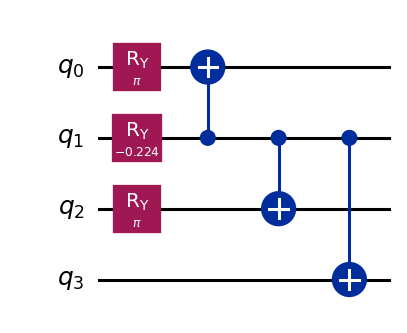

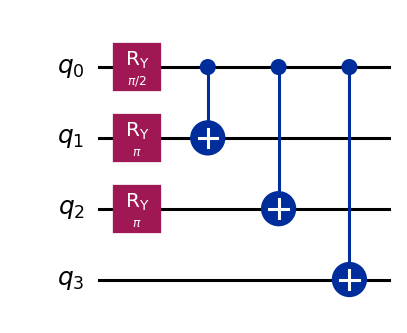

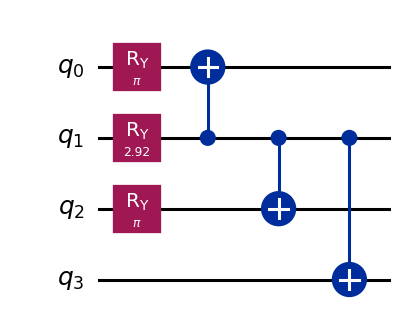

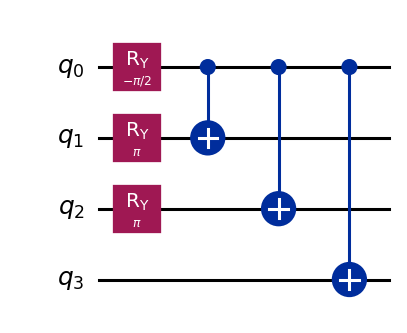

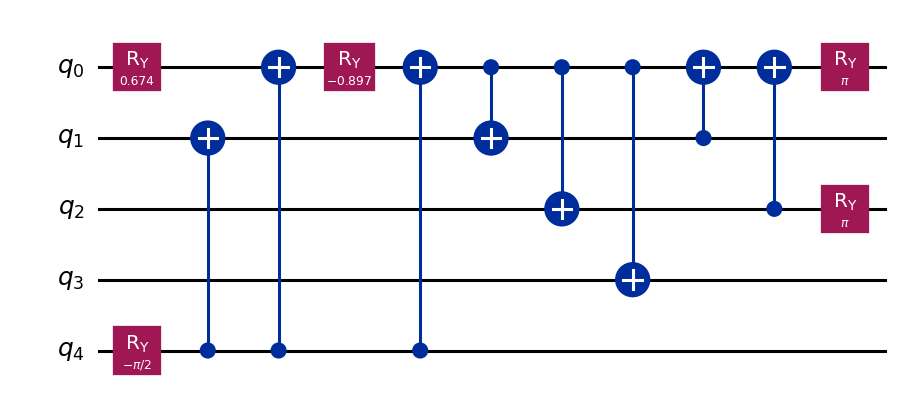

In [4]:
for s in ['S0','S1','S2','T']:
    print(s,dict(PREPS[s].count_ops()))
    draw(PREPS[s])
for target in ['S2','S1','T']:
    prep=joint_prep(target,theta)
    expected=np.r_[STATES['S0'],STATES[target]]/np.sqrt(2)
    np.testing.assert_allclose(Statevector.from_instruction(prep).data,expected,atol=1e-12)
    assert set(prep.count_ops()) <= {'ry','cx'}
    print('Exact joint S0/'+target,dict(prep.count_ops()))
draw(joint_prep('S1',theta))
# 既存1量子ビット版のブロックを、そのまま再発見する。
np.testing.assert_allclose(H[np.ix_([5,10],[5,10])],
    [[-1.836967991202984,.18093119978423136],[.18093119978423136,-.24521829183026772]],atol=1e-10)

### 演習0

全16次元を保持しているのに、なぜS₀の準備は短いか。S₁,TはHFからの厳密時間発展で現れるか。

<details><summary>解答例</summary>

このH₂では固有状態が二つの配置だけの重ね合わせで、既知の厳密解を使っているためです。HFはS₀/S₂ブロックにあり、厳密発展で別ブロックのS₁,Tへ移りません。大規模分子の未知状態を同じコストで準備できるという意味ではありません。

</details>

## 1．干渉で位相を読む：定数項も保持する

BPEのRamsey回路は、準備した$|\psi\rangle$について
$$P(a=0)=\frac{1+\mathrm{Re}[e^{i\beta}\langle\psi|U^L|\psi\rangle]}2$$
を測ります。固有状態なら$[1+\cos(-E^{\rm el}t+\beta)]/2$です。
$H$の定数項$cI$を捨てると、制御付き発展では補助の相対位相を変えてしまいます。

**予想：** 同じ分子のS₀,S₁,S₂,Tで、干渉の周期はどう変わるでしょうか。

Constant term: -0.8105479805373281 Ramsey with/without constant: 0.00022569450119480639 0.3503461769491355


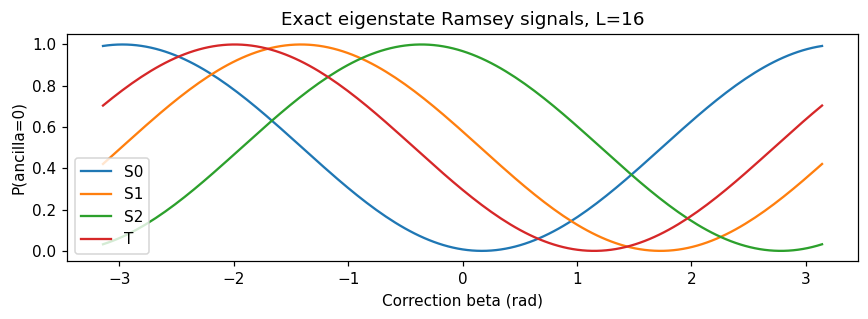

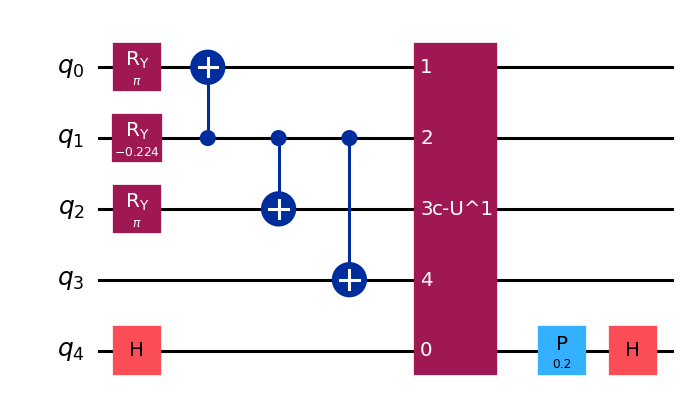

In [5]:
betas=np.linspace(-np.pi,np.pi,151)
fig,ax=plt.subplots(figsize=(8,3))
for s in ['S0','S1','S2','T']:
    p=[bpe_probability(STATES[s],U,16,b) for b in betas]
    np.testing.assert_allclose(p,single_phase(PHASES[s],16,betas),atol=1e-11)
    ax.plot(betas,p,label=s)
    qc=bpe_circuit(PREPS[s],U,16,.2)
    np.testing.assert_allclose(Statevector.from_instruction(qc).probabilities([4])[0],bpe_probability(STATES[s],U,16,.2),atol=1e-11)
ax.set(xlabel='Correction beta (rad)',ylabel='P(ancilla=0)',title='Exact eigenstate Ramsey signals, L=16');ax.legend();show()
draw(bpe_circuit(PREPS['S0'],U,1,.2))
c=float(PAULI.coeffs[PAULI.paulis.to_labels().index('IIII')].real)
u_without_constant=expm(-1j*(H-c*np.eye(16))*DT)
print('Constant term:',c,'Ramsey with/without constant:',bpe_probability(STATES['S0'],U,16,.2),bpe_probability(STATES['S0'],u_without_constant,16,.2))

### 演習1

核間反発はどこに入れるか。電子Hamiltonianの定数Pauli項と同じものか。

<details><summary>解答例</summary>

ここでは電子Hamiltonianで発展し、推定した電子エネルギーへ核間反発を加えます。電子HamiltonianのI項は別の寄与で、制御付き発展から勝手に除けません。

</details>

## 2．逆QFT型QPE：四つの分子状態を比較する

$$P(y|\phi)=\left|2^{-m}\sum_{k=0}^{2^m-1}e^{2\pi ik(\phi-y/2^m)}\right|^2.$$
厳密固有状態でも有限$m$では格子への広がりが残ります。$\Delta t=0.1$なので$m=8$でもエネルギー格子幅は約0.245 Haです。
回路図は$m=3$、比較の数値は$m=8$です。制御付きUは検証用の厳密行列の箱であり、描画上の一箱を一ゲートとは数えません。

**予想：** HFのQPEはHFの期待エネルギー一つを返すでしょうか。

HF weights S0,S2: [np.float64(0.9875597343674859), np.float64(0.01244026563251427)]


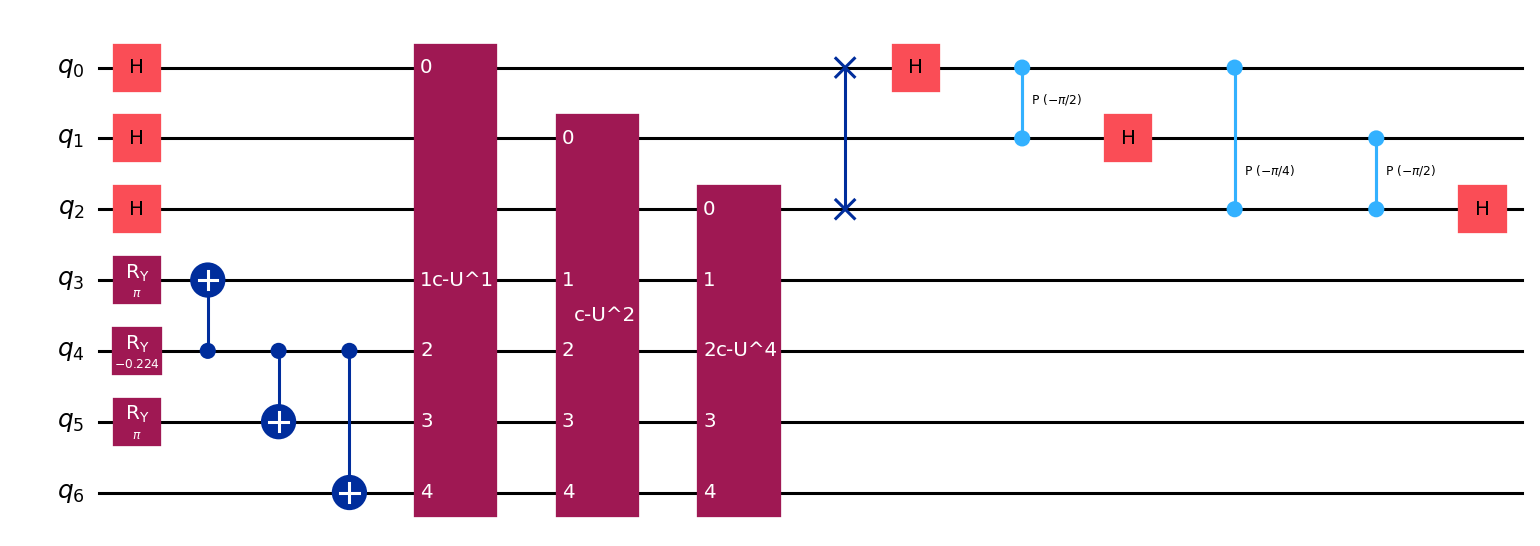

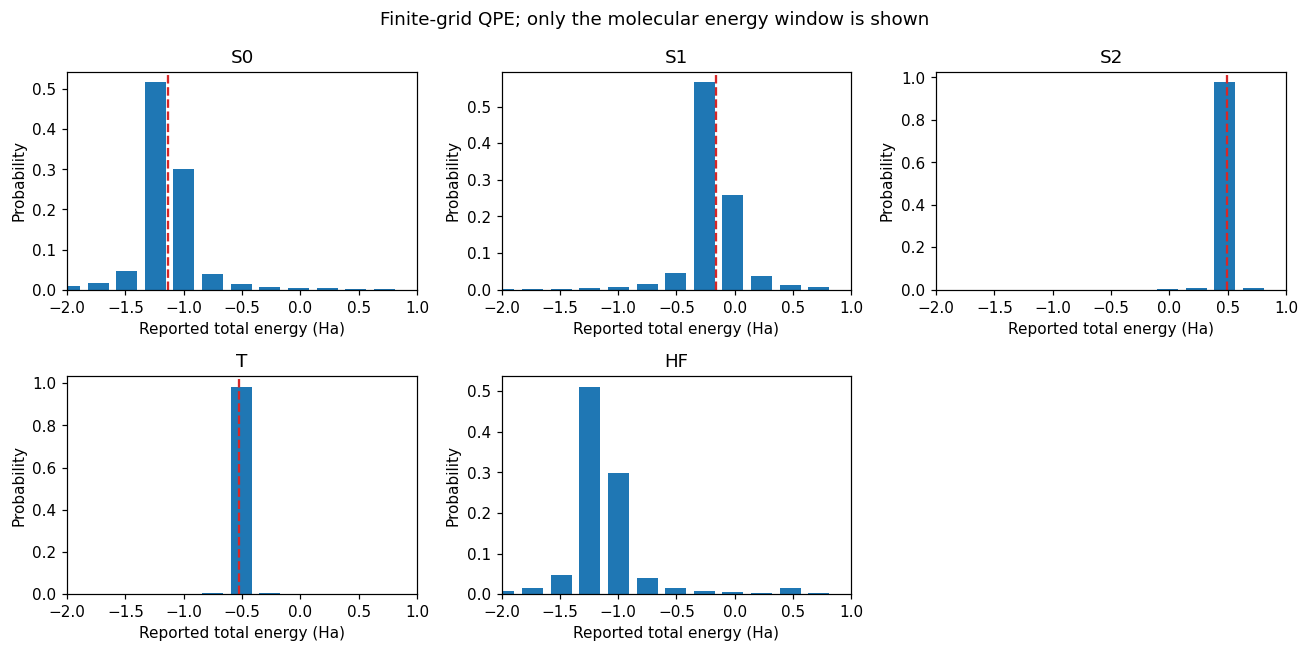

In [6]:
x=np.arange(8)
np.testing.assert_allclose(Operator(inverse_qft(3)).data,np.exp(-1j*TAU*np.outer(x,x)/8)/np.sqrt(8),atol=1e-12)
draw(qpe_circuit(PREPS['S0'],U,3))
fig,axes=plt.subplots(2,3,figsize=(12,6))
for ax,s in zip(axes.flat,['S0','S1','S2','T','HF']):
    p=qpe_distribution(PREPS[s],U,8)
    ev,v=np.linalg.eigh(H)
    analytic=sum(w*qpe_formula((-e*DT/TAU)%1,8) for w,e in zip(abs(v.conj().T@STATES[s])**2,ev))
    np.testing.assert_allclose(p,analytic,atol=1e-10)
    energy=ENUC-TAU*np.arange(256)/256/DT
    ax.bar(energy,p,width=.18);ax.set(xlim=(-2,1),xlabel='Reported total energy (Ha)',ylabel='Probability',title=s)
    if s!='HF':ax.axvline(ENERGIES[s]+ENUC,c='C3',ls='--')
axes.flat[-1].axis('off');plt.suptitle('Finite-grid QPE; only the molecular energy window is shown');show()
print('HF weights S0,S2:',[abs(np.vdot(STATES[s],STATES['HF']))**2 for s in ['S0','S2']])

### 演習2

S₁とTを入力したとき、なぜS₀のピークが出ないか。

<details><summary>解答例</summary>

初期状態を厳密に別の固有状態へ準備しているからです。理想QPEは入力状態の固有成分を読み、常に最低エネルギーを探索する操作ではありません。有限格子の裾は別状態の混入と区別します。

</details>

## 3．iterative QPE：補助1個、条件付きの系4個を保持する

$m=3$なら$L=4,2,1$の順です。既読整数$y$を用い、
$$M_b=(I+(-1)^b e^{i\beta}U^L)/2,\quad\beta=-2\pi Ly/2^m$$
で全分岐を計算します。補助はリセットし、系は条件付き状態を保持します。
動的回路を描画しますが実機には投入しません。

**予想：** 各ビット前に系を再準備すると、厳密固有状態とHFでは違いがあるでしょうか。

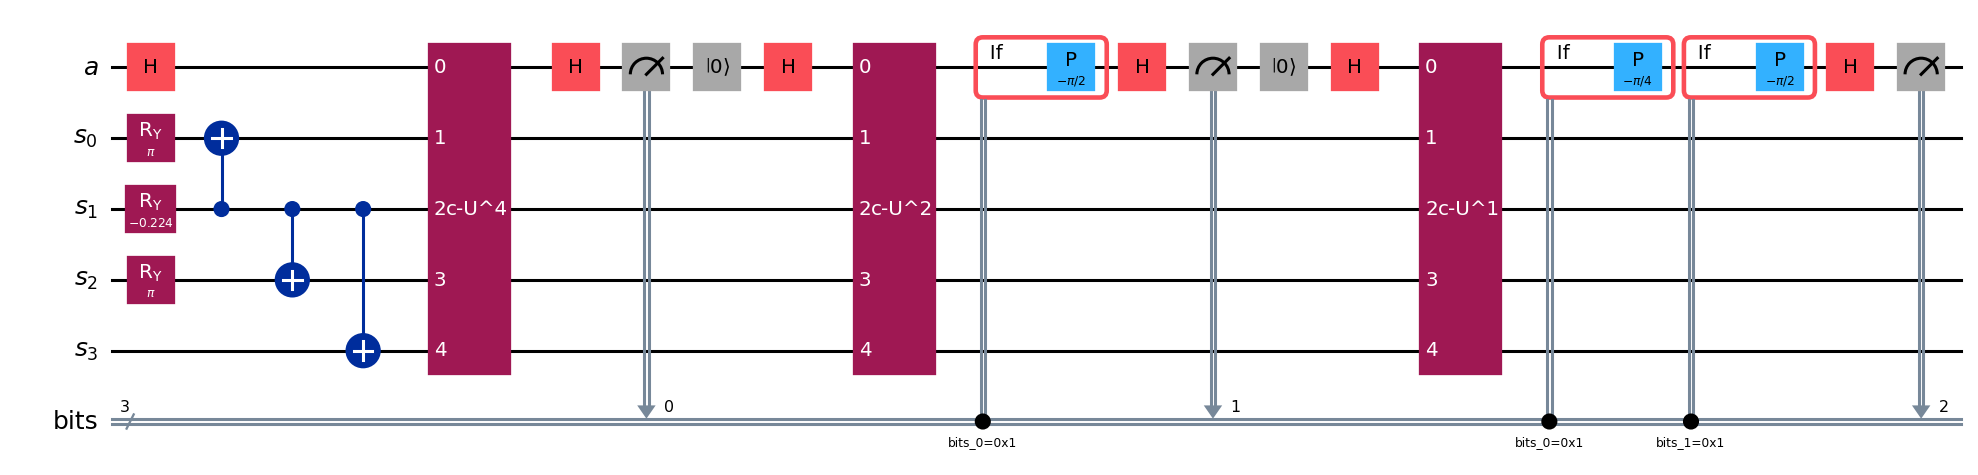

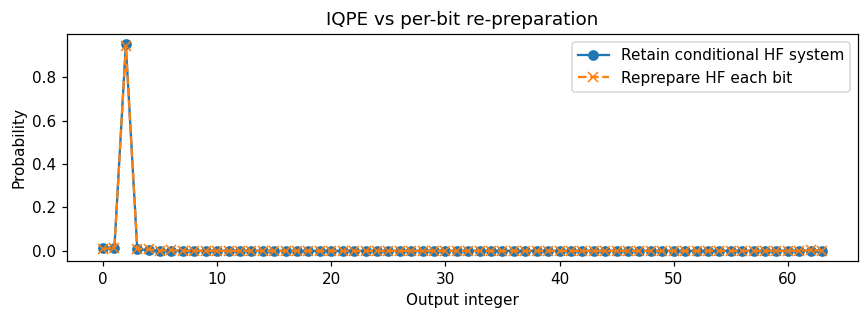

In [7]:
draw(iqpe_dynamic(PREPS['S0'],U,3),fold=100)
for s in ['S0','S1','S2','T','HF']:
    for m in [3,6]:
        np.testing.assert_allclose(iqpe_tree(STATES[s],U,m),qpe_distribution(PREPS[s],U,m),atol=1e-10)
np.testing.assert_allclose(iqpe_tree(STATES['S0'],U,6),iqpe_tree(STATES['S0'],U,6,True),atol=1e-10)
p_keep=iqpe_tree(STATES['HF'],U,6);p_reset=iqpe_tree(STATES['HF'],U,6,True)
assert np.linalg.norm(p_keep-p_reset)>1e-8
fig,ax=plt.subplots(figsize=(8,3));xx=np.arange(64)
ax.plot(xx,p_keep,'o-',label='Retain conditional HF system');ax.plot(xx,p_reset,'x--',label='Reprepare HF each bit')
ax.set(xlabel='Output integer',ylabel='Probability',title='IQPE vs per-bit re-preparation');ax.legend();show()

### 演習3

補助1個へ減らしても、時間発展の負担は減るか。

<details><summary>解答例</summary>

読出し量子ビットは減りますが、同じ桁数に必要なUのべきと長い発展時間は残ります。固有状態でない入力では条件付きの系を保持することも必要です。

</details>

## 4．BPE：厳密状態で単一位相を推定する

毎ショット同じ厳密回路で再準備します。尤度は$P_0=[1+\cos(2\pi L\phi+\beta)]/2$、二項模擬測定でグリッド更新します。
主比較は四つの厳密固有状態です。HFの信号はS₀,S₂の二周波数の重み付き和になることだけを診断します。
グリッド更新・時間設定は教材用で、著者のGaussian更新や時間選択そのものではありません。

S0 MAP total energy= -1.1371064968850746 95% interval= [-1.1387316406904051, -1.133657700537737]
S1 MAP total energy= -0.1649461725625495 95% interval= [-0.16512478091701388, -0.16118526929104415]
S2 MAP total energy= 0.4965830422131332 95% interval= [0.4948567715622859, 0.500117243807513]
T MAP total energy= -0.5254316577156751 95% interval= [-0.5259799348864082, -0.5216862477530081]


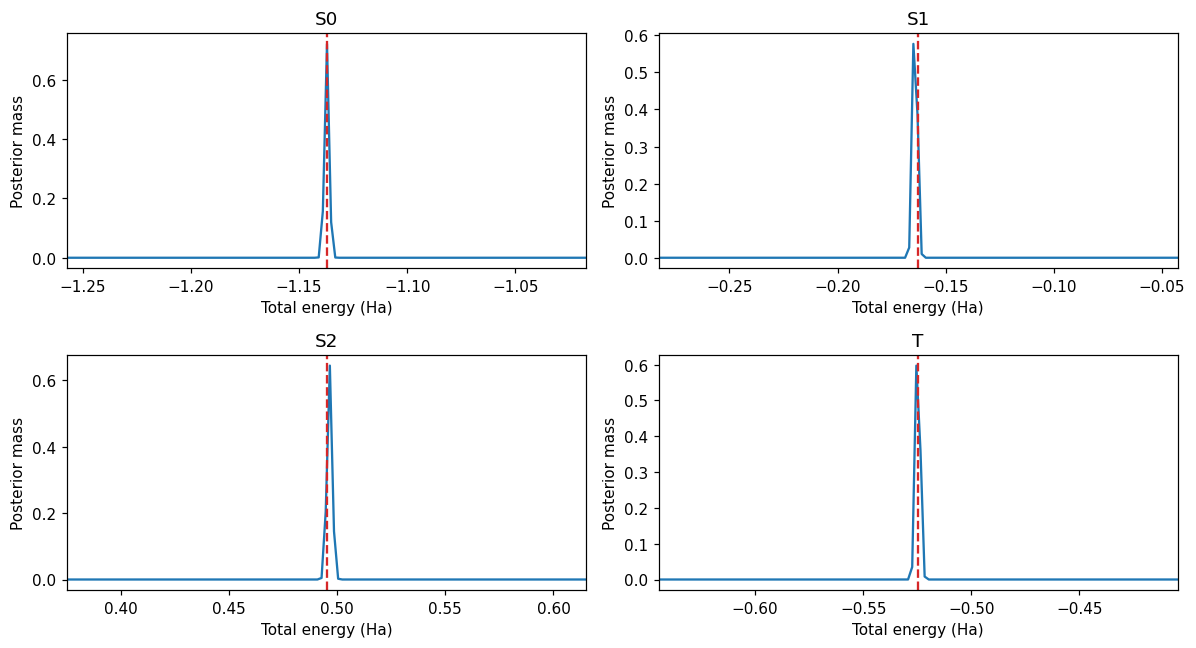

In [8]:
GRID=(np.arange(32768)+.5)/32768
SETTINGS=[(L,b) for L in [1,2,4,8,16,32,64,128,256] for b in [np.pi/5,np.pi/5-np.pi/2]]
fig,axes=plt.subplots(2,2,figsize=(11,6));BPE_RESULTS={}
for k,(ax,s) in enumerate(zip(axes.flat,['S0','S1','S2','T'])):
    hist,records=bayes(GRID,SETTINGS,lambda L,b,s=s:bpe_probability(STATES[s],U,L,b),shots=512,seed=40+k)
    BPE_RESULTS[s]=hist
    est,lo,hi=summary(GRID,hist[-1]);assert abs(est-PHASES[s])<.0002
    energy=ENUC-TAU*GRID/DT
    ax.plot(energy,hist[-1]);ax.axvline(ENERGIES[s]+ENUC,c='C3',ls='--')
    ax.set(xlim=(ENERGIES[s]+ENUC-.12,ENERGIES[s]+ENUC+.12),xlabel='Total energy (Ha)',ylabel='Posterior mass',title=s)
    print(s,'MAP total energy=',ENUC-TAU*est/DT,'95% interval=',sorted([ENUC-TAU*lo/DT,ENUC-TAU*hi/DT]))
show()
w0=abs(np.vdot(STATES['S0'],STATES['HF']))**2
for L,b in SETTINGS:
    expected=w0*single_phase(PHASES['S0'],L,b)+(1-w0)*single_phase(PHASES['S2'],L,b)
    np.testing.assert_allclose(bpe_probability(STATES['HF'],U,L,b),expected,atol=1e-11)

### 演習4

厳密状態準備を固定する意義は何か。

<details><summary>解答例</summary>

時間発展を近似へ置き換えたときの変化を、状態準備の近似誤差と混同せずに調べられます。HFの比較は診断であり、主推定の状態準備は四つの厳密固有状態に固定します。

</details>

### 4.1〜4.2．発展時間の比較：短時間固定・段階的増加・長時間固定

既存教材と同じL=1固定、L=1,2,4,8,16,32、L=32固定を、同じ総3072ショットで比較します。
総発展時間の資源は等しくないのでsum(R L)も表示します。全範囲・拡大図・区間幅・64回の模擬実験のRMSEを確認します。
L=32だけでは32個の周期的候補が残ります。

L=1 shots= 3072 sum(R L)= 3072 MAP= 0.0320892333984375 95% width= 0.011188763369609164
Staged shots= 3072 sum(R L)= 32256 MAP= 0.0295562744140625 95% width= 0.0007457578604650981
L=32 shots= 3072 sum(R L)= 98304 MAP= 0.5296173095703125 95% width= 0.9686019040247741
L=1 64-trial circular RMSE= 0.0032348062660838574
Staged 64-trial circular RMSE= 0.00015020164758785867


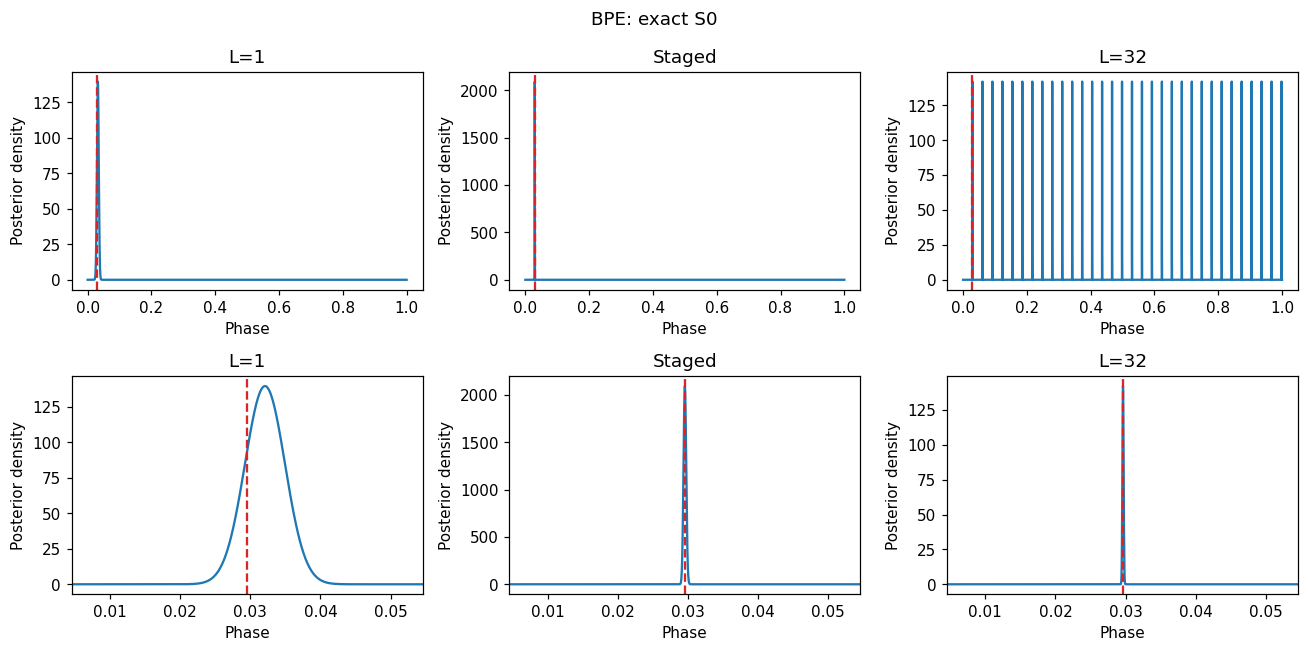

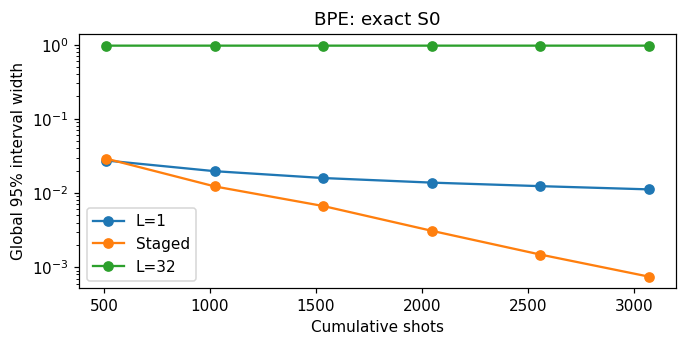

In [9]:
TIME_BPE=time_comparison(lambda L,b:bpe_probability(STATES['S0'],U,L,b),PHASES['S0'],'BPE: exact S0',seed=80)

### 演習4.2

長時間固定で候補が残る理由は何か。

<details><summary>解答例</summary>

余弦の周期によりphiとphi+k/32が同じ尤度を持つためです。ショットを増やすだけでは周期の別名を区別できず、短時間を含む計画や追加の事前情報が必要です。

</details>

## 5．Fig. 1B型BPDE：S₀からS₂・S₁・Tへの差を読む

$$U_{\rm prep}|0^5\rangle=(|0\rangle_a|S_0\rangle+|1\rangle_a|j\rangle)/\sqrt2.$$
厳密Ry/CNOT準備 → **制御なし**の系時間発展 → 補助位相$P(\beta)$ → 逆準備 → 補助測定です。
$$P(a=0)=\frac{1+\cos[-(E_j-E_0)t+\beta]}2.$$
$\beta=\epsilon t$とすれば$[1+\cos((\Delta E-\epsilon)t)]/2$。核間反発と共通の電子エネルギー原点は相殺します。

ここでの「B型」は逆準備後に補助だけを測る読出しを指します。準備のゲート配置はこの教材の厳密Ry/CNOT回路に固定し、最適化したMPS準備へ変更しません。

S2 exact gap= 1.632363777371508 MAP gap= 1.632730801105779
S1 exact gap= 0.9745528799575158 MAP gap= 0.9731190623149536
T exact gap= 0.6126904803890532 MAP gap= 0.6126335771618279


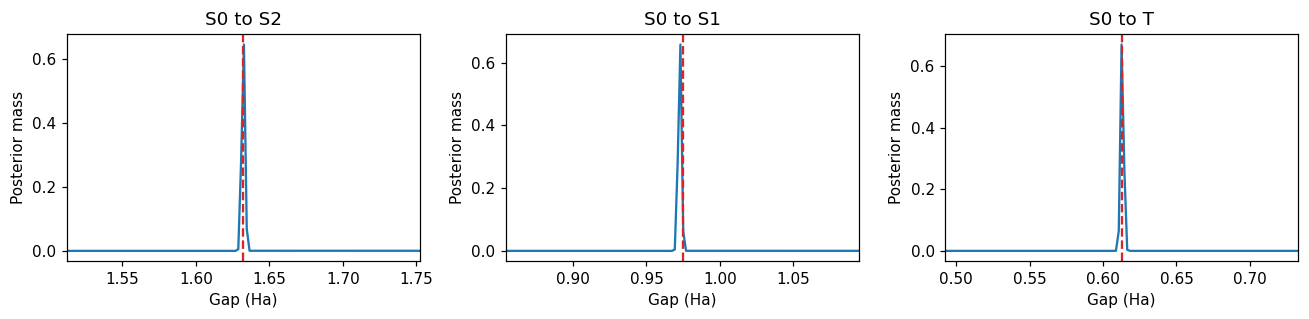

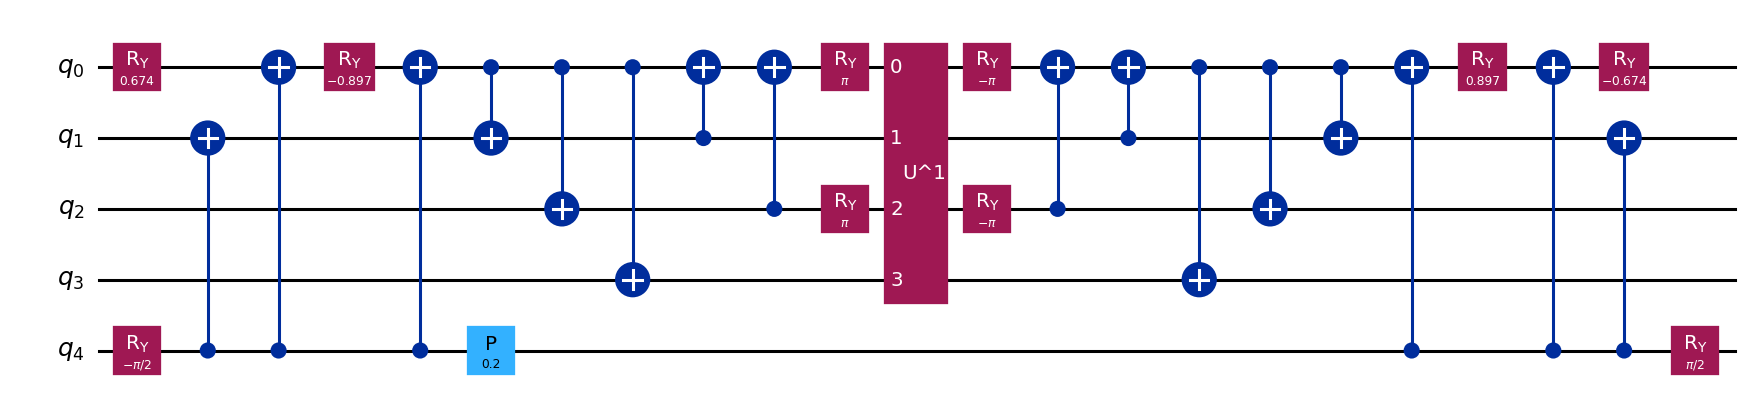

In [10]:
GAPS={s:ENERGIES[s]-ENERGIES['S0'] for s in ['S2','S1','T']}
DELTAS={s:(-gap*DT/TAU)%1 for s,gap in GAPS.items()}
fig,axes=plt.subplots(1,3,figsize=(12,3));BPDE_RESULTS={}
for k,(ax,target) in enumerate(zip(axes,['S2','S1','T'])):
    prob=lambda L,b,target=target:bpde_probability(target,theta,U,L,b,False)
    for L in [1,8,32]:
        for b in [.2,-.7]:np.testing.assert_allclose(prob(L,b),single_phase(DELTAS[target],L,b),atol=1e-11)
    hist,records=bayes(GRID,SETTINGS,prob,shots=512,seed=100+k);BPDE_RESULTS[target]=hist
    est,lo,hi=summary(GRID,hist[-1]);assert abs(est-DELTAS[target])<.0002
    gap_axis=TAU*(1-GRID)/DT
    ax.plot(gap_axis,hist[-1]);ax.axvline(GAPS[target],c='C3',ls='--')
    ax.set(xlim=(GAPS[target]-.12,GAPS[target]+.12),xlabel='Gap (Ha)',ylabel='Posterior mass',title='S0 to '+target)
    print(target,'exact gap=',GAPS[target],'MAP gap=',TAU*(1-est)/DT)
show();draw(bpde_circuit('S1',theta,U,1,.2))
for target in GAPS:
    np.testing.assert_allclose(bpde_probability(target,theta,U,16,.4),bpde_probability(target,theta,u_without_constant,16,.4),atol=1e-11)

### 演習5

S₀–S₁差を測るためにHamiltonianへスピンや対称性を変える項を足す必要はあるか。

<details><summary>解答例</summary>

不要です。最初の補助付き重ね合わせの両枝へそれぞれの状態を準備し、同じHamiltonianで発展させます。遷移を駆動する実験と、二状態の位相差を読む実験は異なります。

</details>

### 5.1．BPDEの時間計画

S₀–S₁差で、同じショット数の三計画を比較します。状態準備はすべて同じ厳密回路です。

L=1 shots= 3072 sum(R L)= 3072 MAP= 0.9877166748046875 95% width= 0.011277033343237042
Staged shots= 3072 sum(R L)= 32256 MAP= 0.9846649169921875 95% width= 0.0007364562117591067
L=32 shots= 3072 sum(R L)= 98304 MAP= 0.5469818115234375 95% width= 0.9685995371637668
L=1 64-trial circular RMSE= 0.002513910518798343
Staged 64-trial circular RMSE= 0.00019668809366725894


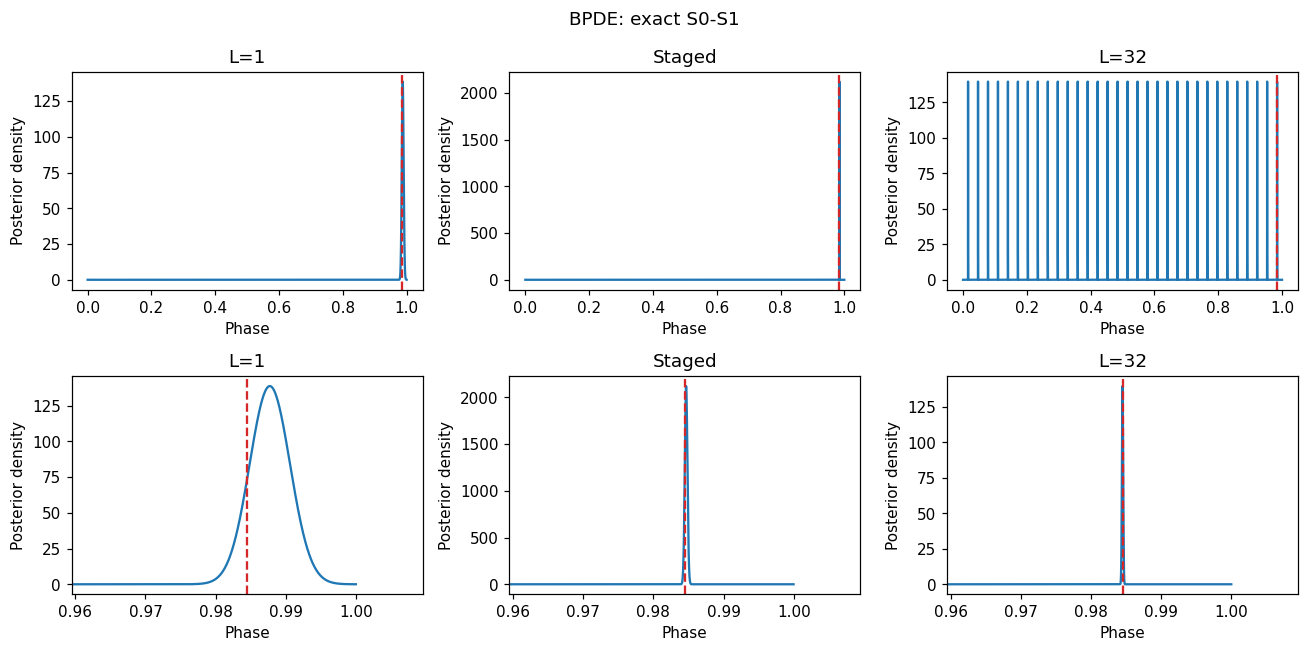

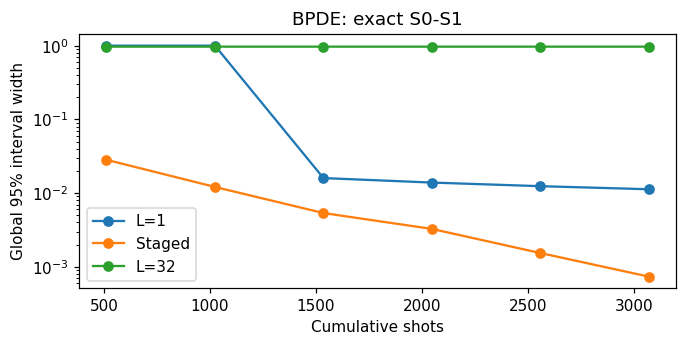

In [11]:
TIME_BPDE=time_comparison(lambda L,b:bpde_probability('S1',theta,U,L,b,False),DELTAS['S1'],'BPDE: exact S0-S1',seed=110)

## 6．Fig. 1C型：全0イベントを読む

同じ準備・逆準備で、補助だけではなく全5量子ビットの0を数えます。
$$P(0^5)=\frac14|a_0(t)+e^{i\beta}a_j(t)|^2,\quad a_j(t)=\langle j|U(t)|j\rangle.$$
厳密固有状態・厳密発展ならB型とC型は同じ余弦です。近似発展で他の状態へ漏れると、二つの読出しは一般に異なります。
参照MPOはわずかに非ユニタリなので、そのままUnitaryGateに渡したり、正規化して物理的な確率と呼んだりしません。

Exact B and C probabilities agree for all three gaps.


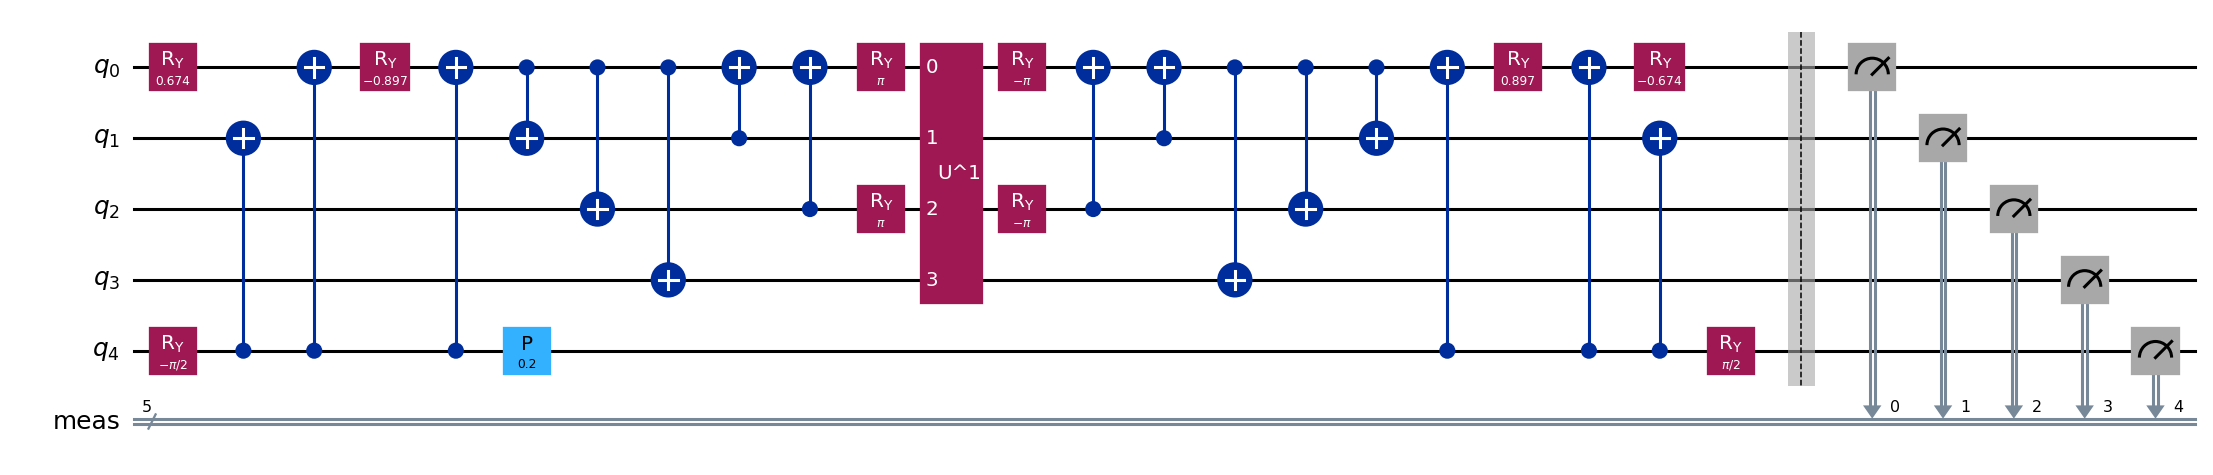

In [12]:
for target in GAPS:
    for L in [1,8,32]:
        for beta in [.2,-.7]:
            p_b=bpde_probability(target,theta,U,L,beta,False)
            p_c=bpde_probability(target,theta,U,L,beta,True)
            up=np.linalg.matrix_power(U,L)
            a0=np.vdot(STATES['S0'],up@STATES['S0']);aj=np.vdot(STATES[target],up@STATES[target])
            np.testing.assert_allclose(p_c,abs(a0+np.exp(1j*beta)*aj)**2/4,atol=1e-11)
            np.testing.assert_allclose(p_b,p_c,atol=1e-11)
measured=bpde_circuit('S1',theta,U,1,.2);measured.measure_all();draw(measured)
print('Exact B and C probabilities agree for all three gaps.')

### 演習6

全0読出しは、測定後に残りの結果を捨てて再正規化する操作か。

<details><summary>解答例</summary>

ここでは全ショットに対する全0の出現確率を使い、成功した部分集団だけへの条件付けは行いません。準備・発展・逆準備の回路は同じで、数えるイベントが変わります。

</details>

## 7．全体脱分極モデル：5量子ビットで背景を比較する

逆準備後に$\rho\mapsto(1-p)\rho+pI/32$とする単純な**全体脱分極**モデルでは、
$$P(a=0)=(1-p)P_{\rm ideal}+p/2,\quad
P(0^5)=(1-p)P_{\rm ideal}+p/32.$$
背景は小さくなりますが、信号の係数$(1-p)$は共通です。局所ゲートノイズ・漏れ・実機で同じ抑制が保証されるわけではありません。

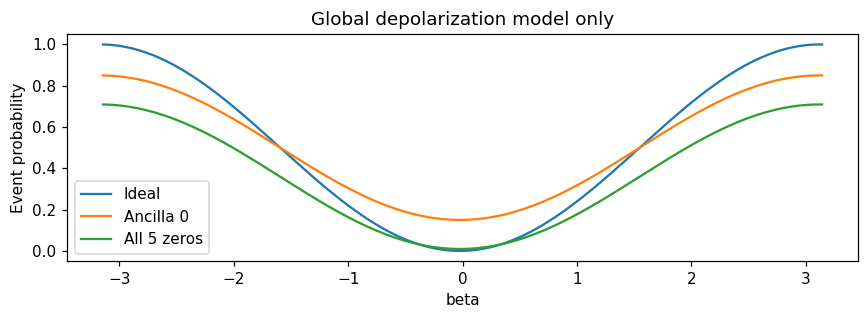

In [13]:
beta=np.linspace(-np.pi,np.pi,151);pnoise=.3
ideal=single_phase(DELTAS['S1'],32,beta)
fig,ax=plt.subplots(figsize=(8,3));ax.plot(beta,ideal,label='Ideal')
ax.plot(beta,(1-pnoise)*ideal+pnoise/2,label='Ancilla 0')
ax.plot(beta,(1-pnoise)*ideal+pnoise/32,label='All 5 zeros')
ax.set(xlabel='beta',ylabel='Event probability',title='Global depolarization model only');ax.legend();show()
qc=bpde_circuit('S1',theta,U,8,.2);v=Statevector.from_instruction(qc).data
rho=(1-pnoise)*np.outer(v,v.conj())+pnoise*np.eye(32)/32
np.testing.assert_allclose(rho[0,0].real,(1-pnoise)*abs(v[0])**2+pnoise/32,atol=1e-12)
np.testing.assert_allclose(np.trace(rho[:16,:16]).real,(1-pnoise)*sum(abs(v[:16])**2)+pnoise/2,atol=1e-12)

### 演習7

5量子ビット化すると状態準備や時間発展の誤差も自動的に消えるか。

<details><summary>解答例</summary>

消えません。この式は全体脱分極が混ぜる一様背景の議論です。時間発展近似で位相がずれる問題は別に評価します。

</details>

## 8．格子に載らない位相と、結合伸長

有限$m$のQPE格子、ショット数、モデルの不一致は異なる誤差です。
ここでは厳密状態を保ち、$m$を増やしたときの格子幅を見ます。結合伸長による準備角の変化は付録で厳密再生成します。
既存1量子ビット版と同じS₀/S₂の混合角が、4量子ビットの厳密準備角として現れます。

m= 3 most likely y= 0 reported energy= 0.7199689944489797 exact= -1.1373060357534004
m= 6 most likely y= 2 reported energy= -1.243526414044641 exact= -1.1373060357534004
m= 8 most likely y= 8 reported energy= -1.243526414044641 exact= -1.1373060357534004


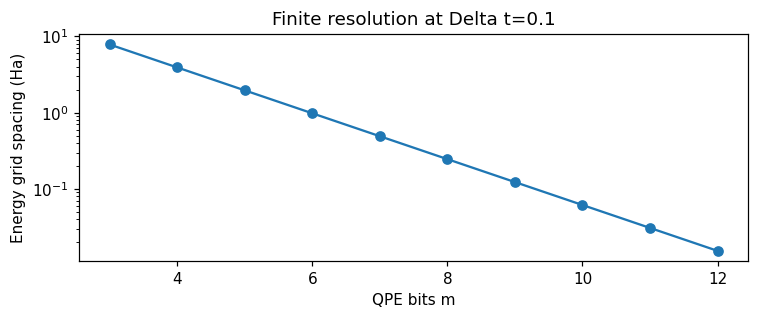

In [14]:
fig,ax=plt.subplots(figsize=(7,3));ms=np.arange(3,13)
ax.semilogy(ms,TAU/(2.**ms*DT),'o-')
ax.set(xlabel='QPE bits m',ylabel='Energy grid spacing (Ha)',title='Finite resolution at Delta t=0.1');show()
for m in [3,6,8]:
    p=qpe_distribution(PREPS['S0'],U,m);y=int(np.argmax(p))
    print('m=',m,'most likely y=',y,'reported energy=',ENUC-TAU*y/(2**m*DT),'exact=',ENERGIES['S0']+ENUC)

### 演習8

厳密回路でQPEを実行しても基準エネルギーと完全一致しないのはなぜか。

<details><summary>解答例</summary>

有限ビットの出力格子に分子の位相が一般には載らないためです。これは時間発展の演算子誤差とは別で、mとDelta tで格子幅を確認できます。

</details>

## 9．方式と資源、時間発展の二段階のブラックボックス

| 方式 | 系 | 補助 | 発展 |
|---|---:|---:|---|
| QPE | 4 | $m$ | 制御付き$U^{2^r}$ |
| IQPE | 4 | 1 | 同じべき、系を保持 |
| BPE | 4 | 1 | 制御付き$U^L$、毎回厳密再準備 |
| BPDE B/C | 4 | 1 | 制御なし$U^L$、厳密重ね合わせ＋逆準備 |

### 9.1．第一段階：Hamiltonianから参照MPOへ

$$H,\Delta t\ \xrightarrow[\text{100分割二次Trotter＋収縮/SVD}]{\text{著者関数 get_gate_second_trotter}}\ M_{\rm ref}^{\dagger}.$$
著者コードは参照を$U^\dagger$向きに保存し、第二段階では$\mathrm{Re}\,\mathrm{Tr}(M_{\rm ref}^\dagger U_{\rm circ})$を最大化します。
以下では共役転置して$M_{\rm ref}$へ向きを統一します。厳密$e^{-iH\Delta t}$は、この小分子でだけ使える独立の検証基準です。

**入力：** 15項Hamiltonian、$\Delta t=0.1$、100分割、著者既定のSVD cutoff $10^{-12}$。
**出力：** 著者が生成した実際のMPOコア4個とボンド次元。その密行列への収縮も照合します。

Trotter誤差、MPO収縮/SVDの追加誤差、全体の誤差を分けます。
相対Frobenius誤差は$\|A-B\|_F/\|B\|_F$、ユニタリ性のずれは$\|A^\dagger A-I\|_F/\sqrt{16}$です。
cutoffは最終的な演算子誤差をそのまま保証する値ではありません。

Actual author MPO bonds: [4 5 4]
Core shapes: [(2, 2, 4), (4, 2, 2, 5), (5, 2, 2, 4), (4, 2, 2)]
dense Trotter vs exact 5.801479269173861e-10
author MPO vs dense Trotter 1.630178097786736e-05
author MPO vs exact 1.6301920479219256e-05
MPO unitarity defect 3.117337899882707e-05
Exact U [5,10] block:
 [[0.98301297+0.18264411j 0.00187817-0.01797518j]
 [0.00187817-0.01797518j 0.99953629+0.0245067j ]]
Reference MPO [5,10] block:
 [[0.98301818+0.18264496j 0.00189911-0.01798319j]
 [0.00189954-0.01798209j 0.99954158+0.0245067j ]]
First actual MPO core:
 [[[-2.82731115+0.j          0.07521788+0.j
    0.        +0.j          0.        +0.j        ]
  [ 0.        -0.j          0.        -0.j
   -0.02557104-0.00029277j -0.00014335+0.0000145j ]]

 [[-0.        -0.j         -0.        -0.j
   -0.00014408-0.00000148j  0.02543914-0.00260308j]
  [-2.82563465+0.09735041j -0.07517328+0.00258991j
   -0.        +0.j         -0.        +0.j        ]]]


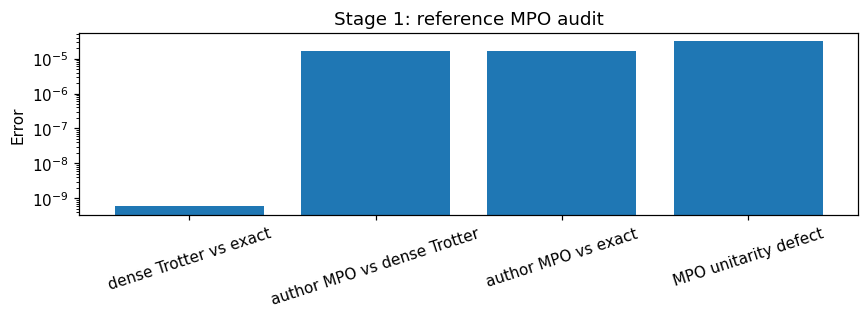

In [15]:
REF_ADJOINT=DATA['reference_adjoint'];REF=REF_ADJOINT.conj().T
np.testing.assert_allclose(contract_author_mpo(DATA),REF_ADJOINT,atol=1e-12)
TROTTER100=dense_trotter(H,DT,100,2)
STAGE1={
    'dense Trotter vs exact':rel_error(TROTTER100,U),
    'author MPO vs dense Trotter':rel_error(REF,TROTTER100),
    'author MPO vs exact':rel_error(REF,U),
    'MPO unitarity defect':unitary_defect(REF)}
print('Actual author MPO bonds:',DATA['reference_bonds'])
print('Core shapes:',[DATA[f'reference_core_{j}'].shape for j in range(1,5)])
for key,value in STAGE1.items():print(key,value)
fig,ax=plt.subplots(figsize=(8,3));ax.bar(STAGE1.keys(),STAGE1.values());ax.set_yscale('log');ax.tick_params(axis='x',rotation=18)
ax.set(ylabel='Error',title='Stage 1: reference MPO audit');show()
# Small inspectable input/output: selected blocks and one actual core.
print('Exact U [5,10] block:\n',U[np.ix_([5,10],[5,10])])
print('Reference MPO [5,10] block:\n',REF[np.ix_([5,10],[5,10])])
print('First actual MPO core:\n',DATA['reference_core_1'])

### 演習9.1

100分割Trotterの誤差が小さければ、参照MPOを厳密と呼べるか。

<details><summary>解答例</summary>

呼べません。著者パイプラインにはMPOの収縮とSVD打切りもあり、密な同順序Trotterと実際の参照MPOを別々に比較する必要があります。非ユニタリな参照を黙って正規化・極分解して量子回路と呼ぶこともしません。

</details>

### 9.2．第二段階：参照MPOからユニタリ回路へ

$$M_{\rm ref}^\dagger\ \xrightarrow[\text{環境テンソル＋局所SVD更新}]{\text{著者関数 get_and_save_evol_BW_2d_list}}\ U_{\rm circ}.$$
**入力：** 第一段階の参照MPO、層数$d=2,4,8$、まず1000スイープ・乱数初期化seed=1、既定cutoff。
続く9.2a節で各層数のseed=1〜5を追加探索し、最良候補の収束を確認して後半の主比較を更新します。
**出力：** 全4×4ユニタリゲートと最適化履歴。著者の保存順をそのままQiskitの隣接2ビットへ読み込みます。
独自Ansatz・汎用の角度フィットへの置き換えはありません。

著者指標は$\delta=\sqrt{2-[\mathrm{Re}\,\mathrm{Tr}(M_{\rm ref}^\dagger U_{\rm circ})]^{1/4}}$です。
履歴の先頭は生の初期コストなので除き、1スイープ目以降の$\delta$だけを描きます。
出力ゲートから指標を独立に再計算し、向きとゲート順も検証します。

d= 2 blocks= 3 vs MPO= 0.030789843658891466 vs exact= 0.030789679838242337 unitarity= 1.482375114088404e-15 delta= 0.015396288555223153
d= 4 blocks= 6 vs MPO= 0.03077474616650357 vs exact= 0.030774585767610677 unitarity= 2.2709300632502083e-15 delta= 0.015388737795610376
d= 8 blocks= 12 vs MPO= 0.01778755958212821 vs exact= 0.01778749183067903 unitarity= 4.527234469135121e-15 delta= 0.0088940404407816
First optimized 4x4 gate:
 [[ 0.95475978-0.25483487j -0.05957456+0.13848269j -0.02056945+0.00735697j
  -0.00141995+0.01694446j]
 [-0.10582242-0.09521937j -0.94145311+0.19099223j  0.22597304-0.05425488j
   0.0370125 -0.03931361j]
 [ 0.04662576+0.02403159j  0.22884232-0.02477359j  0.95860319-0.15140859j
   0.04190447-0.02579451j]
 [-0.0067627 -0.02075129j -0.03218907-0.0210416j   0.05729129+0.01970865j
  -0.99156964+0.10565836j]]


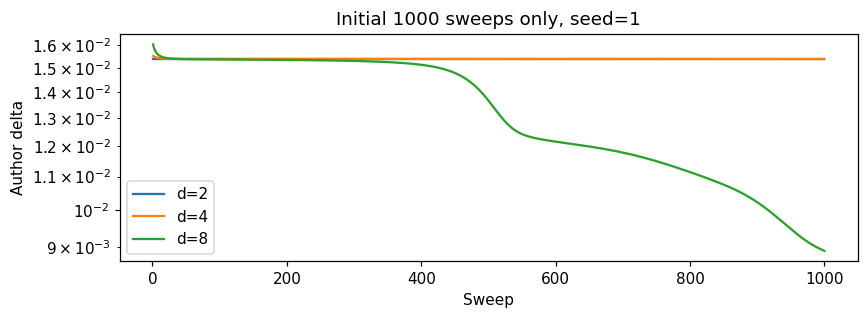

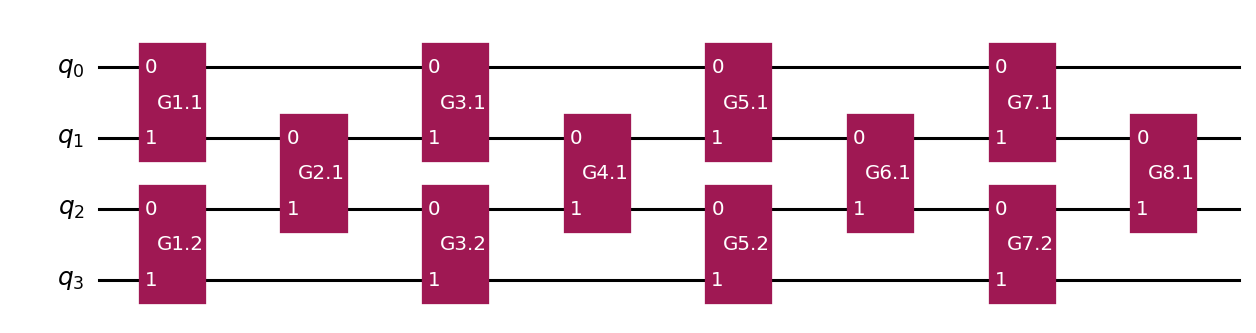

In [16]:
CIRCUITS={d:brickwall(DATA,d) for d in [2,4,8]}
APPROX={d:Operator(qc).data for d,qc in CIRCUITS.items()}
fig,ax=plt.subplots(figsize=(8,3))
for d,u in APPROX.items():
    delta=np.sqrt(max(0,2-max(0,float(np.trace(REF_ADJOINT@u).real))**.25))
    np.testing.assert_allclose(delta,DATA[f'h2_d{d}_history'][-1],atol=1e-10)
    assert unitary_defect(u)<1e-10
    ax.semilogy(np.arange(1,1001),DATA[f'h2_d{d}_history'][1:],label=f'd={d}')
    print('d=',d,'blocks=',len(CIRCUITS[d].data),'vs MPO=',rel_error(u,REF),'vs exact=',rel_error(u,U),'unitarity=',unitary_defect(u),'delta=',delta)
ax.set(xlabel='Sweep',ylabel='Author delta',title='Initial 1000 sweeps only, seed=1');ax.legend();show()
draw(CIRCUITS[8])
print('First optimized 4x4 gate:\n',DATA['h2_d8_MPO_depth1_1'])

### 9.2a．スイープ数と初期値を増やした収束確認

1000スイープで下降中の回路を最終性能と扱わず、**各層数でseed=1〜5を追加探索し、最良回路の収束を確認**しました。
著者コアは変更せず、初期化・環境テンソル生成・各スイープを著者関数で行い、停止判定と保存のみ外側のドライバが担当します。
seed=1の最初の1000スイープのコストは、元の著者高水準関数の履歴と独立照合しています。

収束判定は1000スイープごとの参照MPOに対するFrobenius誤差の改善量が
**絶対値$10^{-8}$未満、かつ相対値$10^{-3}$未満**を3区間連続で満たすことです。
誤差の履歴は$[16+\|M_{\rm ref}\|_F^2-2\mathrm{ReTr}(M_{\rm ref}^\dagger U)]/16$の平方根から求め、
保存した全ゲートの密行列でも最終誤差を再計算します。8層の探索上限は約15万スイープです。上限に達した試行は未収束と明記し、最良候補が未収束ならその候補を継続します。
実際には最良候補が停止条件を満たした一方、上限到達時にも改善中の初期値が残りました。
これは指定許容誤差での**局所収束**であり、大域最適性の証明ではありません。

参考として、参照MPOの特異値$\sigma_k$から、全ユニタリの中での誤差下限
$$\min_{V^\dagger V=I}\frac{\|V-M_{\rm ref}\|_F}{\|M_{\rm ref}\|_F}
=\frac{\sqrt{\sum_k(\sigma_k-1)^2}}{\|M_{\rm ref}\|_F}$$
も表示します。これはbrick-wall Ansatzで達成できることを保証する値ではなく、下限の計算に使う極分解のユニタリを著者回路へ代入することもしません。
二段階の誤差ノルムは単純加算されません。MPOの非ユニタリ成分が回路化で小さくなれば、回路の方がMPOより厳密Uに近くなる場合もあります。

各層数の最終回路は参照MPOへの誤差が最小のseedで選びます。厳密解への誤差を使ってseedを選ぶことはしません。
全seedの探索終了時の値、中央値・範囲、スイープ数、収束フラグを併記します。
中央値・範囲には上限到達の未収束試行も含むため、全初期値の漸近的な分布とは呼びません。最良の一試行だけでは評価しません。
Notebookには間引いた履歴と全1000スイープ区間の端点を内蔵し、停止条件を再確認します。全スイープのコストと誤差履歴は配布の`results/convergence/`に保存しています。

depth seed sweeps converged error_vs_MPO error_vs_exact
2 1 4000 True 0.030789843658891477 0.03078967983824235
2 2 4000 True 0.03078984365889147 0.03078967983824234
2 3 4000 True 0.03078984365889148 0.03078967983824235
2 4 4000 True 0.030789843658891473 0.03078967983824234
2 5 4000 True 0.03078984365889148 0.03078967983824235
4 1 13000 True 0.024030410821266845 0.02403037855839528
4 2 9000 True 0.024030532906457933 0.024030500634670198
4 3 35000 True 0.02403052435838079 0.024030492094670088
4 4 20000 True 0.02403048231489542 0.024030450045867895
4 5 12000 True 0.024030353204007676 0.024030320939226555
8 1 151000 False 0.0002705249347784036 0.00027011875486450816
8 2 150000 False 0.00020340889328826197 0.0002028677352376206
8 3 111000 True 0.00019919315191175655 0.00019864069604325906
8 4 150000 False 0.000168228287294424 0.000167573110601023
8 5 80000 True 1.9410948714532575e-05 1.2516264859010253e-05
Selected depth 2 seed 2 sweeps 4000 exact error 0.03078967983824234 median 0.03078967

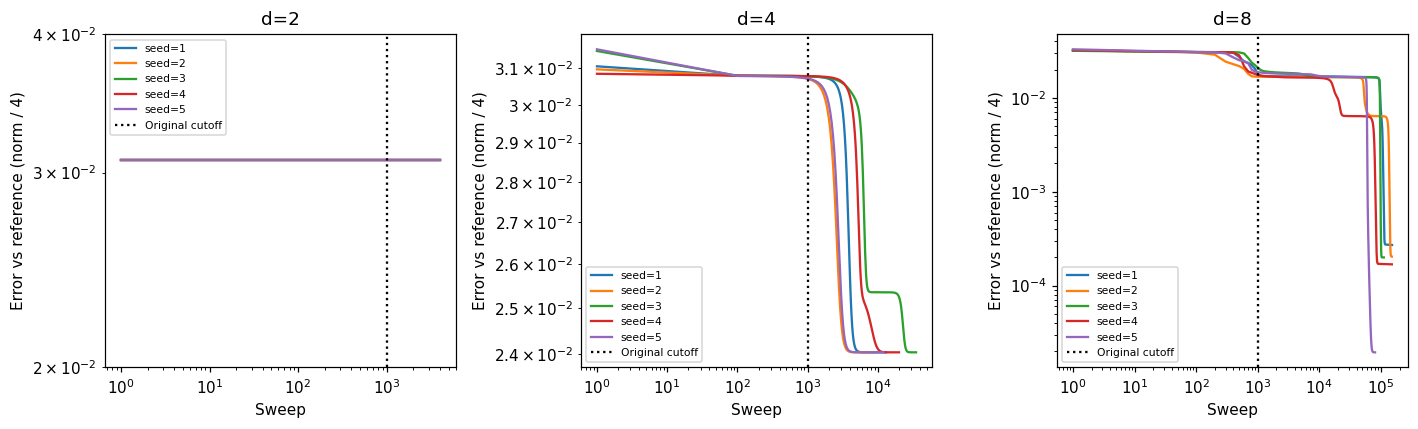

In [17]:
BASELINE_CIRCUITS=CIRCUITS.copy();BASELINE_APPROX=APPROX.copy()
def trial_circuit(depth,seed):
    prefix=f'd{depth}_seed{seed}'
    renamed={key.replace(prefix,f'h2_d{depth}',1):value for key,value in DATA.items() if key.startswith(prefix+'_MPO_')}
    return brickwall(renamed,depth)
assert CONVERGENCE['selected_converged']
fig,axes=plt.subplots(1,3,figsize=(13,4))
print('depth seed sweeps converged error_vs_MPO error_vs_exact')
for row in CONVERGENCE['rows']:
    d,seed=row['depth'],row['seed'];history=DATA[f'd{d}_seed{seed}_error_history']
    actual=Operator(trial_circuit(d,seed)).data
    np.testing.assert_allclose(rel_error(actual,REF),row['vs_mpo'],atol=1e-10)
    np.testing.assert_allclose(rel_error(actual,U),row['vs_exact'],atol=1e-10)
    # Sampled trajectories retain all 1000-sweep endpoints for stopping-rule checks.
    sweeps=DATA[f'd{d}_seed{seed}_history_sweeps']
    lookup=dict(zip(sweeps,history));stable=0
    for step in range(1000,row['sweeps']+1,1000):
        improve=max(0.,lookup[step-1000]-lookup[step]) if step>1000 else float('inf')
        stable=stable+1 if improve<1e-8 and improve/max(lookup[step],1e-16)<1e-3 else 0
    assert (stable>=3)==row['converged']
    axes[[2,4,8].index(d)].loglog(sweeps,history,label=f'seed={seed}')
    print(d,seed,row['sweeps'],row['converged'],row['vs_mpo'],row['vs_exact'])
axes[0].set_ylim(.02,.04)  # Do not magnify roundoff-sized differences between identical d=2 limits.
for d,ax in zip([2,4,8],axes):
    ax.axvline(1000,c='black',ls=':',label='Original cutoff')
    ax.set(xlabel='Sweep',ylabel='Error vs reference (norm / 4)',title=f'd={d}');ax.legend(fontsize=7)
show()
CIRCUITS={int(d):trial_circuit(int(d),row['seed']) for d,row in CONVERGENCE['selected'].items()}
APPROX={d:Operator(qc).data for d,qc in CIRCUITS.items()}
for d,row in CONVERGENCE['selected'].items():
    print('Selected depth',d,'seed',row['seed'],'sweeps',row['sweeps'],'exact error',row['vs_exact'],
          'median',row['median_vs_exact'],'range',row['range_vs_exact'])
# Polar factor is an unattainable-or-attainable lower bound within all unitaries;
# it is only a diagnostic and is not substituted for the author circuit.
print('Nearest-unitary lower bound vs MPO:',CONVERGENCE['polar_reference_lower_bound'])

### 演習9.2a

なぜ最良seedだけでなく中央値・範囲と収束履歴も表示するか。

<details><summary>解答例</summary>

局所最適化の初期値依存と、1000スイープ時点の未収束を区別するためです。収束条件を満たしても大域最適解とは限りません。参照MPOを目標とする選択規則を固定し、厳密な答えに都合のよいseed選択を避けます。

</details>

### 9.3．ゲート数と精度を比較する

比較対象は**一歩だけの** $U_*=e^{-iH\Delta t}$、$\Delta t=0.1$です。$H$は核間反発を除いた電子Hamiltonianで、
節0に出力した順序の15項（I項を含む）$H=\sum_{j=1}^{15}h_jP_j$を使います。

**(i) 厳密基準：** SciPyの密行列指数で$U_*$を計算します。Qiskitの汎用合成はその実装コストを参考表示するものです。
誤差の基準は合成前の密な$U_*$であり、汎用合成を最短の厳密回路と主張してはいません。

**(ii) term-wise Trotter：** 分割数を$n_{\rm T}=1,4,16$とし、$\tau=\Delta t/n_{\rm T}$です。
一次は$j=1,\ldots,15$の順に$e^{-ih_jP_j\tau}$を作用させてから、その一組を$n_{\rm T}$回反復します。
二次は同じ順序の半ステップに続いて逆順の半ステップを作用させます。すなわち
$$S_1(\tau)=e^{-ih_{15}P_{15}\tau}\cdots e^{-ih_1P_1\tau},\qquad U_{\rm T1}=S_1(\tau)^{n_{\rm T}},$$
$$S_2(\tau)=\left[e^{-ih_1P_1\tau/2}\cdots e^{-ih_{15}P_{15}\tau/2}\right]
\left[e^{-ih_{15}P_{15}\tau/2}\cdots e^{-ih_1P_1\tau/2}\right],\qquad U_{\rm T2}=S_2(\tau)^{n_{\rm T}}.$$
各Pauli回転は厳密に実装し、項の順序変更・可換グループの独自最適化は加えていません。
下の出力の`r`はこのTrotter分割数$n_{\rm T}$を指し、QPEのべきの指数とは別です。
参照MPOを作る100分割二次Trotterは別の用途で、資源比較の1/4/16分割と混同しないでください。

**(iii) 著者法による浅い回路：** 100分割二次Trotter＋著者MPO収縮/SVDで得た参照を目標に、
隣接ペア(0,1),(2,3)の層と(1,2)の層を交互に配置します。$d=2,4,8$層はそれぞれ3/6/12個の任意の4×4ユニタリブロックです。
9.2a節のseed=1〜5の探索終了時の結果から、参照MPOへの誤差が最小の回路を層数ごとに選びます。選択された回路はいずれも収束判定を満たしています。
1000スイープ版は初期診断として保存し、以下の資源・位相推定の主比較には収束確認後の回路を使用します。大域最適性は保証しません。

共通指標は$\epsilon_F(A)=\|A-U_*\|_F/\|U_*\|_F=\|A-U_*\|_F/4$です。
全16次元Fock空間での評価で、N=2空間だけの誤差、エネルギー誤差、状態忠実度ではありません。
制御付き発展にも使うため、全体位相を合わせ直してから誤差を小さくする操作は行いません。

厳密16×16行列の汎用合成、一・二次Trotter、著者最適化回路を同じ基底ゲートで比較します。
主図は全結合を許す合成（optimization_level=1、seed=7）です。表には、同じ論理順序を$q_0-q_1-q_2-q_3$の双方向直線結合へ配置したCX数も追加します。
初期配置は恒等、Sabre routing、最後の量子ビット置換を隣接SWAPで元へ戻す費用まで含み、コンパイル後の行列と隣接性も照合します。
固定配置へ戻す1ステップの費用であり、反復全体をまとめた配置最適化の最小値ではありません。状態準備・制御付き発展・実機ノイズは含みません。
**CX総数**と**CX層数（互いに重ならないCXは並列可）**を分けます。並列を禁止するだけの「完全直列化」ならCX総数は変わらず、CX層数が総数と同じになります。
この環境のlevel=2/3では汎用厳密行列の合成に約$10^{-5}$の差が入ったため、行列の一致を確認したlevel=1に統一しています。
収束後の一部の4×4ゲートでは、既定のWeyl分解の特殊化許容誤差による近似も検出しました。
任意2量子ビットゲートの箱は、特殊化をしないWeyl分解から0/1/2/3 CX候補を作り、行列が一致する候補だけを採用します。
必要な全体位相は実際の回路へ保持し、誤差指標から捨てません。この処理はコンパイル時のみで、著者の最適化・保存ゲートは変更しません。
この補助実装の再現性のため、Qiskit 2.4.1へ固定しています。
H₂では対称性を使った短い厳密回路も存在し、汎用合成は最小ゲート数ではありません。
**数値は収束確認後に更新した結果です。** 初期の1000スイープ版の誤差から、著者法とTrotterの優劣を結論しません。
全結合の主図と、SWAP・出力配置の復元を含む直線結合の表を区別します。
同一CX予算・同一結合制約で最適化した比較でも、実機ノイズ込みの比較でもありません。
参照MPO自体に約1.63e-5の誤差があり、収束した回路にもMPO生成誤差と回路化誤差の両方が含まれます。

Generic exact matrix   CX=  95 depth= 377 error=1.4136e-12
  line CX (restored)= 249 CX layers= 243 all-to-all CX layers= 94
Trotter 1, r=1         CX=  32 depth=  58 error=0.000363203
  line CX (restored)= 48 CX layers= 48 all-to-all CX layers= 32
Trotter 1, r=4         CX= 128 depth= 223 error=9.07726e-05
  line CX (restored)= 206 CX layers= 200 all-to-all CX layers= 122
Trotter 1, r=16        CX= 512 depth= 883 error=2.26927e-05
  line CX (restored)= 798 CX layers= 768 all-to-all CX layers= 482
Trotter 2, r=1         CX=  62 depth= 109 error=5.80469e-06
  line CX (restored)= 88 CX layers= 88 all-to-all CX layers= 62
Trotter 2, r=4         CX= 248 depth= 433 error=3.62605e-07
  line CX (restored)= 348 CX layers= 348 all-to-all CX layers= 248
Trotter 2, r=16        CX= 992 depth=1729 error=2.26621e-08
  line CX (restored)= 1400 CX layers= 1400 all-to-all CX layers= 992
Author d=2             CX=   6 depth=  29 error=0.0307897
  line CX (restored)= 6 CX layers= 4 all-to-all CX layers= 

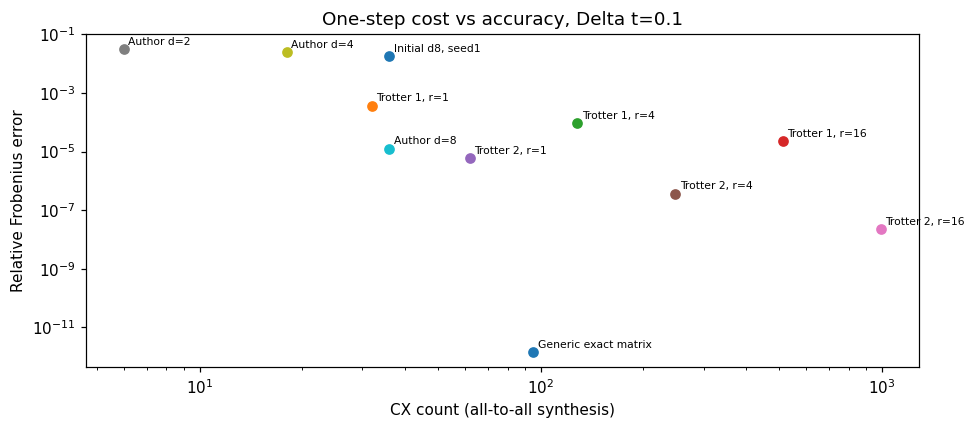

In [18]:
RESOURCE_ROWS=[];RESOURCE_LINE_ROWS={}
def record_resource(name,qc):
    compiled=compile_exact(qc)
    np.testing.assert_allclose(Operator(compiled).data,Operator(qc).data,atol=1e-10)
    err=rel_error(Operator(compiled).data,U)
    row=(name,int(compiled.count_ops().get('cx',0)),compiled.depth(),err)
    RESOURCE_ROWS.append(row);print('%-22s CX=%4d depth=%4d error=%.6g'%row)
    routed=line_resource(qc,compile_exact);RESOURCE_LINE_ROWS[name]=routed
    print('  line CX (restored)=',routed['cx_line_fixed_mapping'],'CX layers=',routed['cx_layers_line_fixed_mapping'],'all-to-all CX layers=',routed['cx_layers_all_to_all'])
qc=QuantumCircuit(4);qc.unitary(U,range(4));record_resource('Generic exact matrix',qc)
from qiskit.circuit.library import PauliEvolutionGate
from qiskit.synthesis import LieTrotter,SuzukiTrotter
for order in [1,2]:
    for reps in [1,4,16]:
        synthesis=LieTrotter(reps=reps) if order==1 else SuzukiTrotter(order=2,reps=reps)
        qc=QuantumCircuit(4);qc.append(PauliEvolutionGate(PAULI,time=DT,synthesis=synthesis),range(4))
        # Materialize the product formula: Operator(PauliEvolutionGate) alone gives exact exp.
        qc=qc.decompose()
        np.testing.assert_allclose(Operator(qc).data,dense_trotter(H,DT,reps,order),atol=1e-10)
        record_resource(f'Trotter {order}, r={reps}',qc)
for d,qc in CIRCUITS.items():record_resource(f'Author d={d}',qc)
record_resource('Initial d8, seed1',BASELINE_CIRCUITS[8])
fig,ax=plt.subplots(figsize=(9,4))
for name,cx,depth,err in RESOURCE_ROWS:
    ax.scatter(cx,max(err,1e-15));ax.annotate(name,(cx,max(err,1e-15)),fontsize=7,xytext=(3,3),textcoords='offset points')
ax.set(xscale='log',yscale='log',xlabel='CX count (all-to-all synthesis)',ylabel='Relative Frobenius error',title='One-step cost vs accuracy, Delta t=0.1');show()

### 演習9.3

浅い著者回路がTrotterより不正確な場合、この比較は失敗か。

<details><summary>解答例</summary>

収束履歴と全初期値を確認したうえで結果を報告します。今回は各層数で5初期値を試し、最良回路が同じ停止規則を満たしたことを確認して比較します。上限到達の未収束試行も別に示します。局所収束は大域最適性を保証せず、H₂での一例から一般的な優劣は結論できません。

</details>

### 9.4．第一段階と第二段階の誤差は長時間でどう現れるか

$M_{\rm ref}^L$は非ユニタリな**古典的診断**としてのみ扱い、量子回路の確率には使いません。
厳密固有状態$|j\rangle$の自己相関$a_j(L)=\langle j|A^L|j\rangle$を調べ、
$$\delta E_j(L)=-\arg\{a_j(L)e^{iE_j L\Delta t}\}/(L\Delta t)$$
を表示します。位相差は主値なので、$|\delta E|L\Delta t<\pi$を越えると折り返します。
近似発展で単一周波数でなくなる場合、この量は固有エネルギー推定ではなく時刻依存の診断です。

全演算子誤差・状態からの漏れ・位相のずれは別々の量です。MPO段階と回路段階を分けたうえで最終的な推定へ進みます。

MPO phase shifts at L=32 (Ha; diagnostic, not quantum sampling):
S0 -2.352052538812416e-05 return weight= 1.0000620925660548
S1 -9.325900566432752e-05 return weight= 0.999019264020746
S2 1.8596134669129573e-05 return weight= 1.0006369273655453
T 9.81792543634464e-05 return weight= 1.0016479815841905
Gap S0-S2 MPO phase shift= 4.211666005725373e-05
Gap S0-S1 MPO phase shift= -6.973848027620337e-05
Gap S0-T MPO phase shift= 0.00012169977975157056


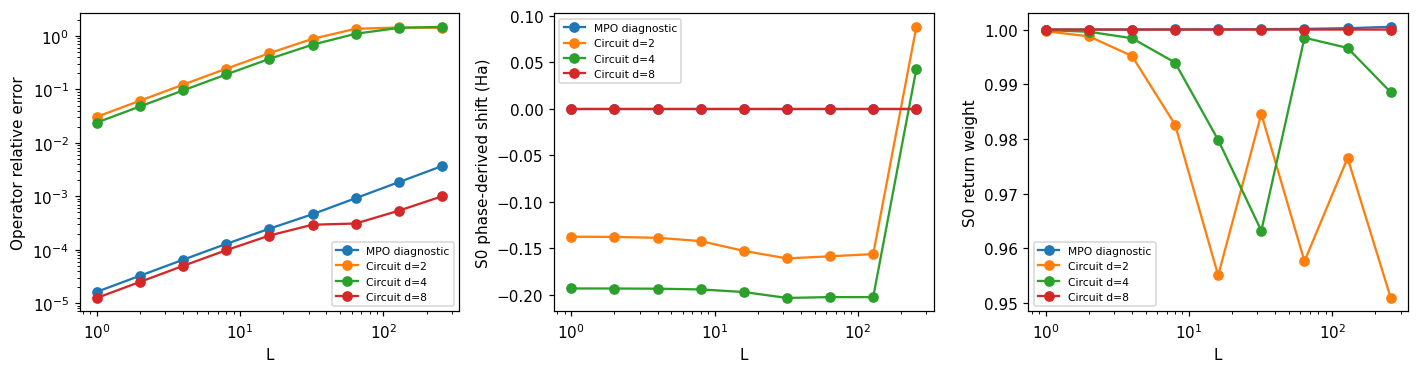

In [19]:
LENGTHS=[1,2,4,8,16,32,64,128,256]
OPERATORS={'MPO diagnostic':REF,**{f'Circuit d={d}':u for d,u in APPROX.items()}}
fig,axes=plt.subplots(1,3,figsize=(13,3.5));PHASE_DIAGNOSTICS={}
for label,a in OPERATORS.items():
    errors=[];bias=[];survival=[]
    for L in LENGTHS:
        al=np.linalg.matrix_power(a,L);ul=np.linalg.matrix_power(U,L)
        errors.append(rel_error(al,ul))
        amp=np.vdot(STATES['S0'],al@STATES['S0'])
        bias.append(-np.angle(amp*np.exp(1j*ENERGIES['S0']*L*DT))/(L*DT))
        survival.append(abs(amp)**2)
    PHASE_DIAGNOSTICS[label]={'error':errors,'bias':bias,'return_weight':survival}
    axes[0].loglog(LENGTHS,errors,'o-',label=label)
    axes[1].semilogx(LENGTHS,bias,'o-',label=label)
    axes[2].semilogx(LENGTHS,survival,'o-',label=label)
axes[0].set(ylabel='Operator relative error');axes[1].set(ylabel='S0 phase-derived shift (Ha)');axes[2].set(ylabel='S0 return weight')
for ax in axes:ax.set_xlabel('L');ax.legend(fontsize=7)
show()
# MPO-only phase diagnostics for all requested states and gaps.
print('MPO phase shifts at L=32 (Ha; diagnostic, not quantum sampling):')
mpo_shifts={}
for s in ['S0','S1','S2','T']:
    amp=np.vdot(STATES[s],np.linalg.matrix_power(REF,32)@STATES[s])
    mpo_shifts[s]=-np.angle(amp*np.exp(1j*ENERGIES[s]*32*DT))/(32*DT)
    print(s,mpo_shifts[s],'return weight=',abs(amp)**2)
for target in GAPS:print('Gap S0-'+target,'MPO phase shift=',mpo_shifts[target]-mpo_shifts['S0'])

### 9.5．時間発展近似がQPE・BPE・BPDEへ及ぼす影響

状態準備・時間計画・尤度・ショット数を固定し、時間発展だけを置き換えます。
近似回路の固有状態は元の$H$の固有状態とは限らず、厳密準備でも多周波数の信号になり得ます。
QPE/IQPEは近似ユニタリの位相を読みます。BPE/BPDEの単一余弦尤度はモデル不一致を起こし得ます。

この節の旧グリッドは約1.92 mHa刻みで、微小な偏りの定量には不十分です。以下は定性的な図として使い、精度の定量値は9.6節の精密化した推定で評価します。

主グラフは**期待カウント**$n_0=R P_0$を使う雑音なし対照です。整数の測定結果ではなく、系統的なモデル不一致を診断するための期待対数尤度です。
続けて同じショット予算の二項模擬測定も表示します。参照MPOは非ユニタリのため、この確率推定比較には投入しません。

BPE Exact S0 MAP bias Ha= 0.00019953886832579926 95% width Ha= 0.005043049901190764
BPE Trotter1 n=1 S0 MAP bias Ha= 0.00019953886832579926 95% width Ha= 0.005061856253195091
BPE Trotter2 n=1 S0 MAP bias Ha= 0.00019953886832579926 95% width Ha= 0.005050819087646874
BPE d=2 S0 MAP bias Ha= -0.15703349188995253 95% width Ha= 0.004628355877153255
BPE d=4 S0 MAP bias Ha= -0.20113543954166424 95% width Ha= 0.0048490460943057595
BPE d=8 S0 MAP bias Ha= 0.00019953886832579926 95% width Ha= 0.0050518155575373725
BPE Exact S1 MAP bias Ha= -0.00027554078180802577 95% width Ha= 0.004993630276314576
BPE Trotter1 n=1 S1 MAP bias Ha= -0.00027554078180802577 95% width Ha= 0.0051235724064566945
BPE Trotter2 n=1 S1 MAP bias Ha= -0.00027554078180802577 95% width Ha= 0.0050260911584448405
BPE d=2 S1 MAP bias Ha= -0.004110492751522199 95% width Ha= 0.004504195843726441
BPE d=4 S1 MAP bias Ha= 0.1742147738401837 95% width Ha= 0.004517506428237299
BPE d=8 S1 MAP bias Ha= -0.00027554078180802577 95% width Ha

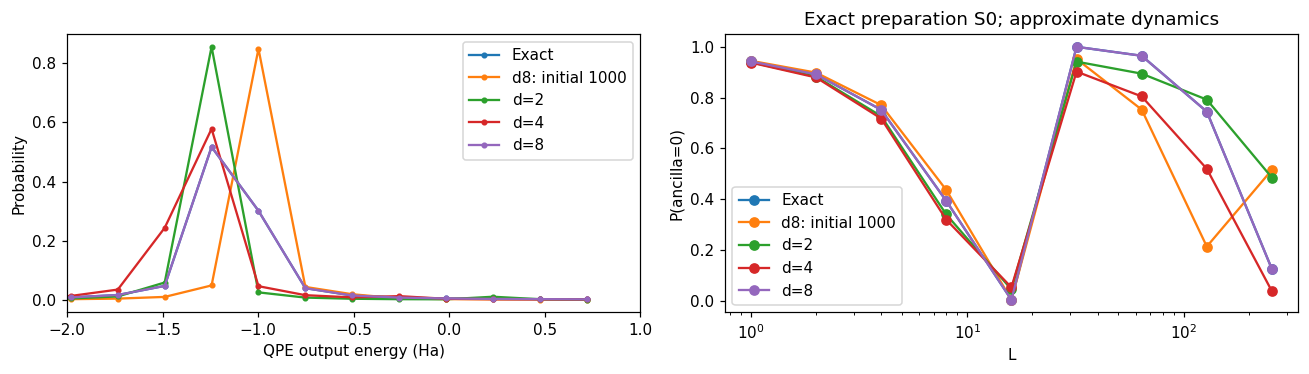

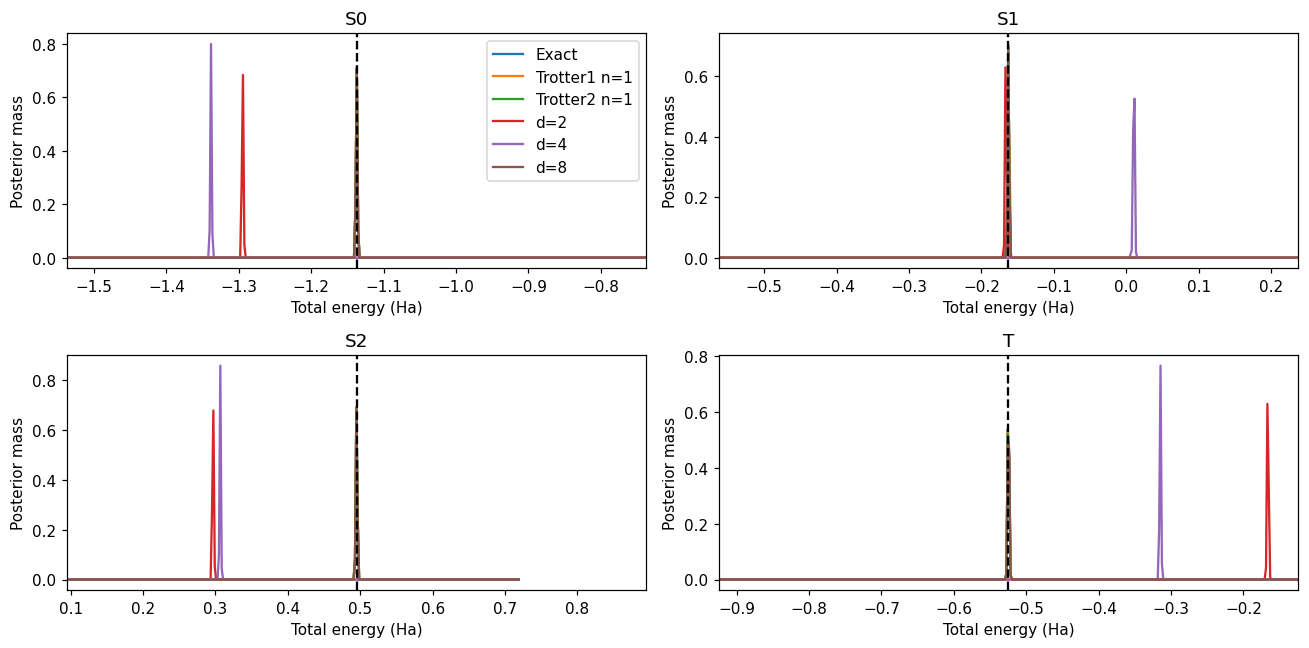

In [20]:
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for label,a in {'Exact':U,'d8: initial 1000':BASELINE_APPROX[8],**{f'd={d}':u for d,u in APPROX.items()}}.items():
    p=qpe_distribution(PREPS['S0'],a,8)
    np.testing.assert_allclose(p,iqpe_tree(STATES['S0'],a,8),atol=1e-10)
    energy=ENUC-TAU*np.arange(256)/256/DT
    axes[0].plot(energy,p,'o-',ms=3,label=label)
    signals=[bpe_probability(STATES['S0'],a,L,.3) for L in LENGTHS]
    axes[1].semilogx(LENGTHS,signals,'o-',label=label)
axes[0].set(xlim=(-2,1),xlabel='QPE output energy (Ha)',ylabel='Probability')
axes[1].set(xlabel='L',ylabel='P(ancilla=0)',title='Exact preparation S0; approximate dynamics')
for ax in axes:ax.legend()
show()
# Same initial state, settings, shots, prior and likelihood for every operator.
FINAL_OPERATORS={'Exact':U,'Trotter1 n=1':dense_trotter(H,DT,1,1),'Trotter2 n=1':dense_trotter(H,DT,1,2),**{f'd={d}':u for d,u in APPROX.items()}}
BPE_BIAS={};fig,axes=plt.subplots(2,2,figsize=(12,6))
for ax,s in zip(axes.flat,['S0','S1','S2','T']):
    for label,a in FINAL_OPERATORS.items():
        prob=lambda L,b,a=a,s=s:bpe_probability(STATES[s],a,L,b)
        hist,records=bayes(GRID,SETTINGS,prob,shots=512,expected=True)
        est,lo,hi=summary(GRID,hist[-1]);BPE_BIAS[(label,s)]=ENUC-TAU*est/DT-(ENERGIES[s]+ENUC)
        energy=ENUC-TAU*GRID/DT;ax.plot(energy,hist[-1],label=label)
        print('BPE',label,s,'MAP bias Ha=',BPE_BIAS[(label,s)],'95% width Ha=',TAU*(hi-lo)/DT)
    ax.axvline(ENERGIES[s]+ENUC,c='black',ls='--');ax.set(xlim=(ENERGIES[s]+ENUC-.4,ENERGIES[s]+ENUC+.4),xlabel='Total energy (Ha)',ylabel='Posterior mass',title=s)
axes.flat[0].legend();show()

BPDE B Exact S2 MAP bias Ha= 0.0003670237342709992 95% width Ha= 0.004917331555831101
BPDE C Exact S2 MAP bias Ha= 0.0003670237342709992 95% width Ha= 0.004917331555831101
BPDE B Trotter1 n=1 S2 MAP bias Ha= 0.0003670237342709992 95% width Ha= 0.004817757778635611
BPDE C Trotter1 n=1 S2 MAP bias Ha= 0.0003670237342709992 95% width Ha= 0.004815081921695517
BPDE B Trotter2 n=1 S2 MAP bias Ha= 0.0003670237342709992 95% width Ha= 0.004881295157428106
BPDE C Trotter2 n=1 S2 MAP bias Ha= 0.0003670237342709992 95% width Ha= 0.004881295192034738
BPDE B d=2 S2 MAP bias Ha= -0.039899971947726875 95% width Ha= 0.004929903272497189
BPDE C d=2 S2 MAP bias Ha= -0.039899971947726875 95% width Ha= 0.004344297892315074
BPDE B d=4 S2 MAP bias Ha= 0.021459259567698563 95% width Ha= 0.0041205230979126355
BPDE C d=4 S2 MAP bias Ha= 0.015706831613127692 95% width Ha= 0.0036420429473370377
BPDE B d=8 S2 MAP bias Ha= 0.0003670237342709992 95% width Ha= 0.00487016473469139
BPDE C d=8 S2 MAP bias Ha= 0.00036702

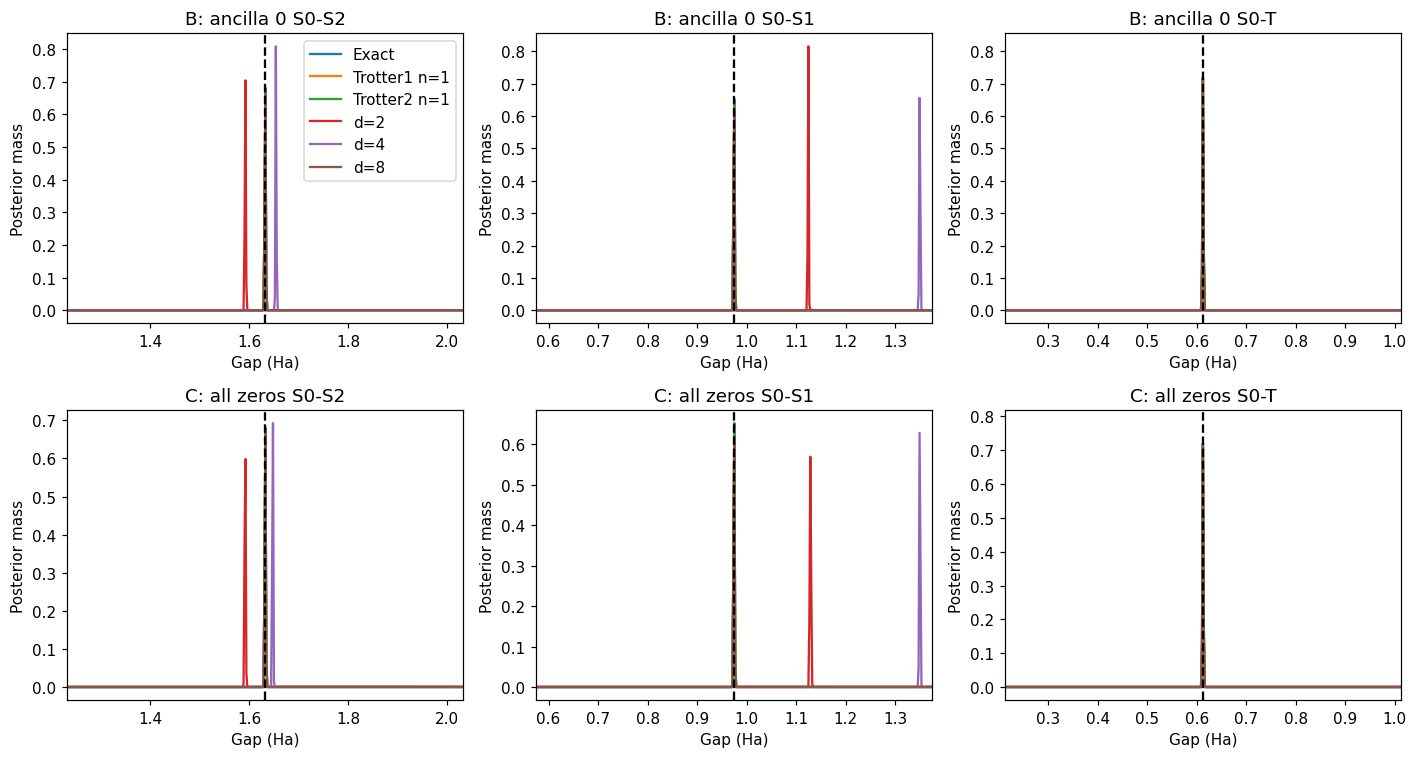

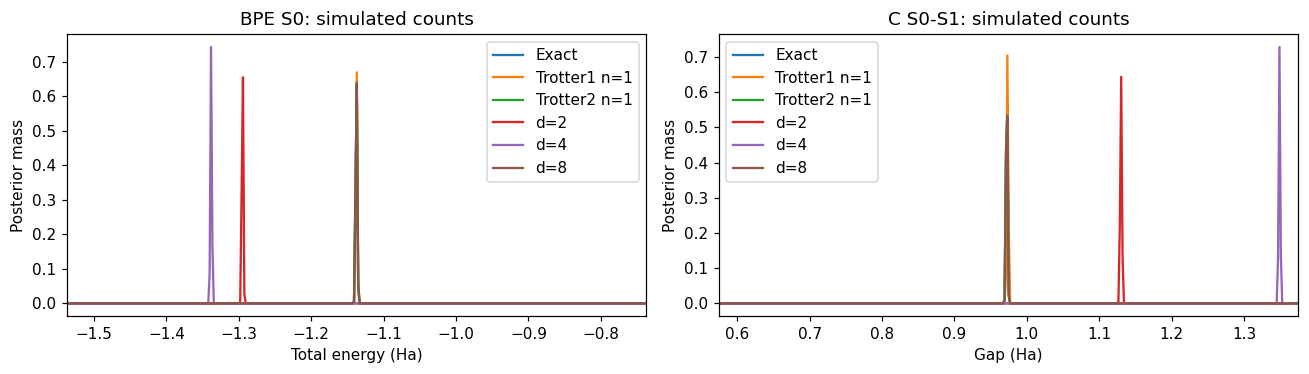

In [21]:
BPDE_BIAS={};fig,axes=plt.subplots(2,3,figsize=(13,7))
for k,target in enumerate(['S2','S1','T']):
    for label,a in FINAL_OPERATORS.items():
        for row,allzero in enumerate([False,True]):
            prob=lambda L,b,a=a,target=target,allzero=allzero:bpde_probability(target,theta,a,L,b,allzero)
            hist,records=bayes(GRID,SETTINGS,prob,shots=512,expected=True)
            est,lo,hi=summary(GRID,hist[-1]);bias=TAU*(1-est)/DT-GAPS[target]
            BPDE_BIAS[(label,target,allzero)]=bias
            axes[row,k].plot(TAU*(1-GRID)/DT,hist[-1],label=label)
            print('BPDE',('C' if allzero else 'B'),label,target,'MAP bias Ha=',bias,'95% width Ha=',TAU*(hi-lo)/DT)
    for row in [0,1]:
        axes[row,k].axvline(GAPS[target],c='black',ls='--')
        axes[row,k].set(xlim=(GAPS[target]-.4,GAPS[target]+.4),xlabel='Gap (Ha)',ylabel='Posterior mass',title=('B: ancilla 0' if row==0 else 'C: all zeros')+' S0-'+target)
axes[0,0].legend();show()
# Matched finite-shot examples for S0 BPE and S0-S1 C readout.
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for label,a in FINAL_OPERATORS.items():
    hist,_=bayes(GRID,SETTINGS,lambda L,b,a=a:bpe_probability(STATES['S0'],a,L,b),shots=512,seed=2026)
    axes[0].plot(ENUC-TAU*GRID/DT,hist[-1],label=label)
    hist,_=bayes(GRID,SETTINGS,lambda L,b,a=a:bpde_probability('S1',theta,a,L,b,True),shots=512,seed=2026)
    axes[1].plot(TAU*(1-GRID)/DT,hist[-1],label=label)
axes[0].set(xlim=(ENERGIES['S0']+ENUC-.4,ENERGIES['S0']+ENUC+.4),xlabel='Total energy (Ha)',ylabel='Posterior mass',title='BPE S0: simulated counts')
axes[1].set(xlim=(GAPS['S1']-.4,GAPS['S1']+.4),xlabel='Gap (Ha)',ylabel='Posterior mass',title='C S0-S1: simulated counts')
for ax in axes:ax.legend()
show()

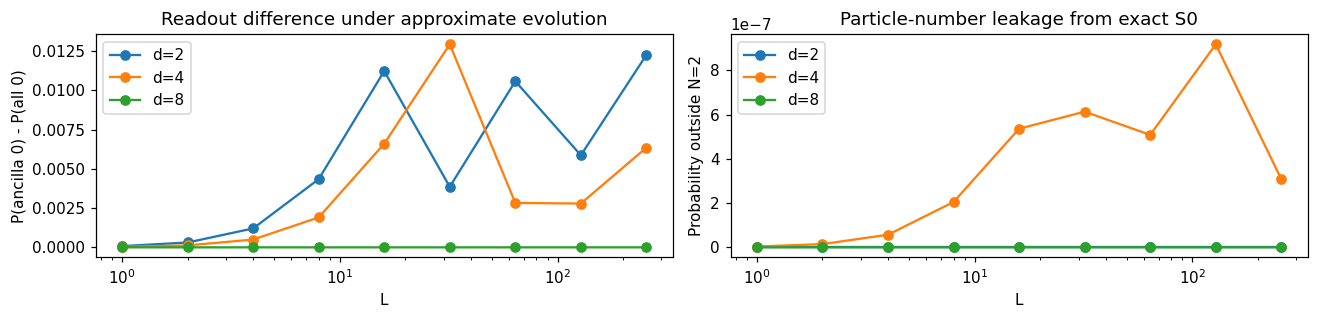

In [22]:
# Explicitly expose B/C differences and particle-number leakage; preparation stays exact.
fig,axes=plt.subplots(1,2,figsize=(12,3))
for d,a in APPROX.items():
    diff=[];leak=[]
    for L in LENGTHS:
        b=bpde_probability('S1',theta,a,L,.3,False);c=bpde_probability('S1',theta,a,L,.3,True)
        diff.append(b-c)
        evolved=np.linalg.matrix_power(a,L)@STATES['S0']
        neutral=[n for n in range(16) if n.bit_count()==2]
        leak.append(max(0.,1-float(sum(abs(evolved[neutral])**2))))
    axes[0].semilogx(LENGTHS,diff,'o-',label=f'd={d}')
    axes[1].semilogx(LENGTHS,leak,'o-',label=f'd={d}')
axes[0].set(xlabel='L',ylabel='P(ancilla 0) - P(all 0)',title='Readout difference under approximate evolution')
axes[1].set(xlabel='L',ylabel='Probability outside N=2',title='Particle-number leakage from exact S0')
for ax in axes:ax.legend()
show()

### 演習9.5

事後分布が狭く、状態準備も厳密なら、分子エネルギーを正しく求めたと言えるか。

<details><summary>解答例</summary>

時間発展回路が別のユニタリを実装していれば、その位相を精密に推定しただけかもしれません。単一周波数モデルの不一致もあります。準備を固定したうえで、MPO生成誤差・回路化誤差・長時間の信号・推定の偏りを別々に確認します。信用区間は全誤差を保証しません。

</details>

### 9.6．四つのエネルギー・六つの差を、同じ時間計画・ショット数で比較する

厳密時間発展、一次/二次term-wise Trotter（どちらも1分割）、収束した8層・seed=5回路を比べます。
主比較は固定した厳密Ry/CNOT状態準備です。Tは$M_S=0$成分です。
絶対エネルギーはBPEの補助0、**全6個の正のエネルギー差はFig. 1C型の全0確率から直接推定**します。
二つの別々のエネルギー推定を引いた値ではありません。追加の重ね合わせ準備も同じRy/CNOTの厳密エンコーダで作り、全ての組合せを照合します。

各時間計画は9個のL×2個の補正位相$\beta=\pi/5,\pi/5-\pi/2$、各512ショット、合計**9216ショット/推定対象**です。
全方式で同じ計画・事前・尤度・推定器・乱数seedを使います。総ショット数は時間計画間でも固定し、総発展時間の違いを併記します。

| 計画 | Lのリスト |
|---|---|
| Lmax256 | 1,2,4,8,16,32,64,128,256 |
| Lmax4096 | 1,4,8,16,64,256,512,1024,4096 |
| Lmax16384 | 1,4,16,32,128,512,1024,4096,16384 |

L=1を残し、短時間の情報で周期の候補を識別してから長時間を使います。
探索範囲は全方式共通の電子エネルギー(−2,0) Ha、差(0,2) Haに一様事前を置きます。厳密な答えを中心とする狭い事前ではありません。
範囲全体の格子探索で最大値を見つけ、その近傍で連続MAP（この一様事前ではMLEと同じ）へ精密化します。
二倍密な格子からの推定と2e-8 Ha以内で一致することも確認します。核間反発は最後に絶対エネルギーへ加えます。

- **期待カウントのずれ：** $n_0=512P_0$を用いた雑音なし対照。整数ショットの測定結果ではなく、系統的なモデル不一致を調べる期待対数尤度です。
- **RMSE：** 256回の二項模擬実験で$\sqrt{\langle(\hat E-E)^2\rangle}$を計算。統計変動と推定の偏りを含みます。
- **推定値の95%範囲：** 256回の推定値の2.5–97.5百分位。単一実験のベイズ信用区間とは異なります。

表は期待カウントのずれ / 模擬実験のRMSEをmHaで示します（1 mHa=0.001 Ha）。

In [23]:
PRECISION_STATES={s:STATES[s] for s in ['S0','S1','S2','T']}
PRECISION_OPERATORS={'Exact':U,'Trotter1':dense_trotter(H,DT,1,1),'Trotter2':dense_trotter(H,DT,1,2),'Author8':APPROX[8]}
for lo,hi in PRECISION_PAIRS:
    prep=pair_preparation(lo,hi,theta)
    np.testing.assert_allclose(Statevector.from_instruction(prep).data,np.r_[STATES[lo],STATES[hi]]/np.sqrt(2),atol=1e-12)
    assert set(prep.count_ops())<={'ry','cx'}
    for u in PRECISION_OPERATORS.values():
        for L,beta in [(1,.2),(256,-.7),(16384,.3)]:
            up=np.linalg.matrix_power(u,L);qc=prep.copy();qc.unitary(up,range(4));qc.p(beta,4);qc.compose(prep.inverse(),inplace=True)
            p=Statevector.from_instruction(qc).probabilities()[0]
            expected=abs(np.vdot(STATES[lo],up@STATES[lo])+np.exp(1j*beta)*np.vdot(STATES[hi],up@STATES[hi]))**2/4
            np.testing.assert_allclose(p,expected,atol=1e-11)
PRECISION,PRECISION_SAMPLES=run_precision(H,ENUC,DT,PRECISION_STATES,PRECISION_OPERATORS,progress=print)
assert PRECISION['settings']==PRECISION_SAVED['settings']
assert PRECISION_SAVED['author8_selection']['seed']==CONVERGENCE['selected']['8']['seed']
for new,saved in zip(PRECISION['inference'],PRECISION_SAVED['inference']):
    assert (new['method'],new['plan'],new['target'])==(saved['method'],saved['plan'],saved['target'])
    np.testing.assert_allclose([new['expected_mle'],new['mc_rmse']],[saved['expected_mle'],saved['mc_rmse']],atol=2e-8)
print('All four methods, three plans, four energies and six direct gaps reproduced.')

Exact Lmax256: 4 energies + 6 direct gaps passed
Exact Lmax4096: 4 energies + 6 direct gaps passed
Exact Lmax16384: 4 energies + 6 direct gaps passed
Trotter1 Lmax256: 4 energies + 6 direct gaps passed
Trotter1 Lmax4096: 4 energies + 6 direct gaps passed
Trotter1 Lmax16384: 4 energies + 6 direct gaps passed
Trotter2 Lmax256: 4 energies + 6 direct gaps passed
Trotter2 Lmax4096: 4 energies + 6 direct gaps passed
Trotter2 Lmax16384: 4 energies + 6 direct gaps passed
Author8 Lmax256: 4 energies + 6 direct gaps passed
Author8 Lmax4096: 4 energies + 6 direct gaps passed
Author8 Lmax16384: 4 energies + 6 direct gaps passed
All four methods, three plans, four energies and six direct gaps reproduced.


Lmax256 {'Lmax': 256, 'tmax': 25.6, 'sum_shots_L': 523264, 'sum_shots_time': 52326.4} shots/target=9216; cells are bias / RMSE in mHa
Lmax4096 {'Lmax': 4096, 'tmax': 409.6, 'sum_shots_L': 6124544, 'sum_shots_time': 612454.4} shots/target=9216; cells are bias / RMSE in mHa
Lmax16384 {'Lmax': 16384, 'tmax': 1638.4, 'sum_shots_L': 22729728, 'sum_shots_time': 2272972.8000000003} shots/target=9216; cells are bias / RMSE in mHa
Longest-plan Author8 point values and MC mean +/- empirical standard deviation:
S0 expected-count MAP= -1.1372872552571311 MC mean= -1.1372875945646435 MC std= 1.9221347853020356e-05 MC 95% estimate range= [-1.1373249894626882, -1.1372555653573801]
S1 expected-count MAP= -0.16284681047661187 MC mean= -0.16284623031656664 MC std= 1.8053713215792243e-05 MC 95% estimate range= [-0.1628829652612125, -0.16281081182940293]
S2 expected-count MAP= 0.4950339563596013 MC mean= 0.4950373689947905 MC std= 1.87689963270374e-05 MC 95% estimate range= [0.49500319279290445, 0.4950744

Target,Exact value / Ha,Exact,Trotter1,Trotter2,Author8
S0,-1.1373060358,+0.0000 / 1.1110,+0.0440 / 1.1334,+0.0165 / 1.0907,+0.0188 / 1.0907
S1,-0.1627531558,-0.0000 / 1.0448,+0.4245 / 1.1868,-0.0461 / 1.0482,-0.0936 / 1.0648
S2,0.4950577416,+0.0000 / 1.1559,-0.0457 / 1.0887,-0.0165 / 1.1484,-0.0238 / 1.1530
T,-0.5246155554,-0.0000 / 1.0963,+0.0252 / 1.0256,+0.0461 / 1.0823,+0.0987 / 1.1196
T-S0,0.6126904804,+0.0000 / 1.1151,-0.0374 / 1.1197,+0.0296 / 1.1164,+0.0799 / 1.0860
S1-S0,0.9745528800,-0.0000 / 1.1057,-0.0433 / 1.0704,-0.0626 / 1.0853,-0.1124 / 1.0991
S2-S0,1.6323637774,-0.0000 / 0.9948,-0.0855 / 1.0169,-0.0331 / 1.0316,-0.0426 / 1.0323
S1-T,0.3618623996,+0.0000 / 1.0060,-0.0217 / 1.0713,-0.0922 / 1.0062,-0.1923 / 1.1018
S2-T,1.0196732970,-0.0000 / 1.0556,-0.0089 / 0.9947,-0.0626 / 1.0213,-0.1224 / 1.0258
S2-S1,0.6578108974,-0.0000 / 1.1118,-0.0718 / 1.0640,+0.0296 / 1.0913,+0.0699 / 1.1007


Target,Exact value / Ha,Exact,Trotter1,Trotter2,Author8
S0,-1.1373060358,-0.0000 / 0.0755,+0.0425 / 0.0826,+0.0165 / 0.0758,+0.0188 / 0.0768
S1,-0.1627531558,-0.0000 / 0.0756,+0.0046 / 0.0737,-0.0461 / 0.0879,-0.0937 / 0.1143
S2,0.4950577416,-0.0000 / 0.0950,-0.0428 / 0.1002,-0.0165 / 0.0939,-0.0238 / 0.0913
T,-0.5246155554,-0.0000 / 0.0811,+0.0097 / 0.0842,+0.0461 / 0.0854,+0.0987 / 0.1225
T-S0,0.6126904804,+0.0000 / 0.0756,-0.0414 / 0.0882,+0.0296 / 0.0806,+0.0799 / 0.1064
S1-S0,0.9745528800,+0.0000 / 0.0738,-0.0417 / 0.0828,-0.0626 / 0.0931,-0.1124 / 0.1324
S2-S0,1.6323637774,-0.0000 / 0.0732,-0.0847 / 0.1249,-0.0331 / 0.0877,-0.0426 / 0.0918
S1-T,0.3618623996,-0.0000 / 0.0858,-0.0000 / 0.0892,-0.0922 / 0.1183,-0.1923 / 0.1980
S2-T,1.0196732970,-0.0000 / 0.0787,-0.0411 / 0.0914,-0.0626 / 0.0975,-0.1224 / 0.1449
S2-S1,0.6578108974,-0.0000 / 0.0755,-0.0333 / 0.0808,+0.0296 / 0.0807,+0.0699 / 0.1045


Target,Exact value / Ha,Exact,Trotter1,Trotter2,Author8
S0,-1.1373060358,-0.0000 / 0.0189,+0.0424 / 0.0461,+0.0165 / 0.0248,+0.0188 / 0.0266
S1,-0.1627531558,-0.0000 / 0.0197,-0.0014 / 0.0179,-0.0461 / 0.0492,-0.0937 / 0.0948
S2,0.4950577416,+0.0000 / 0.0177,-0.0425 / 0.0441,-0.0165 / 0.0226,-0.0238 / 0.0277
T,-0.5246155554,-0.0000 / 0.0183,+0.0009 / 0.0166,+0.0461 / 0.0486,+0.0987 / 0.1002
T-S0,0.6126904804,+0.0000 / 0.0176,-0.0430 / 0.0460,+0.0296 / 0.0363,+0.0799 / 0.0815
S1-S0,0.9745528800,-0.0000 / 0.0192,-0.0367 / 0.0463,-0.0626 / 0.0707,-0.1124 / 0.1099
S2-S0,1.6323637774,+0.0000 / 0.0175,-0.0847 / 0.0862,-0.0331 / 0.0390,-0.0426 / 0.0462
S1-T,0.3618623996,+0.0000 / 0.0221,-0.0000 / 0.0210,-0.0922 / 0.0924,-0.1923 / 0.1914
S2-T,1.0196732970,-0.0000 / 0.0181,-0.0401 / 0.0468,-0.0626 / 0.0660,-0.1224 / 0.1286
S2-S1,0.6578108974,+0.0000 / 0.0183,-0.0416 / 0.0457,+0.0296 / 0.0360,+0.0699 / 0.0748


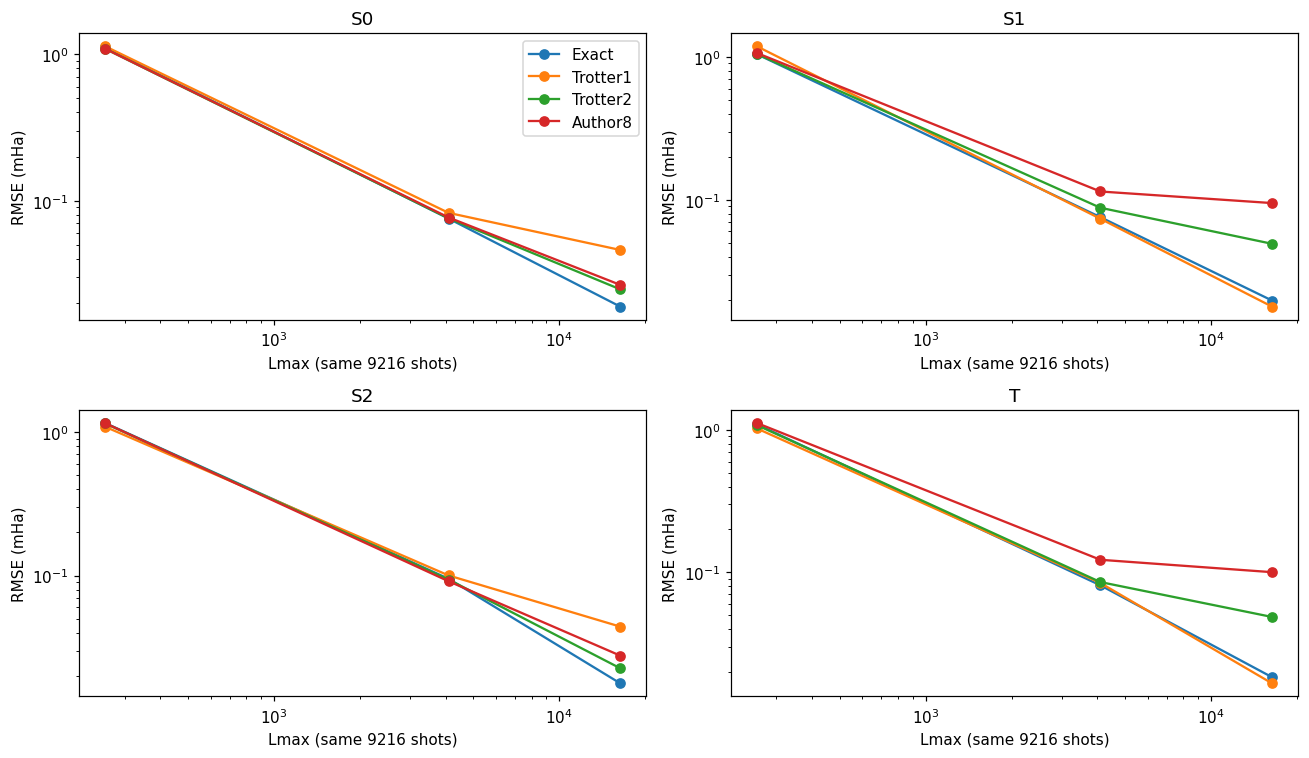

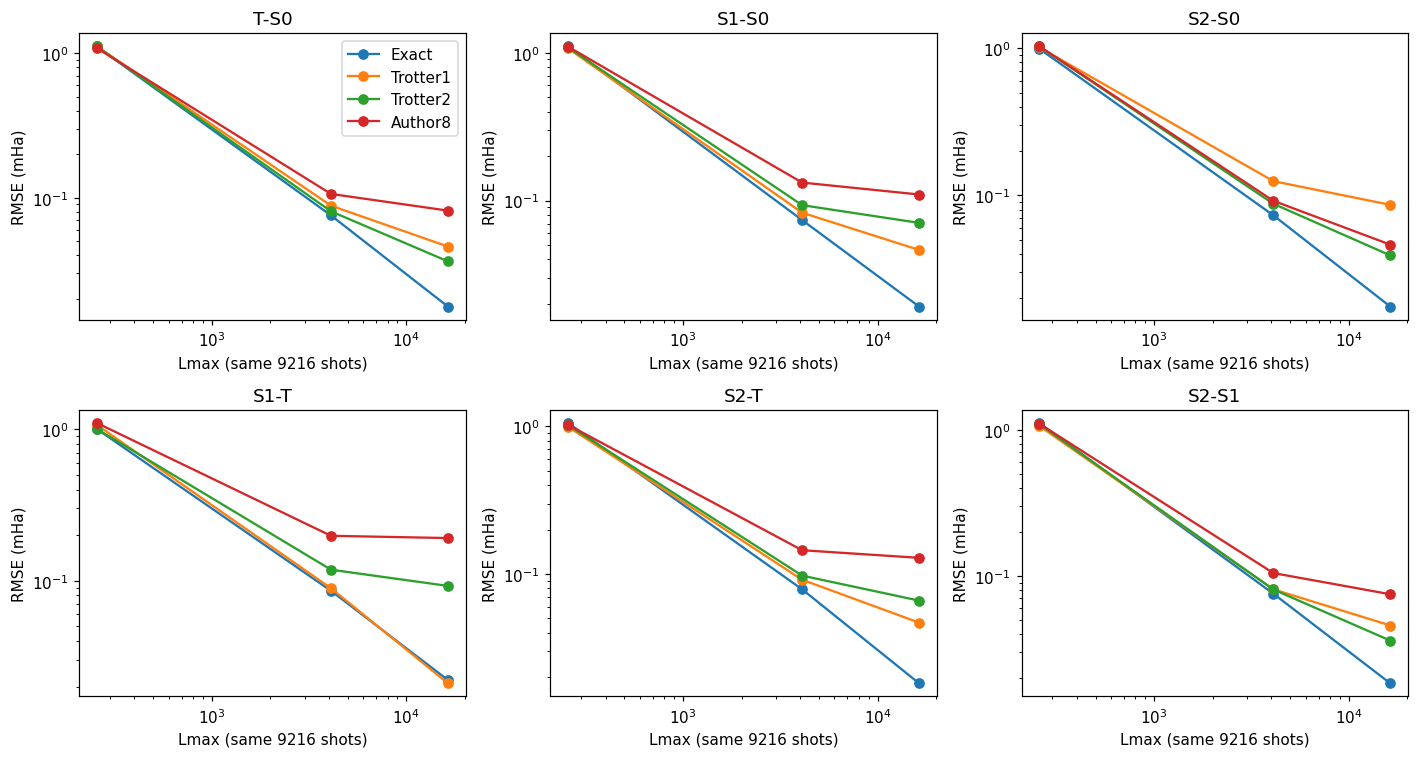

In [24]:
from IPython.display import HTML
METHODS=['Exact','Trotter1','Trotter2','Author8']
TARGETS=['S0','S1','S2','T']+[f'{hi}-{lo}' for lo,hi in PRECISION_PAIRS]
def precision_row(method,plan,target):
    return next(r for r in PRECISION['inference'] if (r['method'],r['plan'],r['target'])==(method,plan,target))
for plan in PRECISION_PLANS:
    resource=PRECISION['settings']['plan_resources'][plan]
    print(plan,resource,'shots/target=9216; cells are bias / RMSE in mHa')
    html='<table><tr><th>Target</th><th>Exact value / Ha</th>'+''.join(f'<th>{m}</th>' for m in METHODS)+'</tr>'
    for target in TARGETS:
        html+=f'<tr><td>{target}</td><td>{precision_row("Exact",plan,target)["true_value"]:.10f}</td>'
        for method in METHODS:
            row=precision_row(method,plan,target)
            html+=f'<td>{1000*row["systematic_bias"]:+.4f} / {1000*row["mc_rmse"]:.4f}</td>'
        html+='</tr>'
    display(HTML(html+'</table>'))
print('Longest-plan Author8 point values and MC mean +/- empirical standard deviation:')
for target in TARGETS:
    r=precision_row('Author8','Lmax16384',target)
    print(target,'expected-count MAP=',r['expected_mle'],'MC mean=',r['mc_mean'],'MC std=',r['mc_std'],'MC 95% estimate range=',r['mc_estimate_95_range'])
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,target in zip(axes.flat,['S0','S1','S2','T']):
    for method in METHODS:
        y=[1000*precision_row(method,p,target)['mc_rmse'] for p in PRECISION_PLANS]
        ax.loglog([256,4096,16384],y,'o-',label=method)
    ax.set(xlabel='Lmax (same 9216 shots)',ylabel='RMSE (mHa)',title=target)
axes.flat[0].legend();show()
fig,axes=plt.subplots(2,3,figsize=(13,7))
for ax,(lo,hi) in zip(axes.flat,PRECISION_PAIRS):
    target=f'{hi}-{lo}'
    for method in METHODS:
        ax.loglog([256,4096,16384],[1000*precision_row(method,p,target)['mc_rmse'] for p in PRECISION_PLANS],'o-',label=method)
    ax.set(xlabel='Lmax (same 9216 shots)',ylabel='RMSE (mHa)',title=target)
axes.flat[0].legend();show()

### 9.7．長時間反復で蓄積するのは位相のずれ

$\|A^L-U^L\|\le L\|A-U\|$は上限で、実際の誤差が常にL倍になるわけではありません。
近似ユニタリの固有エネルギーが$\delta E$ずれると、位相差は$-\delta E L\Delta t$となります。
エネルギー換算した偏りはほぼ一定でも、統計誤差は長時間化で小さくなるため、偏りが目立つようになります。
状態の戻り確率が高くても、正しい位相を保っているとは限りません。

演算子誤差、S₀/S₁/S₂/Tの自己相関の位相差、戻り確率の損失を分けて表示します。
数値はそれぞれの一歩の演算子をL回反復し、同じ時刻の厳密$e^{-iHL\Delta t}$と比較しています。

L, method, operator relative error, largest state phase error(rad), largest survival loss
1 Exact 0.0 1.2312470120096478e-17 2.220446049250313e-16
1 Trotter1 0.00036320305451074475 1.8435036127269635e-05 6.668272599652525e-07
1 Trotter2 5.8046943813633716e-06 4.610853687290774e-06 2.3191293330171447e-10
1 Author8 1.2516264859010251e-05 9.865081117950347e-06 4.09787093147429e-10
256 Exact 1.1485448699966419e-14 3.0808332576810864e-15 1.2212453270876722e-14
256 Trotter1 0.01609534707849762 0.001072643365151393 0.002024011171091966
256 Trotter2 0.0004529600158734024 0.0011802837014133665 4.1427130392790446e-08
256 Author8 0.0009992806813196177 0.0025255185863589046 1.9097049364091845e-07
4096 Exact 1.8357153913054204e-13 4.912627921822477e-14 1.9473311851925246e-13
4096 Trotter1 0.016716061962654457 0.017359689600662077 0.0018794521438518785
4096 Trotter2 0.007093784057429126 0.01888450683874861 3.888883648439645e-08
4096 Author8 0.015597869480668894 0.04040801522629812 1.1429203528035004

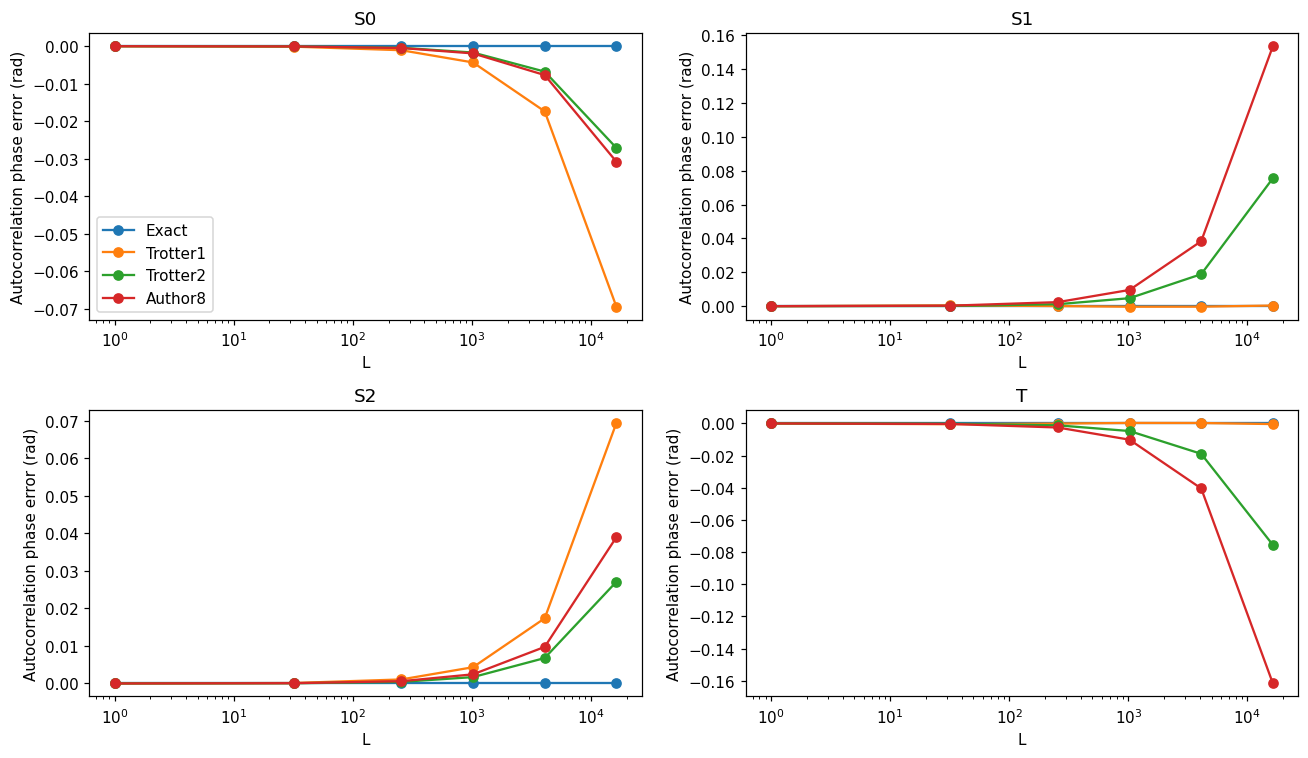

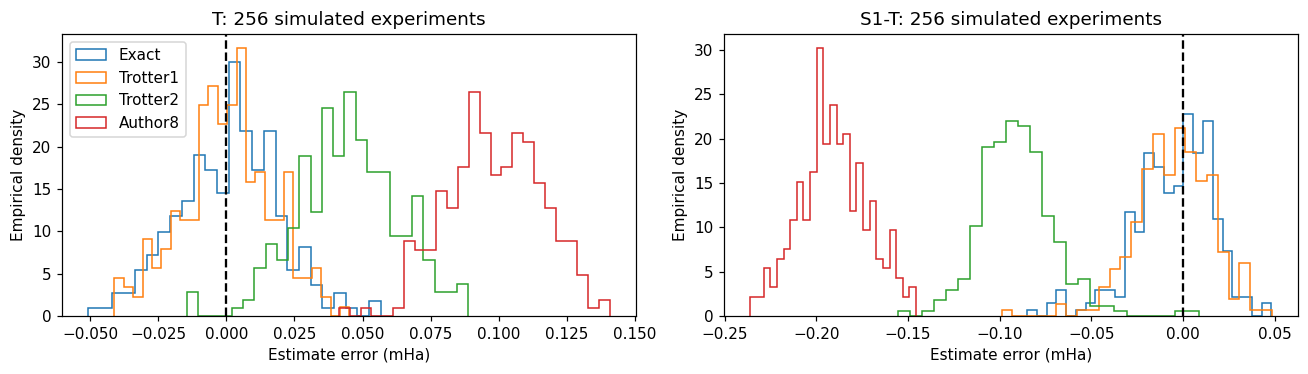

In [25]:
print('L, method, operator relative error, largest state phase error(rad), largest survival loss')
for L in [1,256,4096,16384]:
    for method in METHODS:
        rows=[r for r in PRECISION['long_time'] if r['method']==method and r['L']==L]
        print(L,method,rows[0]['operator_relative_error'],max(abs(r['phase_error_rad']) for r in rows),max(r['survival_loss'] for r in rows))
fig,axes=plt.subplots(2,2,figsize=(12,7))
for ax,target in zip(axes.flat,['S0','S1','S2','T']):
    for method in METHODS:
        rows=[r for r in PRECISION['long_time'] if r['method']==method and r['state']==target]
        ax.semilogx([r['L'] for r in rows],[r['phase_error_rad'] for r in rows],'o-',label=method)
    ax.set(xlabel='L',ylabel='Autocorrelation phase error (rad)',title=target)
axes.flat[0].legend();show()
fig,axes=plt.subplots(1,2,figsize=(12,3.5))
for ax,target in zip(axes,['T','S1-T']):
    truth=precision_row('Exact','Lmax16384',target)['true_value']
    for method in METHODS:
        values=1000*(PRECISION_SAMPLES[f'{method}_Lmax16384_{target}']-truth)
        ax.hist(values,bins=25,histtype='step',density=True,label=method)
    ax.axvline(0,c='black',ls='--');ax.set(xlabel='Estimate error (mHa)',ylabel='Empirical density',title=target+': 256 simulated experiments')
axes[0].legend();show()
# Exact dynamics gives zero expected-count bias independently of shot noise.
for row in PRECISION['inference']:
    if row['method']=='Exact':
        assert abs(row['systematic_bias'])<2e-8
        assert .7<row['mc_rmse']/row['local_ideal_fisher_sigma']<1.4
print('Continuous refinement, pair circuits, exact-model zero bias and finite-shot precision checks passed.')

### 演習9.7

一歩の演算子誤差が小さい回路は、全てのエネルギー差でも常によいか。

<details><summary>解答例</summary>

必ずしもそうではありません。全16次元での誤差は、選んだ固有位相のずれと同じ指標ではありません。また差では二状態のずれが相殺または加算されます。この例でもTrotterと著者回路の順位は推定対象によって変わります。

</details>

## 10．出典・再現範囲・読み取れたこと

- [Kanno et al., PNAS 122, e2425026122 (2025)](https://doi.org/10.1073/pnas.2425026122)：参照MPO生成、brick-wall回路最適化、Fig. 1の読出し。
- [著者コード TQPDE_open](https://github.com/sk888ks/TQPDE_open/tree/9cd88464c5c50dda783150661813609092d7f2b6)：固定コミット、Juliaコアをバイト同一で使用。LGPL-3.0を保持。
- [Qiskit Nature公式：JWとParity](https://qiskit-community.github.io/qiskit-nature/tutorials/06_qubit_mappers.html)
- [PySCF公式：Full-CI](https://pyscf.org/user/ci.html)
- [Dobšíček et al.：IQPE](https://arxiv.org/abs/quant-ph/0610214)
- [Wiebe–Granade：Bayesian phase estimation](https://arxiv.org/abs/1508.00869)

著者に合わせた部分：二次Trotter＋MPO収縮/SVD、環境テンソル＋SVDの回路最適化、保存ゲートの順序。
変更した部分：H₂模型、blocked spin order、厳密Ry/CNOT準備、層数比較、教育用グリッド推定、実行バックエンド。
Julia環境は既存H₄教材の固定環境を利用し、著者実機実験・Fire Opal・Gaussian推定更新は再現しません。

1000スイープの一初期値だけの比較は撤回し、各層数5初期値を追加探索し、最良回路の局所収束を確認した結果へ更新しました。
収束履歴・seed間の分布・最良回路を併記します。厳密準備でも時間発展の近似は推定を変え、信用区間は全誤差を保証しません。
基底内の厳密解と、実在分子・実験値に対する正確さは別です。

In [26]:
print(json.dumps({k:v for k,v in PROVENANCE.items() if k!='sha256'},indent=2))
print('Embedded array payload SHA256:',hashlib.sha256(base64.b64decode(PAYLOAD)).hexdigest())

{
  "upstream_url": "https://github.com/sk888ks/TQPDE_open",
  "upstream_commit": "9cd88464c5c50dda783150661813609092d7f2b6",
  "license": "LGPL-3.0",
  "upstream_core_sha256": "4b643396638cd85cbddef616d8fdfc6b663ed2bbea39e3eee4e2ffa4381423a8",
  "upstream_core_byte_identical": true,
  "julia": "julia version 1.11.1",
  "ITensors": "0.6.16",
  "PyCall": "1.96.4",
  "Infiltrator": "1.7.0",
  "python": "3.12.7",
  "numpy": "2.4.6",
  "scipy": "1.18.0",
  "qiskit": "2.4.1",
  "reference_orientation": "raw author reference is U_adjoint; use conjugate transpose for physical evolution",
  "settings": {
    "dt": 0.1,
    "trotter_slices": 100,
    "svd_cutoff": 1e-12,
    "depths": [
      2,
      4,
      8
    ],
    "baseline_sweeps": 1000,
    "random_initialization": true,
    "baseline_seed": 1,
    "convergence": {
      "criterion": {
        "check_interval": 1000,
        "absolute_error_improvement": 1e-08,
        "relative_error_improvement": 0.001,
        "consecutive_windows

## 付録A．分子積分から削減なしJW行列を再生成する

PySCFのRHF分子軌道積分から、JWの生成・消滅演算子を16次元行列として明示します。
$$H=\sum_{pq\sigma}h_{pq}a^\dagger_{p\sigma}a_{q\sigma}
+\frac12\sum_{pqrs\sigma\tau}(pq|rs)a^\dagger_{p\sigma}a^\dagger_{r\tau}a_{s\tau}a_{q\sigma}.$$
独立したPySCF Full-CIで中性状態の4エネルギーとスピンを照合します。
主条件に加え、1.5 Å、2.5 Åで厳密状態準備の同じ形が成立することを確認します。
MPO・回路最適化を実行済みなのは0.735 Åだけです。

In [27]:
from pyscf import gto,scf,ao2mo,fci
def regenerate(distance=0.735):
    mol = gto.M(atom=f'H 0 0 0; H 0 0 {distance}', basis='sto-3g', unit='Angstrom', verbose=0)
    mf = scf.RHF(mol).run(conv_tol=1e-12)
    assert mf.converged
    c = mf.mo_coeff
    h1 = c.T @ mf.get_hcore() @ c
    eri = ao2mo.restore(1, ao2mo.kernel(mol, c), 2)
    annihilation = []
    for p in range(4):
        a = np.zeros((16, 16))
        for n in range(16):
            if n >> p & 1:
                a[n ^ (1 << p), n] = (-1)**((n & ((1 << p)-1)).bit_count())
        annihilation.append(a)
    h = np.zeros((16, 16))
    for p in range(2):
        for q in range(2):
            for spin in range(2):
                h += h1[p,q] * annihilation[p+2*spin].T @ annihilation[q+2*spin]
            for r in range(2):
                for s in range(2):
                    for sigma in range(2):
                        for tau in range(2):
                            h += .5*eri[p,q,r,s] * annihilation[p+2*sigma].T @ annihilation[r+2*tau].T @ annihilation[s+2*tau] @ annihilation[q+2*sigma]
    energies, cis = fci.FCI(mf).kernel(nroots=4)
    spins = [fci.spin_op.spin_square(ci, 2, (1,1))[0] for ci in cis]
    indices = [5, 6, 9, 10]
    np.testing.assert_allclose(np.linalg.eigvalsh(h[np.ix_(indices, indices)])+mol.energy_nuc(), energies, atol=1e-10)
    np.testing.assert_allclose(spins, [0,2,0,0], atol=1e-9)
    return h, float(mol.energy_nuc()), np.asarray(energies), np.asarray(spins)

import pyscf
print('PySCF',pyscf.__version__)
for distance in [.735,1.5,2.5]:
    h,nuclear,energies,spins=regenerate(distance)
    if distance==.735:
        np.testing.assert_allclose(h,H,atol=1e-10)
        np.testing.assert_allclose(nuclear,ENUC,atol=1e-10)
    angle=-np.arctan2(2*h[5,10],h[10,10]-h[5,5])
    for s,j in [('S0',0),('S1',2),('S2',3),('T',1)]:
        state=Statevector.from_instruction(state_prep(s,angle)).data
        assert np.linalg.norm(h@state-(energies[j]-nuclear)*state)<1e-9
    for target in ['S2','S1','T']:
        expected=np.r_[Statevector.from_instruction(state_prep('S0',angle)).data,Statevector.from_instruction(state_prep(target,angle)).data]/np.sqrt(2)
        np.testing.assert_allclose(Statevector.from_instruction(joint_prep(target,angle)).data,expected,atol=1e-12)
    print('R=',distance,'theta=',angle,'FCI total energies=',energies,'S²=',spins)
print('All molecular regeneration and exact preparation checks passed.')

PySCF 2.13.1
R= 0.735 theta= -0.22353699826765971 FCI total energies= [-1.13730604 -0.52461556 -0.16275316  0.49505774] S²= [0. 2. 0. 0.]
R= 1.5 theta= -0.7266909976376382 FCI total energies= [-0.99814935 -0.89058478 -0.43151291 -0.3071925 ] S²= [0. 2. 0. 0.]
R= 2.5 theta= -1.3808140660658679 FCI total energies= [-0.93605492 -0.93163909 -0.36721899 -0.36129348] S²= [0. 2. 0. 0.]
All molecular regeneration and exact preparation checks passed.


### 演習付録

なぜJW行列の全固有値と、PySCFの中性Full-CIの4根をそのまま照合しないか。

<details><summary>解答例</summary>

JWの16次元には電子数0,1,3,4や、異なるSzの状態も含むためです。中性Nalpha=Nbeta=1の4次元ブロックで照合し、さらにS²で一重項・三重項を識別します。

</details>

In [28]:
np.testing.assert_allclose([ENERGIES[s]+ENUC for s in ['S0','T','S1','S2']],DATA['fci_energies'],atol=1e-10)
np.testing.assert_allclose(contract_author_mpo(DATA),REF_ADJOINT,atol=1e-12)
for d in APPROX:
    assert unitary_defect(APPROX[d])<1e-10
    np.testing.assert_allclose(rel_error(APPROX[d],U),CONVERGENCE['selected'][str(d)]['vs_exact'],atol=1e-10)
assert PROVENANCE['upstream_core_byte_identical'] is True
print('全セル完了：JW・Full-CI・厳密Ry/CNOT準備・QFT・QPE/IQPE・BPE/BPDE・B/C読出し・脱分極・著者MPOと回路の入出力を照合しました。')

全セル完了：JW・Full-CI・厳密Ry/CNOT準備・QFT・QPE/IQPE・BPE/BPDE・B/C読出し・脱分極・著者MPOと回路の入出力を照合しました。
